# Revisión y evaluación de métodos de aprendizaje automático para la predicción del rendimiento energético y SOH en autobuses eléctricos

**Trabajo de fin de máster**

**Nombre y apellidos:** ANA MILENA VALENCIA MORENO  
**Usuario VIU:** avalenciam@student.universidadviu.com  
**Entorno:** Google Colab

---

## Objetivo del proyecto

Evaluar e implementar modelos de predicción del rendimiento energético (km recorridos por kWh netos consumidos) de autobuses eléctricos de transporte de pasajeros, comparar los algoritmos identificados en la revisión bibliográfica y seleccionar el mejor modelo con un criterio fijado de antemano.

## Diseño experimental (decisión central de este cuaderno)

Se dispone de tres conjuntos de datos de 7.200 registros (30 jornadas × 240 minutos), una por autobús:

| Archivo | Autobús | Rol | Uso |
|---|---|---|---|
| `train_BUS3107_7200.csv` | BUS3107 | **Entrenamiento** | Exploración y ajuste de modelos |
| `telemetria_BUS3135.csv` | BUS3135 | **Entrenamiento** | Exploración y ajuste de modelos |
| `test_BUS3125_7200.csv` | BUS3125 | **Test** | Evaluación final del modelo ya elegido |

* Dentro de los dos autobuses de entrenamiento, las jornadas 1–24 ajustan los modelos y las jornadas 25–30 (validación, cronológica) sirven para elegir hiperparámetros y el modelo final.
* El autobús de test nunca interviene en la exploración, el escalado, la selección de variables ni la elección del modelo. Evalúa, por tanto, la capacidad de transferir el modelo a un vehículo distinto, que es una de las líneas futuras señaladas en la literatura.

## Algoritmos evaluados (según la investigación citada)

1. **LSTM** (Long Short-Term Memory): memoria temporal sobre el historial reciente. Se adapta desde el estudio de SOH de baterías a la predicción de rendimiento energético.
2. **XGBoost**: potenciación de gradiente extrema, según el marco de predicción de consumo de autobuses eléctricos.
3. **Modelos de autonomía**: SVR (máquinas de vectores de soporte), RF (bosques aleatorios), GBDT (árboles potenciados) y ANN (red densa).
4. **Referencias simples** (promedio por ruta y persistencia), necesarias para saber si un modelo complejo aporta algo.

**Métricas pedidas:** RMSE, MAE, MAPE, error medio y desviación estándar del error (y R² como apoyo).

## Contenido

| Parte | Sección |
|---|---|
| Preparación | 1. Entorno · 2. Carga y auditoría |
| **Fase 1: exploración** (solo autobuses de entrenamiento) | 3. EDA · 4. Escalado y PCA · 5. Variables nuevas · 6. Clustering · 7. Transpuesta · 8. Conclusiones |
| **Fase 2: predicción** | 9. Diseño y particiones · 10. Ventanas · 11. Escalado · 12. Métricas · 13–16. Modelos · 17. Elección · 18. Test · 19. Rendimiento · 20. Gráficas LSTM · 21. Diagnóstico · 22. Variables · 23. Autonomía · 24. SOH · 25. Resumen |


## 1. Entorno de trabajo

### 1.1 Dependencias, Google Drive y localización de los archivos


In [ ]:
import os
import sys
import importlib.util
import subprocess
from pathlib import Path

os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
# Se realiza uso de tensorflow dado las condiciones de rendimiento de google colab.
for modulo, paquete in {'tensorflow': 'tensorflow', 'xgboost': 'xgboost'}.items():
    if importlib.util.find_spec(modulo) is None:
        print(f'Instalando {paquete}...')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', paquete])

# Configuración de archivos
CARPETA_DRIVE = '/content/drive/MyDrive/MANTENIMIENTOESA'

# Patrón de nombre de cada CSV, identificado por el autobús que contiene.
PATRONES_CSV = {
    'BUS3107': 'train_BUS3107*.csv',
    'BUS3135': 'telemetria_BUS3135*.csv',
    'BUS3125': 'test_BUS3125*.csv',
}
# Rol de cada autobús en el experimento (esta es la decisión de diseño principal).
ROL_POR_BUS = {'BUS3107': 'entrenamiento', 'BUS3135': 'entrenamiento', 'BUS3125': 'test'}
BUSES_ENTRENAMIENTO = [b for b, r in ROL_POR_BUS.items() if r == 'entrenamiento']
BUS_TEST = [b for b, r in ROL_POR_BUS.items() if r == 'test'][0]

try:
    from google.colab import drive, files
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    drive.mount('/content/drive')
    CARPETAS_BUSQUEDA = [Path(CARPETA_DRIVE), Path.cwd()]
else:
    CARPETAS_BUSQUEDA = [Path(os.environ.get('RUTA_LOCAL_TELEMETRIA', '.'))]


def localizar_csv(patron):
    """Devuelve la primera ruta que coincide con el patrón en las carpetas de búsqueda."""
    for carpeta in CARPETAS_BUSQUEDA:
        coincidencias = sorted(carpeta.glob(patron))
        if coincidencias:
            return coincidencias[0]
    return None


rutas_csv = {bus: localizar_csv(patron) for bus, patron in PATRONES_CSV.items()}
faltantes = [bus for bus, ruta in rutas_csv.items() if ruta is None]

if faltantes and EN_COLAB:
    print(f'No se encontraron en Drive los archivos de: {faltantes}. Selecciónalos para subirlos.')
    files.upload()
    rutas_csv = {bus: localizar_csv(patron) for bus, patron in PATRONES_CSV.items()}
    faltantes = [bus for bus, ruta in rutas_csv.items() if ruta is None]

if faltantes:
    raise FileNotFoundError(f'Faltan los CSV de {faltantes}. Revisa CARPETA_DRIVE y los patrones de nombre.')

for bus, ruta in rutas_csv.items():
    print(f'{bus} · {ROL_POR_BUS[bus]:<13} · {ruta.name}')

Mounted at /content/drive
No se encontraron en Drive los archivos de: ['BUS3107', 'BUS3135', 'BUS3125']. Selecciónalos para subirlos.


Saving telemetria_BUS3135 (1).csv to telemetria_BUS3135 (1).csv
Saving test_BUS3125_7200.csv to test_BUS3125_7200.csv
Saving train_BUS3107_7200.csv to train_BUS3107_7200.csv
BUS3107 · entrenamiento · train_BUS3107_7200.csv
BUS3135 · entrenamiento · telemetria_BUS3135 (1).csv
BUS3125 · test          · test_BUS3125_7200.csv


### 1.2 Importación de librerías y semillas

**Por qué se usa cada librería:**

| Librería | Uso en este proyecto |
|---|---|
| `pandas`, `numpy` | Tablas de telemetría y cálculo numérico |
| `matplotlib`, `seaborn` | Gráficos exploratorios y de resultados |
| `sklearn.preprocessing` | `StandardScaler`/`RobustScaler` (escalado) y `OneHotEncoder` (ruta como variable categórica sin jerarquía) |
| `sklearn.decomposition.PCA` | Reducción de dimensionalidad (fase exploratoria) |
| `sklearn.cluster` | KMeans, DBSCAN y clustering aglomerativo |
| `sklearn.ensemble`, `sklearn.svm` | RF, GBDT y SVR (modelos de comparación) |
| `xgboost` | Modelo XGBoost |
| `tensorflow.keras` | Modelos LSTM y ANN |


In [ ]:
import random
import time
import json
import hashlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.multioutput import MultiOutputRegressor
from scipy.cluster.hierarchy import linkage, dendrogram

import tensorflow as tf
import xgboost as xgb

try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)

SEMILLA = 3135
random.seed(SEMILLA)
np.random.seed(SEMILLA)
tf.keras.utils.set_random_seed(SEMILLA)
try:
    tf.config.experimental.enable_op_determinism()
except (AttributeError, RuntimeError):
    pass

sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12})
pd.set_option('display.max_columns', 40)
pd.set_option('display.precision', 4)

VERSIONES = {
    'python': sys.version.split()[0],
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'sklearn': sklearn.__version__,
    'tensorflow': tf.__version__,
    'xgboost': xgb.__version__,
}
print(VERSIONES)

{'python': '3.13.15', 'pandas': '2.2.3', 'numpy': '2.1.3', 'sklearn': '1.6.1', 'tensorflow': '2.20.0', 'xgboost': '3.4.1'}


## 2. Carga y auditoría de los tres autobuses

### 2.1 Lectura, tipado y control de integridad


In [ ]:
COLUMNAS_TEXTO = ['id_vehiculo', 'fecha_hora', 'id_ruta']
COLUMNAS_NUMERICAS = [
    'odometro_km', 'distancia_km', 'soc_inicio_pct', 'soc_pct', 'temperatura_electromotor_c',
    'temperatura_bateria_c', 'desgaste_frenos_pct', 'rpm_motor', 'velocidad_kmh', 'velocidad_media_kmh',
    'aceleracion_m_s2', 'aceleracion_positiva_media_m_s2', 'regeneracion_pct',
    'energia_frenado_disponible_kwh', 'energia_consumida_kwh', 'energia_regenerada_kwh',
    'energia_neta_kwh', 'consumo_kwh_km', 'potencia_neta_media_kw', 'sentido_marcha', 'peso_actual_kg',
    'asistente_escalada', 'pendiente_pct', 'temperatura_ambiente_c', 'energia_auxiliares_kwh',
    'factor_consumo_soc_bajo', 'capacidad_util_bateria_kwh', 'recarga_previa_kwh',
]
COLUMNAS_REQUERIDAS = COLUMNAS_TEXTO + COLUMNAS_NUMERICAS

REGISTROS_ESPERADOS = 7200
JORNADAS_ESPERADAS = 30
MINUTOS_POR_JORNADA = 240


def cargar_telemetria(ruta):
    """Lee un CSV de telemetría, valida el esquema y asigna los tipos de dato correctos."""
    df = pd.read_csv(ruta).rename(columns={'idRuta': 'id_ruta', 'idVehiculo': 'id_vehiculo'})
    faltan = sorted(set(COLUMNAS_REQUERIDAS) - set(df.columns))
    if faltan:
        raise ValueError(f'{Path(ruta).name}: faltan columnas {faltan}')
    df['fecha_hora'] = pd.to_datetime(df['fecha_hora'], utc=True, errors='coerce').dt.tz_convert('America/Bogota')
    for col in COLUMNAS_NUMERICAS:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    if df[COLUMNAS_TEXTO].isna().any().any():
        raise ValueError(f'{Path(ruta).name}: identificación o fecha inválida')
    df = df.sort_values(['id_vehiculo', 'fecha_hora']).reset_index(drop=True)
    df['fecha'] = df['fecha_hora'].dt.date
    return df


def auditar_telemetria(df, bus_esperado, tol=1e-4):
    """Devuelve (controles, errores): comprobaciones lógicas y errores máximos de las identidades físicas."""
    en_movimiento = df['distancia_km'] > 1e-8
    por_bus = df.groupby('id_vehiculo', sort=False)
    con_anterior = por_bus.cumcount() > 0
    delta_seg = df.groupby(['id_vehiculo', 'fecha'])['fecha_hora'].diff().dt.total_seconds()
    registros_por_dia = df.groupby(['id_vehiculo', 'fecha']).size()

    def error_maximo(a, b):
        e = np.abs(np.asarray(a, dtype=float) - np.asarray(b, dtype=float))
        return float(np.nanmax(e)) if e.size else np.nan

    errores = {
        'energia_neta': error_maximo(df.energia_neta_kwh, df.energia_consumida_kwh - df.energia_regenerada_kwh),
        'balance_SOC': error_maximo(df.soc_pct, df.soc_inicio_pct - 100 * df.energia_neta_kwh / df.capacidad_util_bateria_kwh),
        'velocidad_media': error_maximo(df.velocidad_media_kmh, 60 * df.distancia_km),
        'odometro': error_maximo(por_bus.odometro_km.diff()[con_anterior], df.loc[con_anterior, 'distancia_km']),
        'recarga_SOC': error_maximo(
            df.loc[con_anterior, 'soc_inicio_pct'],
            (por_bus.soc_pct.shift() + 100 * df.recarga_previa_kwh / df.capacidad_util_bateria_kwh)[con_anterior]),
        'consumo_por_km': error_maximo(
            df.loc[en_movimiento, 'consumo_kwh_km'], (df.energia_neta_kwh / df.distancia_km)[en_movimiento]),
        'potencia_media': error_maximo(df.potencia_neta_media_kw, df.energia_neta_kwh * 60),
    }
    otras_numericas = [c for c in COLUMNAS_NUMERICAS if c != 'consumo_kwh_km']
    controles = {
        f'{REGISTROS_ESPERADOS} filas': len(df) == REGISTROS_ESPERADOS,
        'un solo autobús (el esperado en el archivo)': set(df.id_vehiculo) == {bus_esperado},
        f'{JORNADAS_ESPERADAS} jornadas de {MINUTOS_POR_JORNADA} filas':
            len(registros_por_dia) == JORNADAS_ESPERADAS and registros_por_dia.eq(MINUTOS_POR_JORNADA).all(),
        '3 rutas': df.id_ruta.nunique() == 3,
        'sin duplicados de fecha': not df.duplicated(['id_vehiculo', 'fecha_hora']).any(),
        'intervalos de 60 s dentro de la jornada': delta_seg.dropna().eq(60).all(),
        'SOC entre 0 y 100': df.soc_pct.between(0, 100).all() and df.soc_inicio_pct.between(0, 100).all(),
        'masa válida (13.500–18.000 kg)': df.peso_actual_kg.between(13500, 18000).all(),
        'porcentajes válidos': df[['regeneracion_pct', 'desgaste_frenos_pct']].apply(lambda s: s.between(0, 100)).all().all(),
        'binarias válidas': all(df[c].isin([0, 1]).all() for c in ['sentido_marcha', 'asistente_escalada']),
        'magnitudes no negativas': df[['distancia_km', 'velocidad_kmh', 'rpm_motor', 'energia_consumida_kwh',
                                       'energia_regenerada_kwh', 'recarga_previa_kwh']].ge(0).all().all(),
        'regeneración ≤ energía de frenado': (df.energia_regenerada_kwh <= df.energia_frenado_disponible_kwh + tol).all(),
        'sin faltantes inesperados': df[otras_numericas].notna().all().all(),
        'consumo/km vacío solo en detención': df.consumo_kwh_km.isna().eq(~en_movimiento).all(),
        'sin infinitos': not np.isinf(df[COLUMNAS_NUMERICAS].to_numpy()).any(),
        'identidades físicas dentro de tolerancia': all(np.isfinite(e) and e < tol for e in errores.values()),
    }
    return pd.Series(controles), pd.Series(errores)


telemetria = {}
tabla_controles = {}
tabla_errores = {}
for bus, ruta in rutas_csv.items():
    df_bus = cargar_telemetria(ruta)
    controles, errores = auditar_telemetria(df_bus, bus_esperado=bus)
    telemetria[bus] = df_bus
    tabla_controles[bus] = controles
    tabla_errores[bus] = errores

display(pd.DataFrame(tabla_controles).rename_axis('control'))
display(pd.DataFrame(tabla_errores).rename_axis('error absoluto máximo'))

if not all(c.all() for c in tabla_controles.values()):
    raise ValueError('La auditoría no se superó en algún autobús. Revisa la tabla antes de continuar.')
print('Auditoría superada en los tres autobuses.')

,BUS3107,BUS3135,BUS3125
control,,,
7200 filas,True,True,True
un solo autobús (el esperado en el archivo),True,True,True
30 jornadas de 240 filas,True,True,True
3 rutas,True,True,True
sin duplicados de fecha,True,True,True
intervalos de 60 s dentro de la jornada,True,True,True
SOC entre 0 y 100,True,True,True
masa válida (13.500–18.000 kg),True,True,True
porcentajes válidos,True,True,True


,BUS3107,BUS3135,BUS3125
error absoluto máximo,,,
energia_neta,1.0000e-08,1.0000e-08,1.0000e-08
balance_SOC,1.1429e-08,1.1429e-08,1.1429e-08
velocidad_media,3.0000e-07,3.0000e-07,3.0000e-07
odometro,1.0028e-08,1.0028e-08,1.0028e-08
recarga_SOC,7.8571e-09,6.4286e-09,6.4286e-09
consumo_por_km,4.6867e-07,4.8748e-07,4.9020e-07
potencia_media,3.0000e-07,3.0000e-07,3.0000e-07


Auditoría superada en los tres autobuses.


### 2.2 Unificación en una sola tabla y definición de segmentos continuos



In [ ]:
df_todo = pd.concat(telemetria.values(), ignore_index=True)
df_todo['rol'] = df_todo['id_vehiculo'].map(ROL_POR_BUS)
df_todo = df_todo.sort_values(['id_vehiculo', 'fecha_hora']).reset_index(drop=True)

# Un segmento nuevo empieza cuando cambia el autobús, la ruta o se rompe la secuencia de 60 s.
salto_temporal = df_todo.groupby('id_vehiculo')['fecha_hora'].diff().dt.total_seconds().ne(60)
nuevo_segmento = (
    salto_temporal
    | df_todo['id_ruta'].ne(df_todo['id_ruta'].shift())
    | df_todo['id_vehiculo'].ne(df_todo['id_vehiculo'].shift())
)
df_todo['segmento'] = nuevo_segmento.cumsum()

resumen_carga = df_todo.groupby(['rol', 'id_vehiculo']).agg(
    registros=('fecha_hora', 'size'),
    jornadas=('fecha', 'nunique'),
    segmentos=('segmento', 'nunique'),
    desde=('fecha', 'min'),
    hasta=('fecha', 'max'),
)
display(resumen_carga)

# Tabla de trabajo para toda la Fase 1: SOLO entrenamiento.
datos_entrenamiento = df_todo[df_todo['rol'] == 'entrenamiento'].copy()
print('Registros de exploración (entrenamiento):', len(datos_entrenamiento))
print('Registros reservados (test, no se explora):', int((df_todo['rol'] == 'test').sum()))

registros  jornadas  segmentos       desde  \
rol           id_vehiculo                                               
entrenamiento BUS3107           7200        30         90  2026-06-01   
              BUS3135           7200        30         90  2026-08-01   
test          BUS3125           7200        30         90  2026-07-01   

                                hasta  
rol           id_vehiculo              
entrenamiento BUS3107      2026-06-30  
              BUS3135      2026-08-30  
test          BUS3125      2026-07-30

Registros de exploración (entrenamiento): 14400
Registros reservados (test, no se explora): 7200


---
# FASE 1 · EXPLORACIÓN DEL DATASET Y DE LAS VARIABLES
Se usaron los dataset de entrenamiento

## 3. Análisis exploratorio de datos (EDA)

### 3.1 Información y estructura del dataset


In [ ]:
datos = datos_entrenamiento.copy()
datos.info()
display(datos.head())

estructura = pd.DataFrame({
    'tipo': datos.dtypes.astype(str),
    'faltantes': datos.isna().sum(),
    'valores_unicos': datos.nunique(),
}).sort_values('faltantes', ascending=False)
display(estructura)

cobertura = datos.groupby(['id_vehiculo', 'fecha']).agg(
    registros=('fecha_hora', 'size'), inicio=('fecha_hora', 'min'), fin=('fecha_hora', 'max'))
display(cobertura.groupby('id_vehiculo').agg(jornadas=('registros', 'size'), registros=('registros', 'sum')))
display(pd.crosstab(datos['id_vehiculo'], datos['id_ruta'], margins=True))

<class 'pandas.core.frame.DataFrame'>
Index: 14400 entries, 0 to 21599
Data columns (total 34 columns):
 #   Column                           Non-Null Count  Dtype                         
---  ------                           --------------  -----                         
 0   id_vehiculo                      14400 non-null  object                        
 1   fecha_hora                       14400 non-null  datetime64[ns, America/Bogota]
 2   id_ruta                          14400 non-null  object                        
 3   odometro_km                      14400 non-null  float64                       
 4   distancia_km                     14400 non-null  float64                       
 5   soc_inicio_pct                   14400 non-null  float64                       
 6   soc_pct                          14400 non-null  float64                       
 7   temperatura_electromotor_c       14400 non-null  float64                       
 8   temperatura_bateria_c            14400 no

,id_vehiculo,fecha_hora,id_ruta,odometro_km,distancia_km,soc_inicio_pct,soc_pct,temperatura_electromotor_c,temperatura_bateria_c,desgaste_frenos_pct,rpm_motor,velocidad_kmh,velocidad_media_kmh,aceleracion_m_s2,aceleracion_positiva_media_m_s2,regeneracion_pct,energia_frenado_disponible_kwh,energia_consumida_kwh,energia_regenerada_kwh,energia_neta_kwh,consumo_kwh_km,potencia_neta_media_kw,sentido_marcha,peso_actual_kg,asistente_escalada,pendiente_pct,temperatura_ambiente_c,energia_auxiliares_kwh,factor_consumo_soc_bajo,capacidad_util_bateria_kwh,recarga_previa_kwh,fecha,rol,segmento
0,BUS3107,2026-06-01 06:00:00-05:00,R01,143200.0297,0.0297,35.3001,35.2776,24.5405,23.0624,16.0,0.000,0.0000,1.7826,0.0000,0.0167,18.9553,0.0018,0.0632,0.0003,0.0629,2.1161,3.7722,0,13500,0,0.0000,18.3529,0.05,1.0,280.0,0.0,2026-06-01,entrenamiento,1
1,BUS3107,2026-06-01 06:01:00-05:00,R01,143200.4282,0.3985,35.2776,35.1331,26.6303,23.1922,16.0,1057.143,30.8542,23.9120,0.1428,0.1428,0.0000,0.0000,0.4046,0.0000,0.4046,1.0153,24.2785,1,13500,0,0.1951,18.4042,0.05,1.0,280.0,0.0,2026-06-01,entrenamiento,1
2,BUS3107,2026-06-01 06:02:00-05:00,R01,143200.9425,0.5142,35.1331,35.0105,28.3755,23.3110,16.0,1057.143,30.8542,30.8542,0.0000,0.0000,0.0000,0.0000,0.3435,0.0000,0.3435,0.6679,20.6085,1,13500,0,0.3827,18.5641,0.05,1.0,280.0,0.0,2026-06-01,entrenamiento,1
3,BUS3107,2026-06-01 06:03:00-05:00,R01,143201.3544,0.4119,35.0105,34.9435,29.9465,23.4239,16.0,0.000,0.0000,24.7139,-0.1428,0.0000,68.0892,0.0892,0.2481,0.0607,0.1874,0.4550,11.2446,1,13500,0,0.5556,18.7139,0.05,1.0,280.0,0.0,2026-06-01,entrenamiento,1
4,BUS3107,2026-06-01 06:04:00-05:00,R01,143201.3544,0.0000,34.9435,34.9257,30.7203,23.4838,16.0,0.000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0500,0.0000,0.0500,NaN,3.0000,1,15300,0,0.7071,18.7825,0.05,1.0,280.0,0.0,2026-06-01,entrenamiento,1


,tipo,faltantes,valores_unicos
consumo_kwh_km,float64,3420,10921
id_vehiculo,object,0,2
fecha_hora,"datetime64[ns, America/Bogota]",0,14400
id_ruta,object,0,3
distancia_km,float64,0,781
odometro_km,float64,0,10980
soc_pct,float64,0,14367
temperatura_electromotor_c,float64,0,14400
temperatura_bateria_c,float64,0,14399
soc_inicio_pct,float64,0,14400


,jornadas,registros
id_vehiculo,,
BUS3107,30,7200
BUS3135,30,7200


id_ruta,R01,R02,R03,All
id_vehiculo,,,,
BUS3107,2400,2400,2400,7200
BUS3135,2400,2400,2400,7200
All,4800,4800,4800,14400


### 3.2 Descripción de los datos y comportamiento cronológico

Estadísticos descriptivos con percentiles 1 % y 99 % para ver colas; (b) resumen por autobús y ruta; (c) una jornada completa de cada autobús (SOC, distancia acumulada y energía acumulada); (d) una comparación de medias entre los **tres** autobuses.

* Los percentiles delatan asimetrías y rangos operativos (por ejemplo, minutos detenidos).
* El resumen por ruta **suma energías y distancias** en vez de promediar consumos por minuto: promediar cocientes por minuto da el mismo peso a un minuto detenido que a uno en marcha y sesga el resultado.
* El gráfico de una jornada permite comprobar visualmente la coherencia: el SOC puede subir puntualmente por regeneración.
* La comparación de medias entre los tres autobuses es **solo descriptiva**: indica si el test proviene de condiciones parecidas a las de entrenamiento (desplazamiento de distribución). No se toma ninguna decisión de modelado a partir de ella.

,count,mean,std,min,1%,25%,50%,75%,99%,max
odometro_km,14400.0,147879.7369,3472.0660,143200.0297,143251.0029,144497.8901,147867.8175,151267.3510,152496.3932,152555.2328
distancia_km,14400.0,0.3535,0.2152,0.0000,0.0000,0.2249,0.4277,0.5005,0.6802,0.7069
soc_inicio_pct,14400.0,29.7052,9.3522,9.0574,11.3668,22.8739,29.6484,36.3638,49.3154,53.5367
soc_pct,14400.0,29.5925,9.3520,8.9926,11.2909,22.7923,29.4980,36.2441,49.2303,53.5142
temperatura_electromotor_c,14400.0,45.5480,4.0466,24.5405,29.0145,43.6757,45.8511,48.0542,52.7490,55.0855
temperatura_bateria_c,14400.0,28.4098,1.7173,23.0624,23.3905,27.6651,28.9062,29.6199,30.8312,31.4272
desgaste_frenos_pct,14400.0,17.0078,1.0001,16.0000,16.0003,16.0078,17.0078,18.0079,18.0153,18.0157
rpm_motor,14400.0,564.9521,573.5345,0.0000,0.0000,0.0000,442.6630,1118.3539,1432.1175,1453.1229
velocidad_kmh,14400.0,16.4889,16.7394,0.0000,0.0000,0.0000,12.9197,32.6407,41.7984,42.4114
velocidad_media_kmh,14400.0,21.2118,12.9108,0.0000,0.0000,13.4938,25.6597,30.0328,40.8102,42.4114


registros        km  kwh_brutos  kwh_regenerados  \
id_vehiculo id_ruta                                                     
BUS3107     R01           2400  819.5193    651.5649          55.5964   
            R02           2400  947.9053   1002.8148         153.8763   
            R03           2400  768.1807   1015.5139         200.2813   
BUS3135     R01           2400  825.8628    659.3955          56.4801   
            R02           2400  955.2437   1016.4841         153.4653   
            R03           2400  774.1264   1019.2369         200.7863   

                     kwh_netos  peso_medio_kg  consumo_neto_kwh_km  
id_vehiculo id_ruta                                                 
BUS3107     R01       595.9684      15661.625               0.7272  
            R02       848.9385      15686.625               0.8956  
            R03       815.2326      15632.750               1.0613  
BUS3135     R01       602.9153      15617.375               0.7300  
            R02       863.0187      15628.625               0.9035  
            R03       818.4506      15526.500               1.0573

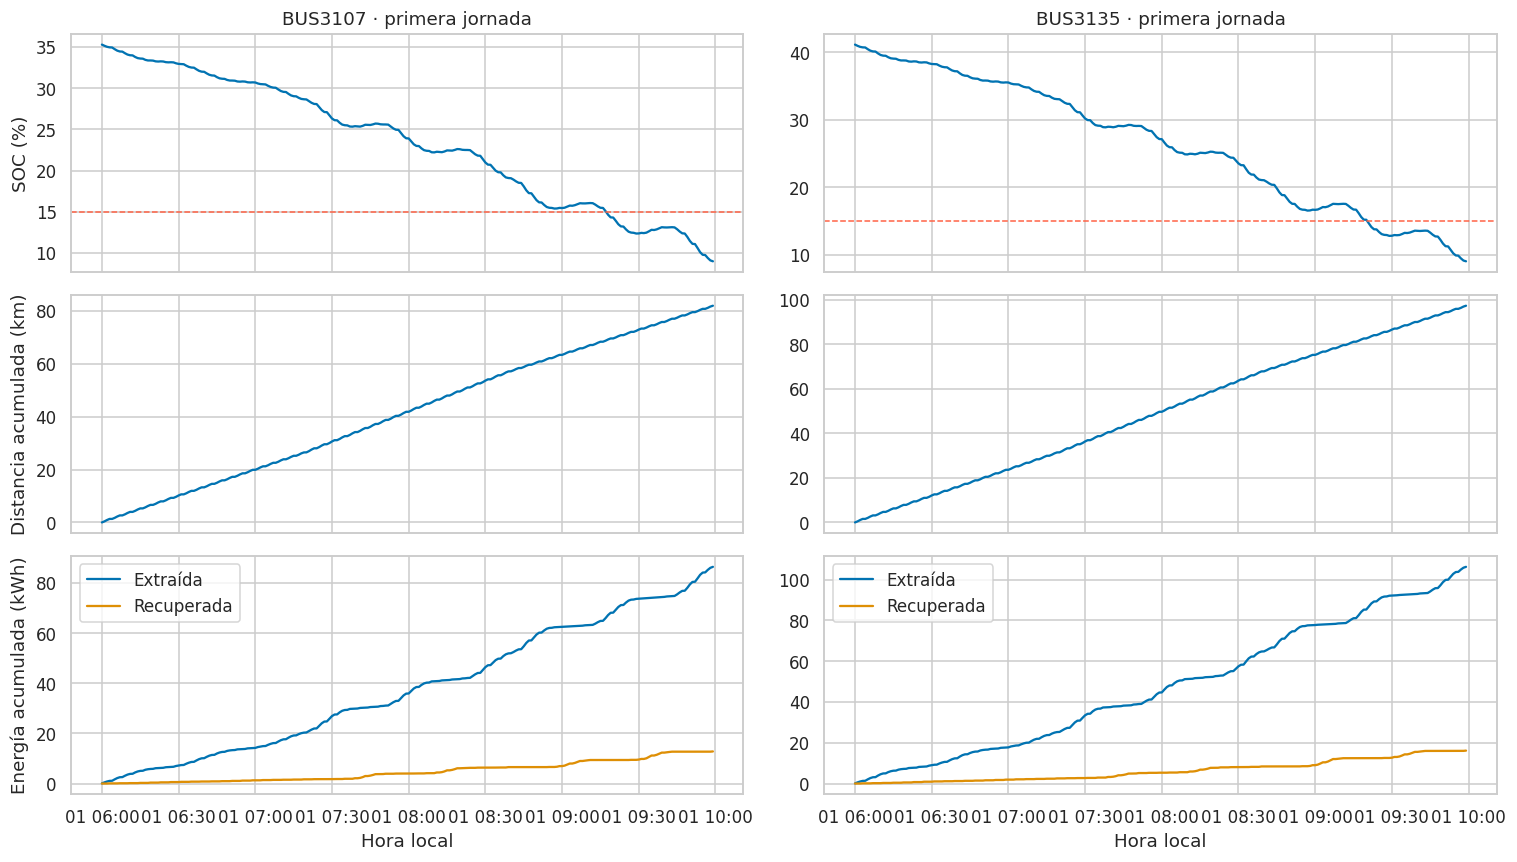

,peso_actual_kg,soc_inicio_pct,temperatura_ambiente_c,velocidad_media_kmh,pendiente_pct,energia_neta_kwh,distancia_km
medias por autobús (BUS3125 = test),,,,,,,
BUS3107,15660.333,29.616,20.408,21.130,0.351,0.314,0.352
BUS3125,15676.542,30.075,21.410,21.552,0.351,0.324,0.359
BUS3135,15590.833,29.795,20.909,21.294,0.351,0.317,0.355


In [ ]:
NUMERICAS = COLUMNAS_NUMERICAS

display(datos[NUMERICAS].describe(percentiles=[.01, .25, .50, .75, .99]).T)

resumen_ruta = datos.groupby(['id_vehiculo', 'id_ruta']).agg(
    registros=('id_ruta', 'size'),
    km=('distancia_km', 'sum'),
    kwh_brutos=('energia_consumida_kwh', 'sum'),
    kwh_regenerados=('energia_regenerada_kwh', 'sum'),
    kwh_netos=('energia_neta_kwh', 'sum'),
    peso_medio_kg=('peso_actual_kg', 'mean'),
)
resumen_ruta['consumo_neto_kwh_km'] = resumen_ruta['kwh_netos'] / resumen_ruta['km']
display(resumen_ruta)

# Primera jornada de cada autobús de entrenamiento.
fig, axes = plt.subplots(3, 2, figsize=(14, 8), sharex='col')
for col, bus in enumerate(BUSES_ENTRENAMIENTO):
    sub = datos[datos['id_vehiculo'] == bus]
    dia = sub[sub['fecha'] == sub['fecha'].iloc[0]]
    axes[0, col].plot(dia['fecha_hora'], dia['soc_pct'])
    axes[0, col].axhline(15, color='tomato', ls='--', lw=1)
    axes[0, col].set_title(f'{bus} · primera jornada')
    axes[1, col].plot(dia['fecha_hora'], dia['distancia_km'].cumsum())
    axes[2, col].plot(dia['fecha_hora'], dia['energia_consumida_kwh'].cumsum(), label='Extraída')
    axes[2, col].plot(dia['fecha_hora'], dia['energia_regenerada_kwh'].cumsum(), label='Recuperada')
    axes[2, col].legend()
    axes[2, col].set_xlabel('Hora local')
axes[0, 0].set_ylabel('SOC (%)')
axes[1, 0].set_ylabel('Distancia acumulada (km)')
axes[2, 0].set_ylabel('Energía acumulada (kWh)')
plt.tight_layout()
plt.show()

# Comparación descriptiva de los TRES autobuses (el test solo se describe, no se usa para decidir).
variables_comparacion = ['peso_actual_kg', 'soc_inicio_pct', 'temperatura_ambiente_c', 'velocidad_media_kmh',
                         'pendiente_pct', 'energia_neta_kwh', 'distancia_km']
display(df_todo.groupby('id_vehiculo')[variables_comparacion].mean().round(3)
        .rename_axis('medias por autobús (BUS3125 = test)'))

### 3.3 Decisión: ¿transformar, imputar o eliminar datos?

Se reemplazan los vacíos con el último dato registrado (*forward fill*) ya que al ser telemetria de minuto a minuto el dato se puede asemejar.

Se cuantifica los vacíos, comprueba dónde ocurren y simula qué pasaría al aplicar *forward fill* sobre `consumo_kwh_km`.

**Conclusión del análisis:**
* Los únicos vacíos están en `consumo_kwh_km` y ocurren exactamente en los minutos con distancia cero: el cociente kWh/km es una *indefinición matemática*, no un dato perdido.
* Las detenciones son paradas aisladas (el bloque muestra que duran 1 minuto), de modo que el *forward fill* copiaría el consumo del minuto en marcha anterior. Rellenar con el valor anterior asignaría a un autobús **detenido** el consumo del último minuto en marcha. Además, ese valor multiplicado por la distancia (0 km) daría 0 kWh, mientras que la energía real del minuto detenido (auxiliares) es positiva: la imputación crearía una contradicción física.
* Por eso **no se imputa ni se elimina ninguna fila**. Los modelos de la Fase 2 no usan `consumo_kwh_km`: aprenden con las magnitudes integradas (energía y distancia), que sí están completas, y el rendimiento se obtiene después como cociente.
* El *forward fill* sí es razonable para señales continuas (por ejemplo, temperaturas) con huecos de **un minuto** dentro de un mismo segmento. Se deja implementado y **desactivado** (`APLICAR_FFILL_TEMPERATURAS = False`) porque no hay temperaturas faltantes en estos datos.

In [ ]:
vacios = datos['consumo_kwh_km'].isna()
detenido = datos['distancia_km'] <= 1e-8
print('Vacíos en consumo_kwh_km:', int(vacios.sum()), f'({100 * vacios.mean():.1f} % de las filas)')
print('¿Coinciden exactamente con los minutos detenidos?:', bool((vacios == detenido).all()))
print('Vacíos en cualquier otra columna:', int(datos.drop(columns='consumo_kwh_km').isna().sum().sum()))

# Longitud de las rachas de detención consecutiva: cuánto tiempo arrastraría un forward fill un valor viejo.
racha_id = (vacios != vacios.shift()) | (datos['segmento'] != datos['segmento'].shift())
rachas = vacios.groupby(racha_id.cumsum()).sum()
rachas = rachas[rachas > 0]
print(f'Rachas de detención: {len(rachas)} | mediana {rachas.median():.0f} min | máxima {rachas.max():.0f} min')

# Simulación: forward fill dentro de cada segmento.
consumo_ffill = datos.groupby('segmento')['consumo_kwh_km'].ffill()
energia_implicita = (consumo_ffill * datos['distancia_km'])[vacios].sum()
energia_real = datos.loc[vacios, 'energia_neta_kwh'].sum()
print(f'Energía neta REAL en minutos detenidos : {energia_real:8.2f} kWh')
print(f'Energía implícita con forward fill     : {energia_implicita:8.2f} kWh  (consumo imputado × 0 km)')

# Imputación opcional y acotada para temperaturas (desactivada: no hay faltantes).
APLICAR_FFILL_TEMPERATURAS = False
COLUMNAS_TEMPERATURA = ['temperatura_electromotor_c', 'temperatura_bateria_c', 'temperatura_ambiente_c']
if APLICAR_FFILL_TEMPERATURAS:
    datos[COLUMNAS_TEMPERATURA] = datos.groupby('segmento')[COLUMNAS_TEMPERATURA].ffill(limit=1)

constantes = [c for c in NUMERICAS if datos[c].nunique(dropna=True) <= 1]
print('\nVariables constantes (se conservan en la tabla, se excluyen de PCA/distancias):', constantes)
print('Filas conservadas:', len(datos))

Vacíos en consumo_kwh_km: 3420 (23.8 % de las filas)
¿Coinciden exactamente con los minutos detenidos?: True
Vacíos en cualquier otra columna: 0
Rachas de detención: 3420 | mediana 1 min | máxima 1 min
Energía neta REAL en minutos detenidos :   184.95 kWh
Energía implícita con forward fill     :     0.00 kWh  (consumo imputado × 0 km)

Variables constantes (se conservan en la tabla, se excluyen de PCA/distancias): ['capacidad_util_bateria_kwh']
Filas conservadas: 14400


### 3.4 Variable categórica: ruta (one-hot encoding)

**Qué hace:** convierte `id_ruta` (R01, R02, R03) en tres columnas binarias.

One Hot para tratar la ruta como categoria independiente

En la exploración (clustering/PCA) las rutas no entran a la matriz base: se usan después para *interpretar* los grupos. Si entraran, las etiquetas tenderían a reproducir la ruta y no los regímenes de conducción. En la Fase 2 la ruta sí es una entrada del modelo, porque se conoce al emitir la predicción.

In [ ]:
try:
    codificador_ruta = OneHotEncoder(handle_unknown='ignore', sparse_output=False, dtype=np.float64)
except TypeError:  # versiones antiguas de scikit-learn
    codificador_ruta = OneHotEncoder(handle_unknown='ignore', sparse=False, dtype=np.float64)

rutas_ohe = pd.DataFrame(
    codificador_ruta.fit_transform(datos[['id_ruta']]),
    columns=codificador_ruta.get_feature_names_out(['id_ruta']),
    index=datos.index,
)
assert rutas_ohe.sum(axis=1).eq(1).all()
display(pd.concat([datos[['id_ruta']], rutas_ohe], axis=1).drop_duplicates().reset_index(drop=True))

,id_ruta,id_ruta_R01,id_ruta_R02,id_ruta_R03
0,R01,1.0,0.0,0.0
1,R02,0.0,1.0,0.0
2,R03,0.0,0.0,1.0


### 3.5 Matrices de correlación

Se calcularon las correlaciones de **Pearson** (relación lineal) y **Spearman** (relación monótona basada en rangos) entre variables físicas y energéticas, y lista los pares más correlacionados.

**Por qué las dos:** Pearson es sensible a valores extremos y solo mide linealidad; Spearman es más robusto con distribuciones asimétricas como las de este dataset (muchos minutos detenidos). Si difieren mucho, hay relaciones no lineales o dominadas por extremos.


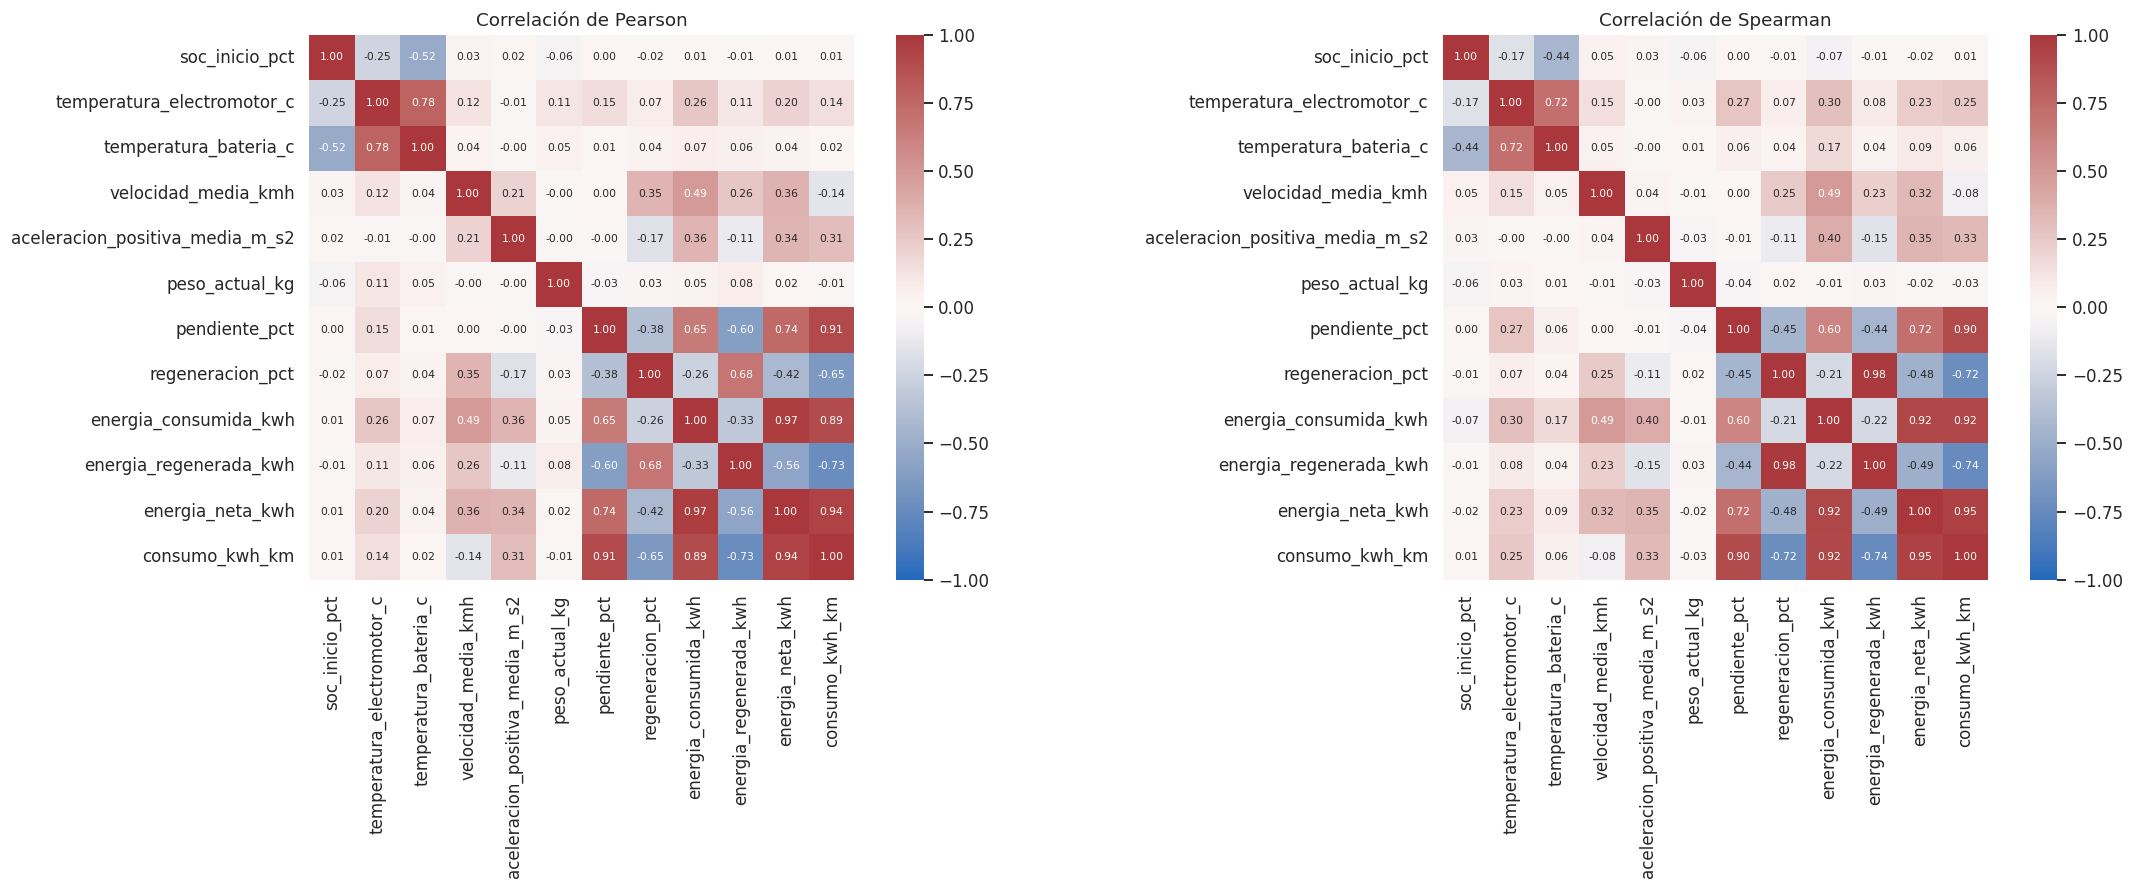

,,r de Pearson
energia_consumida_kwh,energia_neta_kwh,0.9666
energia_neta_kwh,consumo_kwh_km,0.9395
pendiente_pct,consumo_kwh_km,0.9051
energia_consumida_kwh,consumo_kwh_km,0.8948
temperatura_electromotor_c,temperatura_bateria_c,0.7810
pendiente_pct,energia_neta_kwh,0.7366
energia_regenerada_kwh,consumo_kwh_km,-0.7308
regeneracion_pct,energia_regenerada_kwh,0.6789
pendiente_pct,energia_consumida_kwh,0.6521
regeneracion_pct,consumo_kwh_km,-0.6458


In [ ]:
columnas_correlacion = [
    'soc_inicio_pct', 'temperatura_electromotor_c', 'temperatura_bateria_c', 'velocidad_media_kmh',
    'aceleracion_positiva_media_m_s2', 'peso_actual_kg', 'pendiente_pct', 'regeneracion_pct',
    'energia_consumida_kwh', 'energia_regenerada_kwh', 'energia_neta_kwh', 'consumo_kwh_km',
]
corr_pearson = datos[columnas_correlacion].corr(method='pearson')
corr_spearman = datos[columnas_correlacion].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(21, 8))
for ax, matriz, nombre in zip(axes, [corr_pearson, corr_spearman], ['Pearson', 'Spearman']):
    sns.heatmap(matriz, ax=ax, cmap='vlag', vmin=-1, vmax=1, center=0, annot=True, fmt='.2f',
                annot_kws={'size': 7}, square=True)
    ax.set_title(f'Correlación de {nombre}')
plt.tight_layout()
plt.show()

triangulo = corr_pearson.where(np.triu(np.ones(corr_pearson.shape), k=1).astype(bool)).stack()
orden = triangulo.abs().sort_values(ascending=False).index
display(triangulo.reindex(orden).head(12).rename('r de Pearson'))

### 3.6 Histogramas, boxplots y observaciones extremas

Boxplots por ruta y una tabla con el porcentaje de observaciones.

Los histogramas muestran asimetrías y acumulaciones en cero (detenciones); los boxplots por ruta revelan si la ruta condiciona la variable. La regla 1,5 × IQR es una señal exploratoria, no un criterio de eliminación: en telemetría, un "extremo" suele ser un tramo real (una cuesta, un minuto de alta aceleración) que el modelo debe aprender. Si el IQR es cero la regla no tiene sentido y se informa como `NaN`.

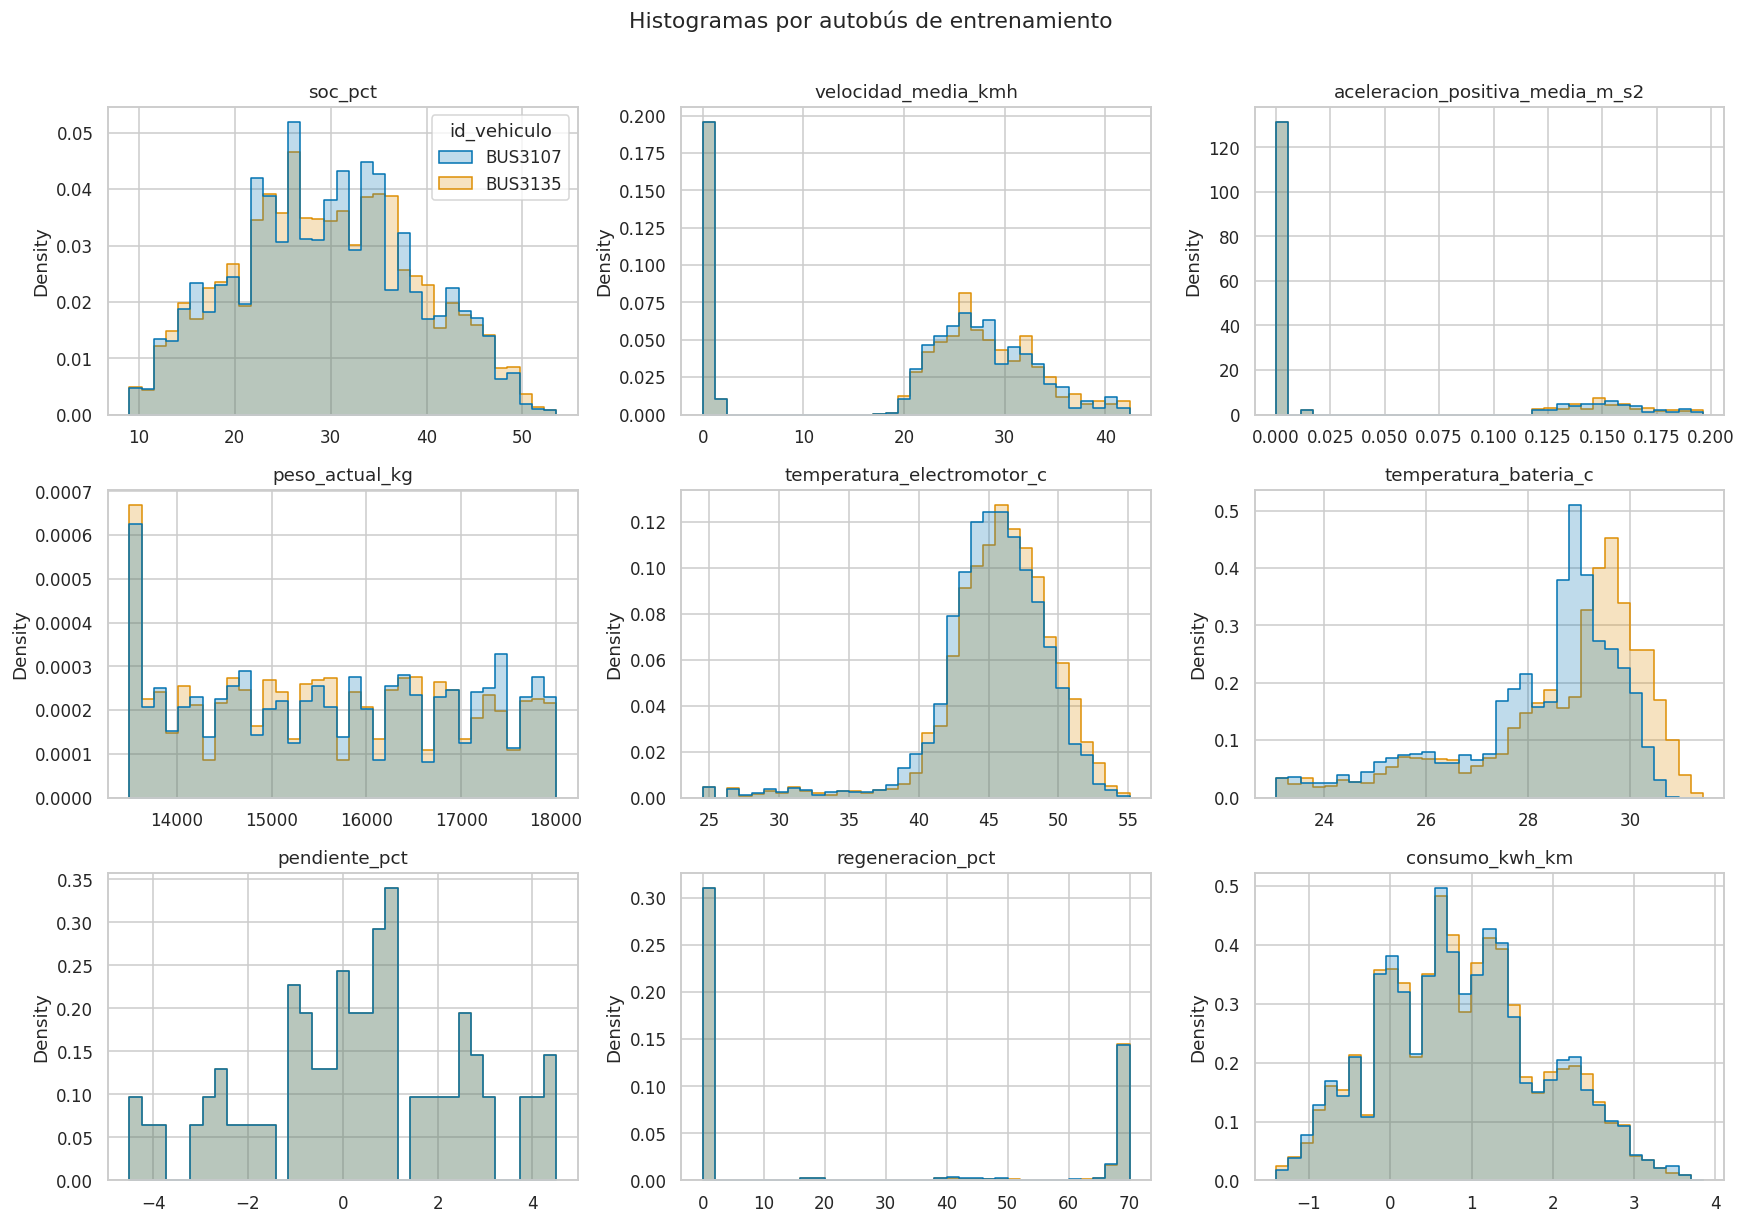

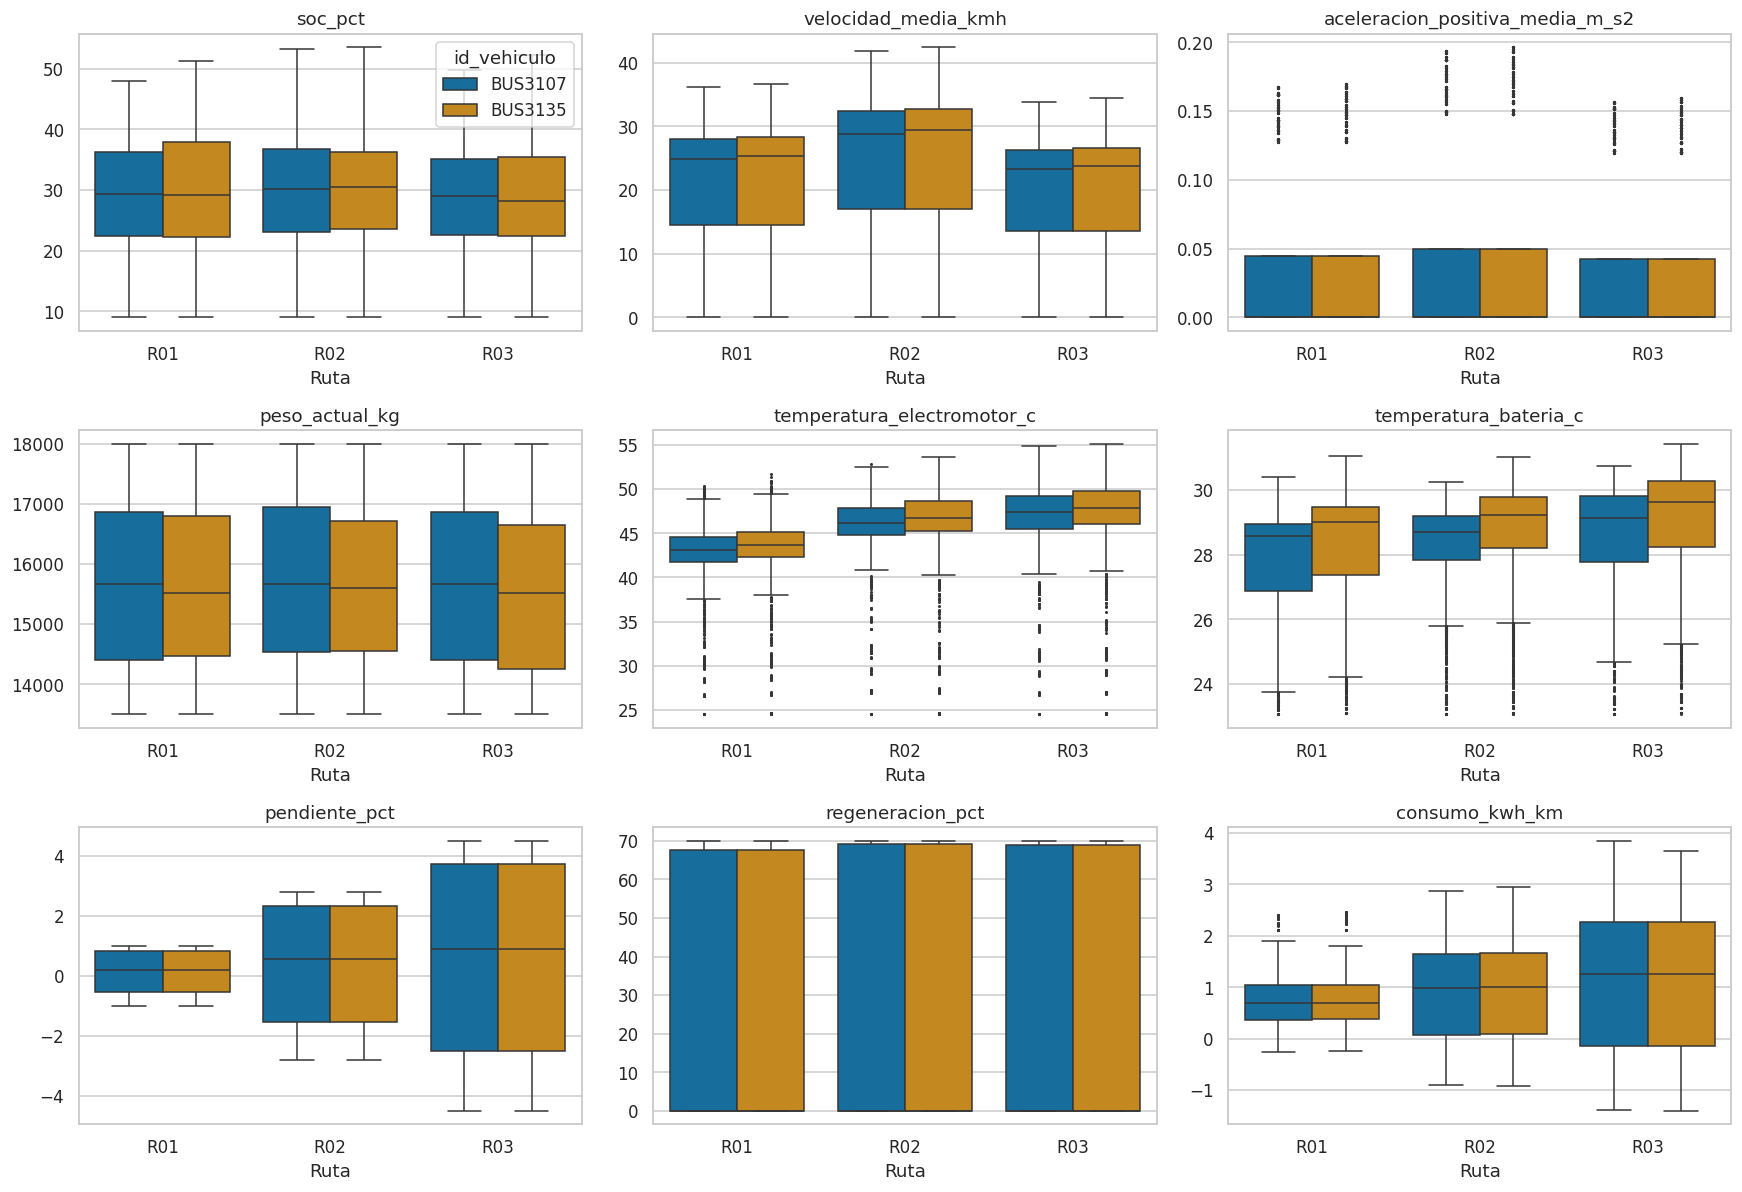

,variable,IQR,fuera_de_bigotes_pct
0,soc_pct,13.4518,0.0000
1,velocidad_media_kmh,16.5390,0.0000
2,aceleracion_positiva_media_m_s2,0.0424,25.0000
3,peso_actual_kg,2325.0000,0.0000
4,temperatura_electromotor_c,4.3785,3.1875
5,temperatura_bateria_c,1.9548,4.7917
6,pendiente_pct,2.7104,0.0000
7,regeneracion_pct,68.4224,0.0000
8,consumo_kwh_km,1.3895,0.0364


In [ ]:
columnas_grafico = [
    'soc_pct', 'velocidad_media_kmh', 'aceleracion_positiva_media_m_s2', 'peso_actual_kg',
    'temperatura_electromotor_c', 'temperatura_bateria_c', 'pendiente_pct', 'regeneracion_pct', 'consumo_kwh_km',
]

fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, col in zip(axes.flat, columnas_grafico):
    sns.histplot(data=datos, x=col, hue='id_vehiculo', bins=35, element='step', stat='density',
                 common_norm=False, ax=ax, legend=(col == columnas_grafico[0]))
    ax.set_title(col)
    ax.set_xlabel('')
plt.suptitle('Histogramas por autobús de entrenamiento', y=1.01)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 3, figsize=(16, 11))
for ax, col in zip(axes.flat, columnas_grafico):
    sns.boxplot(data=datos, x='id_ruta', y=col, hue='id_vehiculo', ax=ax, fliersize=1,
                legend=(col == columnas_grafico[0]))
    ax.set_title(col)
    ax.set_xlabel('Ruta')
    ax.set_ylabel('')
plt.tight_layout()
plt.show()

filas_iqr = []
for col in columnas_grafico:
    serie = datos[col].dropna()
    q1, q3 = serie.quantile([.25, .75])
    iqr = q3 - q1
    fuera = ((serie < q1 - 1.5 * iqr) | (serie > q3 + 1.5 * iqr)).mean() * 100 if iqr > 0 else np.nan
    filas_iqr.append({'variable': col, 'IQR': iqr, 'fuera_de_bigotes_pct': fuera})
display(pd.DataFrame(filas_iqr))

## 4. Preparación de la matriz analítica, normalización y PCA

### 4.0 Matriz analítica `X`

**Qué hace:** selecciona las variables continuas de operación, carga y entorno que describen el *régimen de conducción*.

**Qué se excluye y por qué:**
* **Identificadores y acumulativos** (`odometro_km`, `desgaste_frenos_pct`): crecen con el tiempo y solo reflejan la fecha.
* **Constantes** (capacidad útil, factor de SOC bajo): no aportan variación.
* **Redundantes** (`rpm_motor` es función de la velocidad; `asistente_escalada` deriva de la pendiente).
* **Variables de energía y sus cocientes** (`energia_*`, `consumo_kwh_km`, `potencia_neta_media_kw`): son la *respuesta* que se quiere explicar; ponerlas aquí contaminaría la exploración.

`X` describe regímenes simultáneos; **no** es la selección final de predictores (en la Fase 2 solo se usa información disponible *antes* del instante de predicción).

In [ ]:
VARIABLES_BASE = [
    'soc_inicio_pct', 'velocidad_media_kmh', 'aceleracion_m_s2', 'aceleracion_positiva_media_m_s2',
    'peso_actual_kg', 'temperatura_electromotor_c', 'temperatura_bateria_c', 'temperatura_ambiente_c',
    'pendiente_pct',
]
X = datos[VARIABLES_BASE].copy()
X = X.drop(columns=X.columns[X.nunique(dropna=True) <= 1].tolist())

mascara_completa = X.notna().all(axis=1) & np.isfinite(X).all(axis=1)
print('Filas no aptas para PCA/clustering (se mantienen en `datos`):', int((~mascara_completa).sum()))
X = X.loc[mascara_completa].copy()
meta = datos.loc[X.index].copy()
print('Matriz base:', X.shape, '| Variables:', list(X.columns))

Filas no aptas para PCA/clustering (se mantienen en `datos`): 0
Matriz base: (14400, 9) | Variables: ['soc_inicio_pct', 'velocidad_media_kmh', 'aceleracion_m_s2', 'aceleracion_positiva_media_m_s2', 'peso_actual_kg', 'temperatura_electromotor_c', 'temperatura_bateria_c', 'temperatura_ambiente_c', 'pendiente_pct']


### 4.1–4.2 Normalización (StandardScaler vs. RobustScaler) y varianza

**Qué hace:** escala `X` de dos formas y compara varianzas, IQR y boxplots.

* **StandardScaler:** resta la media y divide por la desviación estándar (media 0, varianza 1).
* **RobustScaler:** resta la mediana y divide por el rango intercuartílico, por lo que los extremos influyen menos en la escala.

**Por qué escalar:** PCA, KMeans, DBSCAN, SVR y las redes neuronales dependen de **distancias o gradientes** y una variable en kg (≈10⁴) dominaría a una en °C (≈10¹). Los árboles (RF, GBDT, XGBoost) **no** lo necesitan, porque solo comparan umbrales.

**Advertencias:** ningún escalador elimina outliers ni vuelve "normales" los datos, y una variable con varianza 1 no es por eso informativa. Se usa StandardScaler como referencia y RobustScaler como análisis de sensibilidad (no se encadenan).

,varianza_original,IQR_original,varianza_standard,varianza_robust
soc_inicio_pct,8.7457e+01,13.4899,1.0,0.4806
velocidad_media_kmh,1.6668e+02,16.5390,1.0,0.6093
aceleracion_m_s2,1.1833e-02,0.0598,1.0,3.3074
aceleracion_positiva_media_m_s2,4.4471e-03,0.0424,1.0,2.4729
peso_actual_kg,1.8767e+06,2325.0000,1.0,0.3472
temperatura_electromotor_c,1.6374e+01,4.3785,1.0,0.8541
temperatura_bateria_c,2.9488e+00,1.9548,1.0,0.7717
temperatura_ambiente_c,9.2454e-01,1.5644,1.0,0.3778
pendiente_pct,4.7250e+00,2.7104,1.0,0.6432


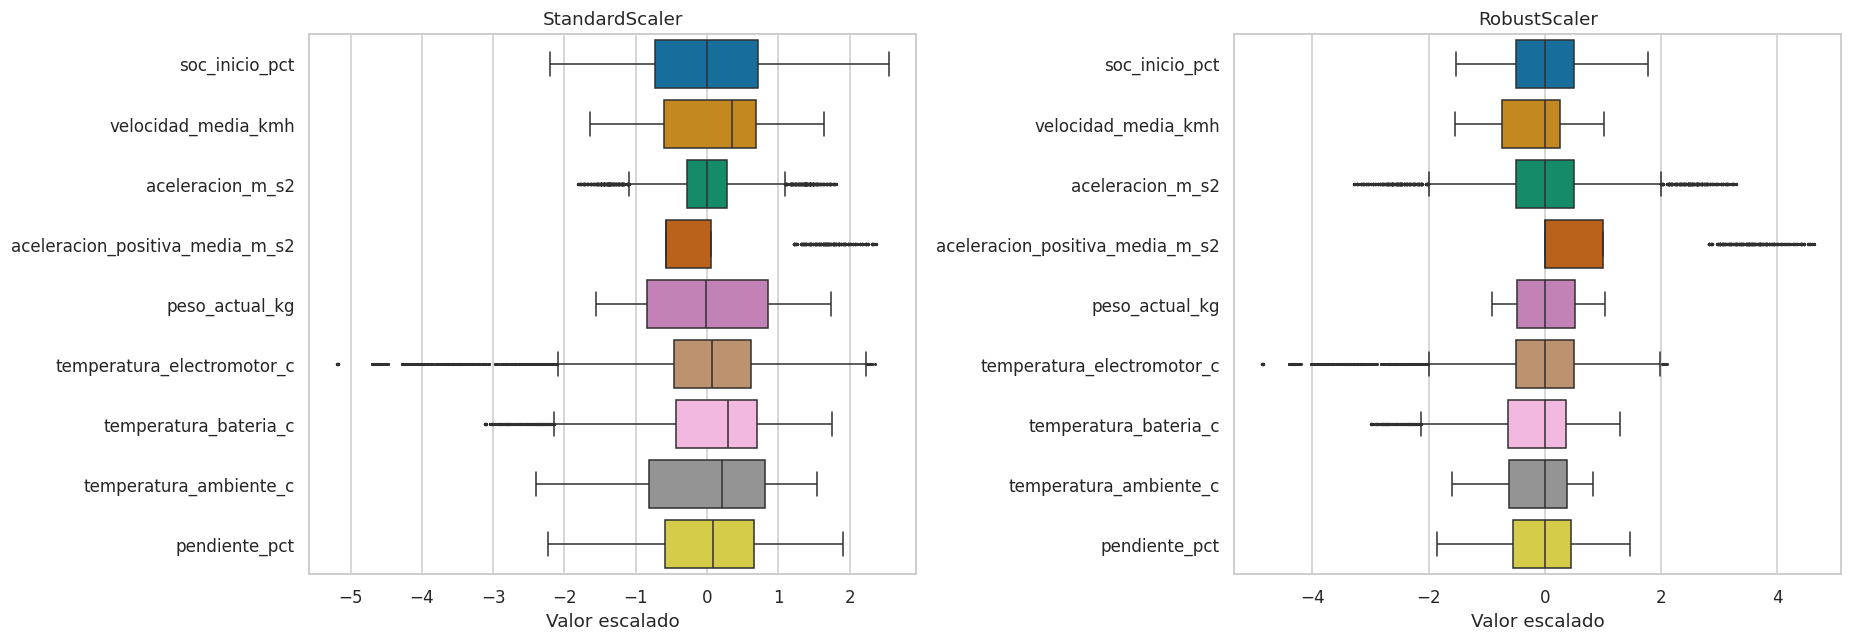

In [ ]:
escaladores = {'StandardScaler': StandardScaler(), 'RobustScaler': RobustScaler()}
matrices = {
    nombre: pd.DataFrame(esc.fit_transform(X), index=X.index, columns=X.columns)
    for nombre, esc in escaladores.items()
}
tabla_varianza = pd.DataFrame({
    'varianza_original': X.var(ddof=0),
    'IQR_original': X.quantile(.75) - X.quantile(.25),
    'varianza_standard': matrices['StandardScaler'].var(ddof=0),
    'varianza_robust': matrices['RobustScaler'].var(ddof=0),
})
display(tabla_varianza)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
for ax, (nombre, Zi) in zip(axes, matrices.items()):
    sns.boxplot(data=Zi, orient='h', ax=ax, fliersize=1)
    ax.set_title(nombre)
    ax.set_xlabel('Valor escalado')
plt.tight_layout()
plt.show()

ESCALADOR_ELEGIDO = 'StandardScaler'  # Cambiar y ejecutar desde aquí para un análisis de sensibilidad.
Z = matrices[ESCALADOR_ELEGIDO]

### 4.3 Análisis de componentes principales (PCA)

**Qué hace:** extrae los ejes de máxima varianza de `Z`, grafica la varianza explicada (individual y acumulada) y muestra los coeficientes de cada variable en los primeros ejes.

**Por qué:** PCA indica **cuántas dimensiones independientes** tiene realmente el problema y qué variables se mueven juntas. El umbral del 90 % de varianza acumulada es una referencia editable, no una obligación de reducir.

**Cómo leerlo:** PCA busca variación, no capacidad predictiva; un componente grande puede no servir para predecir consumo. El signo de un eje es arbitrario (puede invertirse sin cambiar el análisis). Los coeficientes (`components_`) dicen qué variables pesan en cada componente.

,componente,varianza,acumulada
0,PC1,0.2799,0.2799
1,PC2,0.2041,0.4839
2,PC3,0.1189,0.6028
3,PC4,0.1131,0.7159
4,PC5,0.1128,0.8287
5,PC6,0.1054,0.9341
6,PC7,0.0414,0.9755
7,PC8,0.0171,0.9926
8,PC9,0.0074,1.0000


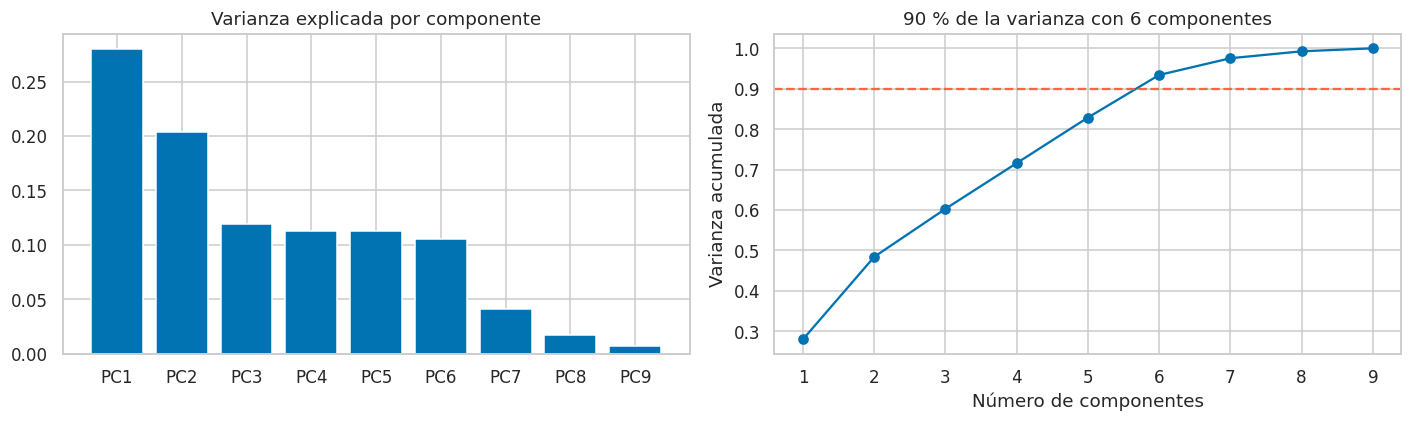

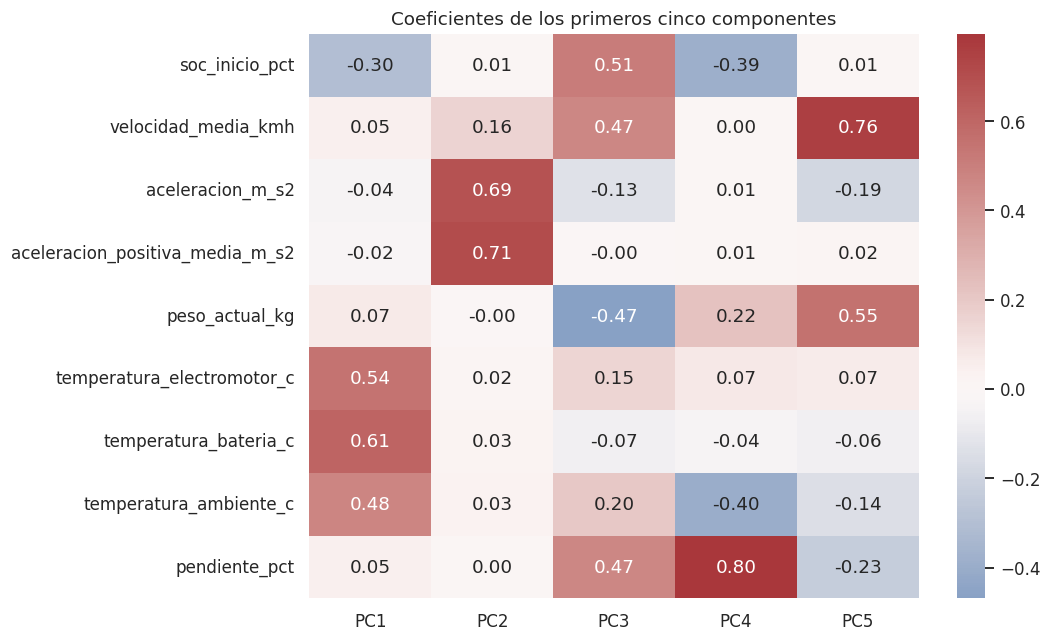

In [ ]:
pca = PCA(svd_solver='full')
puntajes = pca.fit_transform(Z)
nombres_pc = [f'PC{i + 1}' for i in range(puntajes.shape[1])]
puntajes_df = pd.DataFrame(puntajes, index=Z.index, columns=nombres_pc)

varianza_pca = pd.DataFrame({
    'componente': nombres_pc,
    'varianza': pca.explained_variance_ratio_,
    'acumulada': np.cumsum(pca.explained_variance_ratio_),
})
n_componentes_90 = int(np.searchsorted(varianza_pca['acumulada'].to_numpy(), .90) + 1)
display(varianza_pca)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(nombres_pc, pca.explained_variance_ratio_)
axes[0].set_title('Varianza explicada por componente')
axes[1].plot(range(1, len(nombres_pc) + 1), varianza_pca['acumulada'], marker='o')
axes[1].axhline(.90, ls='--', color='tomato')
axes[1].set(xlabel='Número de componentes', ylabel='Varianza acumulada',
            title=f'90 % de la varianza con {n_componentes_90} componentes')
plt.tight_layout()
plt.show()

coeficientes_pca = pd.DataFrame(pca.components_.T, index=Z.columns, columns=nombres_pc)
plt.figure(figsize=(10, 6))
sns.heatmap(coeficientes_pca.iloc[:, :5], cmap='vlag', center=0, annot=True, fmt='.2f')
plt.title('Coeficientes de los primeros cinco componentes')
plt.tight_layout()
plt.show()

### 4.4 Comparación de componentes PCA entre grupos

**Qué hace:** proyecta todas las observaciones sobre el **mismo PCA** y colorea PC1–PC2 por ruta, por autobús y por nivel de SOC inicial (<15 %, 15–30 %, ≥30 %); además resume media y desviación de cada grupo.

**Por qué un único PCA:** si se ajustara un PCA por grupo, cada uno tendría ejes distintos y sus coordenadas no serían comparables. Con un PCA común, si dos grupos ocupan zonas distintas del plano es porque sus condiciones operativas realmente difieren.

**Cómo leerlo:** la superposición no prueba que dos grupos sean idénticos (PC1–PC2 retienen solo parte de la variación). Con la comparación **por autobús** se evalúa si los dos vehículos de entrenamiento tienen comportamientos intercambiables, requisito para tratarlos como un único conjunto de entrenamiento.

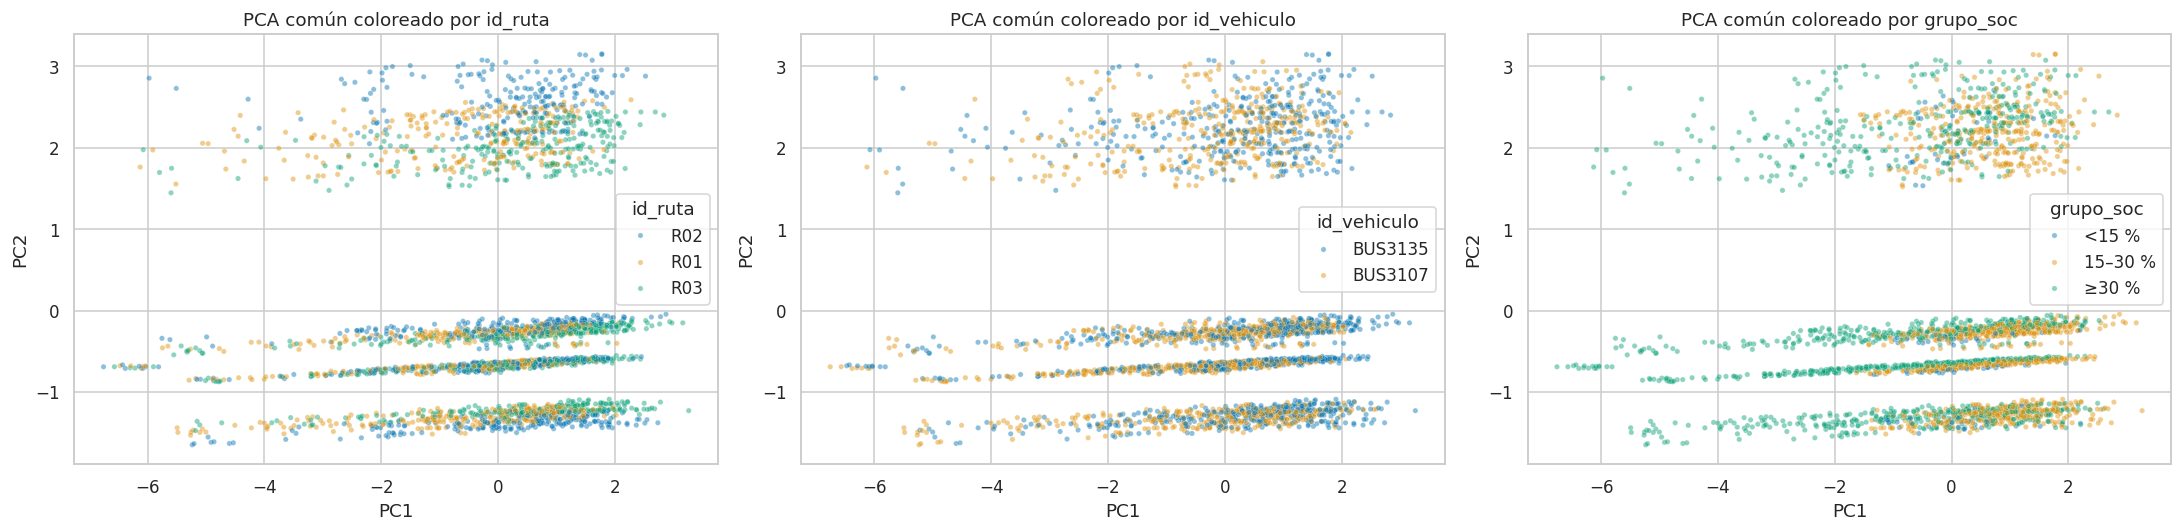

PC1                   PC2              
           mean     std count    mean     std count
id_ruta                                            
R01     -0.4649  1.5406  4800 -0.0366  1.3082  4800
R02      0.1011  1.4812  4800  0.0858  1.5114  4800
R03      0.3638  1.6222  4800 -0.0492  1.2265  4800

PC1                   PC2              
               mean     std count    mean     std count
id_vehiculo                                            
BUS3107     -0.2376  1.5456  7200 -0.0165  1.3493  7200
BUS3135      0.2376  1.5926  7200  0.0165  1.3610  7200

PC1                   PC2              
             mean     std count    mean     std count
grupo_soc                                            
<15 %      0.0195  0.7114   856 -0.1069  1.3265   856
15–30 %    0.7346  0.8989  6534 -0.0007  1.3314  6534
≥30 %     -0.6871  1.8397  7010  0.0137  1.3802  7010

In [ ]:
vista_pca = puntajes_df.join(meta[['id_ruta', 'id_vehiculo', 'soc_inicio_pct']])
vista_pca['grupo_soc'] = pd.cut(vista_pca['soc_inicio_pct'], [-np.inf, 15, 30, np.inf],
                                labels=['<15 %', '15–30 %', '≥30 %'], right=False)
muestra_pca = vista_pca.sample(min(3000, len(vista_pca)), random_state=SEMILLA)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, grupo in zip(axes, ['id_ruta', 'id_vehiculo', 'grupo_soc']):
    sns.scatterplot(data=muestra_pca, x='PC1', y='PC2', hue=grupo, s=12, alpha=.45, ax=ax)
    ax.set_title(f'PCA común coloreado por {grupo}')
plt.tight_layout()
plt.show()

for grupo in ['id_ruta', 'id_vehiculo', 'grupo_soc']:
    display(vista_pca.groupby(grupo, observed=True)[['PC1', 'PC2']].agg(['mean', 'std', 'count']))

## 5. Propuesta de nuevas variables

### 5.1 Rendimiento total (km por kWh) por autobús, ruta y jornada

**Qué hace:** define el **rendimiento neto = distancia total / energía neta total** (km/kWh), junto con el rendimiento bruto (sin descontar regeneración) y el porcentaje de energía recuperada respecto a la extraída.

**Por qué esta definición:**
* Se calcula **sumando** distancias y energías y luego dividiendo (no promediando cocientes por minuto), para no sesgar con los minutos detenidos.
* La energía neta incluye los auxiliares consumidos durante las detenciones y descuenta la regeneración.
* Si la energía neta es cero o negativa, el rendimiento queda indefinido y se interpreta aparte.
* El rendimiento es un **resultado**, no una entrada: no debe usarse para predecirse a sí mismo.

Es la variable objetivo final del proyecto, y por eso conviene conocer su nivel y su variabilidad antes de modelarla.

,km,kwh_brutos,kwh_recuperados,kwh_netos,minutos,rendimiento_neto_km_kwh,rendimiento_bruto_km_kwh,recuperado_sobre_extraido_pct
id_vehiculo,,,,,,,,
BUS3107,2535.6053,2669.8935,409.7540,2260.1395,7200,1.1219,0.9497,15.3472
BUS3135,2555.2328,2695.1164,410.7318,2284.3846,7200,1.1186,0.9481,15.2399


km  kwh_brutos  kwh_recuperados  kwh_netos  \
id_vehiculo id_ruta                                                     
BUS3107     R01      819.5193    651.5649          55.5964   595.9684   
            R02      947.9053   1002.8148         153.8763   848.9385   
            R03      768.1807   1015.5139         200.2813   815.2326   
BUS3135     R01      825.8628    659.3955          56.4801   602.9153   
            R02      955.2437   1016.4841         153.4653   863.0187   
            R03      774.1264   1019.2369         200.7863   818.4506   

                     minutos  rendimiento_neto_km_kwh  \
id_vehiculo id_ruta                                     
BUS3107     R01         2400                   1.3751   
            R02         2400                   1.1166   
            R03         2400                   0.9423   
BUS3135     R01         2400                   1.3698   
            R02         2400                   1.1069   
            R03         2400                   0.9458   

                     rendimiento_bruto_km_kwh  recuperado_sobre_extraido_pct  
id_vehiculo id_ruta                                                           
BUS3107     R01                        1.2578                         8.5328  
            R02                        0.9452                        15.3444  
            R03                        0.7564                        19.7222  
BUS3135     R01                        1.2525                         8.5654  
            R02                        0.9398                        15.0977  
            R03                        0.7595                        19.6997

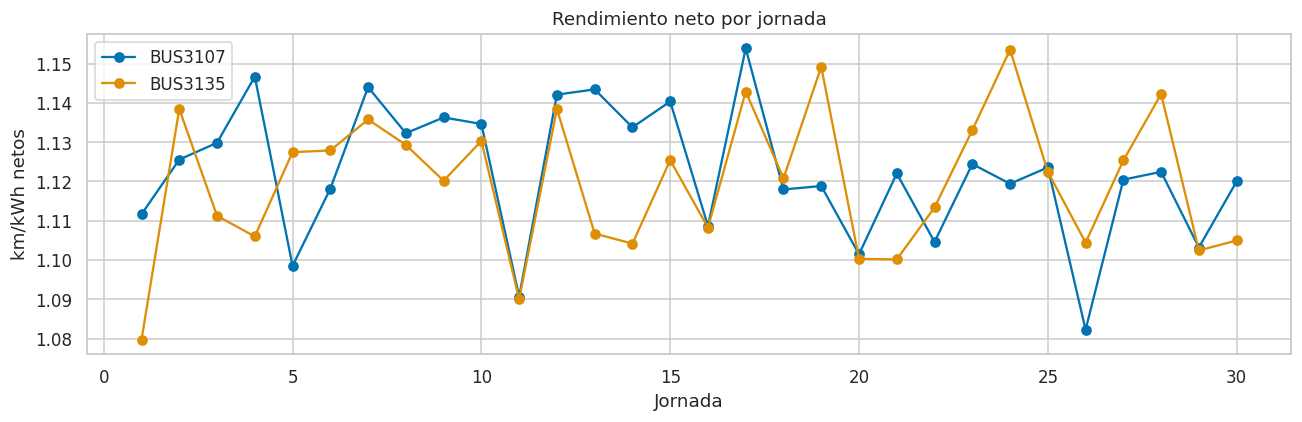

In [ ]:
EPS_ENERGIA = 1e-8


def agregar_rendimiento(tabla, agrupar_por):
    """Rendimiento = suma de km / suma de kWh netos (agregación correcta de cocientes)."""
    r = tabla.groupby(agrupar_por, observed=True).agg(
        km=('distancia_km', 'sum'),
        kwh_brutos=('energia_consumida_kwh', 'sum'),
        kwh_recuperados=('energia_regenerada_kwh', 'sum'),
        kwh_netos=('energia_neta_kwh', 'sum'),
        minutos=('fecha_hora', 'size'),
    )
    r['rendimiento_neto_km_kwh'] = r['km'] / r['kwh_netos'].where(r['kwh_netos'] > EPS_ENERGIA)
    r['rendimiento_bruto_km_kwh'] = r['km'] / r['kwh_brutos'].where(r['kwh_brutos'] > EPS_ENERGIA)
    r['recuperado_sobre_extraido_pct'] = 100 * r['kwh_recuperados'] / r['kwh_brutos'].where(r['kwh_brutos'] > EPS_ENERGIA)
    return r


datos['rendimiento_minuto_km_kwh'] = np.nan
valido = (datos['distancia_km'] > 1e-8) & (datos['energia_neta_kwh'] > EPS_ENERGIA)
datos.loc[valido, 'rendimiento_minuto_km_kwh'] = datos.loc[valido, 'distancia_km'] / datos.loc[valido, 'energia_neta_kwh']

rendimiento_bus = agregar_rendimiento(datos, ['id_vehiculo'])
rendimiento_ruta = agregar_rendimiento(datos, ['id_vehiculo', 'id_ruta'])
rendimiento_diario = agregar_rendimiento(datos, ['id_vehiculo', 'fecha'])
display(rendimiento_bus)
display(rendimiento_ruta)

fig, ax = plt.subplots(figsize=(12, 4))
for bus in BUSES_ENTRENAMIENTO:
    serie = rendimiento_diario.loc[bus, 'rendimiento_neto_km_kwh'].reset_index(drop=True)
    ax.plot(serie.index + 1, serie.values, marker='o', label=bus)
ax.set(xlabel='Jornada', ylabel='km/kWh netos', title='Rendimiento neto por jornada')
ax.legend()
plt.tight_layout()
plt.show()

### 5.2 Variables operativas adicionales y retardos seguros

Se creo ocupación estimada, indicador de detención, indicador de SOC bajo, minuto de la jornada y, como ejemplo, rezagos de un minuto y una media móvil de 5 minutos estrictamente anteriores.

ocupacion_estimada_pct: reescala el peso (13.500 kg vacío → 18.000 kg lleno) a una magnitud interpretable.

In [ ]:
datos['ocupacion_estimada_pct'] = 100 * (datos['peso_actual_kg'] - 13500) / (18000 - 13500)
datos['detenido'] = datos['distancia_km'].le(1e-8).astype(int)
datos['soc_bajo_inicio'] = datos['soc_inicio_pct'].lt(15).astype(int)
datos['minuto_jornada'] = datos.groupby(['id_vehiculo', 'fecha']).cumcount()

for col in ['velocidad_media_kmh', 'peso_actual_kg', 'soc_pct', 'energia_neta_kwh']:
    datos[f'{col}_lag1'] = datos.groupby('segmento')[col].shift(1)
datos['velocidad_media_previa_5min'] = datos.groupby('segmento')['velocidad_media_kmh'].transform(
    lambda s: s.shift(1).rolling(5, min_periods=5).mean())

display(datos[['fecha_hora', 'id_ruta', 'ocupacion_estimada_pct', 'detenido', 'soc_bajo_inicio',
               'energia_neta_kwh_lag1', 'velocidad_media_previa_5min']].head(8))

,fecha_hora,id_ruta,ocupacion_estimada_pct,detenido,soc_bajo_inicio,energia_neta_kwh_lag1,velocidad_media_previa_5min
0,2026-06-01 06:00:00-05:00,R01,0.0,0,0,NaN,NaN
1,2026-06-01 06:01:00-05:00,R01,0.0,0,0,0.0629,NaN
2,2026-06-01 06:02:00-05:00,R01,0.0,0,0,0.4046,NaN
3,2026-06-01 06:03:00-05:00,R01,0.0,0,0,0.3435,NaN
4,2026-06-01 06:04:00-05:00,R01,40.0,1,0,0.1874,NaN
5,2026-06-01 06:05:00-05:00,R01,40.0,0,0,0.0500,16.2526
6,2026-06-01 06:06:00-05:00,R01,40.0,0,0,0.5670,20.6784
7,2026-06-01 06:07:00-05:00,R01,40.0,0,0,0.5074,22.0669


## 6. Exploración de clusters

### 6.1 KMeans: método del codo y coeficiente de silueta

El clustering busca regímenes operativos. Sirve para entender el dataset.

,k,inercia,silueta,grupo_minimo
0,2,105494.7689,0.2164,3600
1,3,85756.6222,0.2428,2484
2,4,74418.6578,0.2382,2177
3,5,68881.5122,0.2191,1811
4,6,64202.0020,0.2163,704
5,7,60463.0889,0.1947,644
6,8,56847.4866,0.1911,506


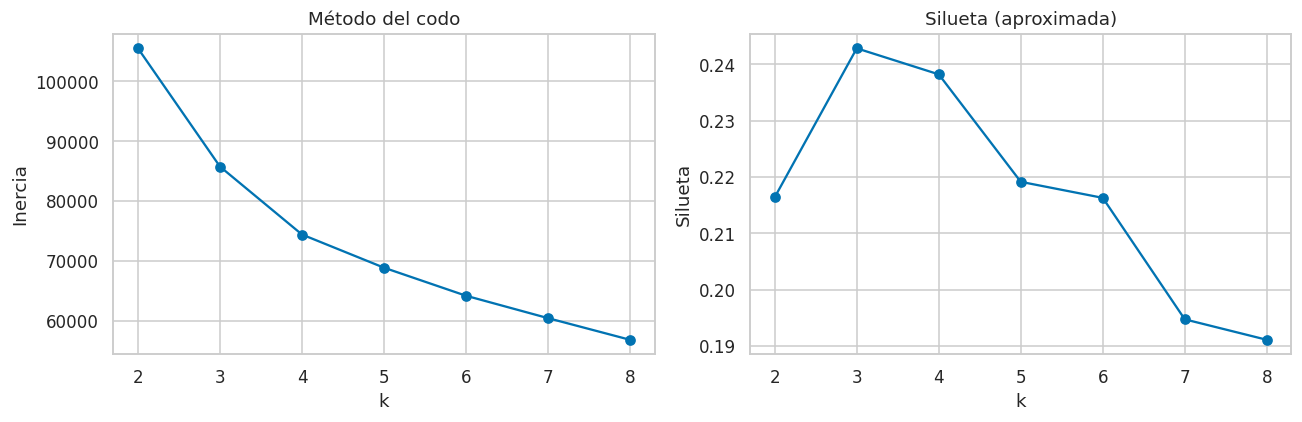

k propuesto por silueta: 3 | k usado: 3


In [ ]:
MAX_SILUETA = 1200


def silueta_segura(A, etiquetas, excluir_ruido=False):
    """Silueta con muestra reproducible; devuelve NaN si no hay al menos 2 grupos."""
    A = np.asarray(A)
    etiquetas = np.asarray(etiquetas)
    if excluir_ruido:
        conservar = etiquetas != -1
        A, etiquetas = A[conservar], etiquetas[conservar]
    if len(A) < 3 or not 2 <= len(np.unique(etiquetas)) < len(A):
        return np.nan
    try:
        return silhouette_score(A, etiquetas, sample_size=min(MAX_SILUETA, len(A)), random_state=SEMILLA)
    except ValueError:
        return np.nan


modelos_km = {}
filas_km = []
for k in range(2, 9):
    modelo = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA)
    etiquetas = modelo.fit_predict(Z)
    modelos_km[k] = modelo
    filas_km.append({'k': k, 'inercia': modelo.inertia_, 'silueta': silueta_segura(Z, etiquetas),
                     'grupo_minimo': int(np.bincount(etiquetas).min())})
evaluacion_km = pd.DataFrame(filas_km)
display(evaluacion_km)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(evaluacion_km['k'], evaluacion_km['inercia'], 'o-')
axes[0].set(title='Método del codo', xlabel='k', ylabel='Inercia')
axes[1].plot(evaluacion_km['k'], evaluacion_km['silueta'], 'o-')
axes[1].set(title='Silueta (aproximada)', xlabel='k', ylabel='Silueta')
plt.tight_layout()
plt.show()

K_PROPUESTO = int(evaluacion_km.loc[evaluacion_km['silueta'].idxmax(), 'k'])
K_ELEGIDO = K_PROPUESTO  # Editable tras revisar codo, perfiles y sentido operativo.
km = modelos_km[K_ELEGIDO]
etiquetas_km = km.labels_
print('k propuesto por silueta:', K_PROPUESTO, '| k usado:', K_ELEGIDO)

### 6.1.1 Interpretación de los clusters y comparación de sus componentes PCA

Se agregaron las etiquetas a una copia de la tabla y muestra (a) los centroides en unidades originales, (b) el tamaño de cada grupo, (c) su composición por ruta y por autobús, (d) el rendimiento agregado de cada grupo y (e) las medias de los componentes PCA por grupo.

,soc_inicio_pct,velocidad_media_kmh,aceleracion_m_s2,aceleracion_positiva_media_m_s2,peso_actual_kg,temperatura_electromotor_c,temperatura_bateria_c,temperatura_ambiente_c,pendiente_pct
cluster_kmeans,,,,,,,,,
0,40.2731,19.7622,-0.0181,0.0220,15459.7708,40.3172,25.3885,19.5673,0.2573
1,27.1165,19.9649,-0.0519,0.0002,15659.2656,46.7563,29.1212,20.9118,0.3887
2,28.5262,25.6748,0.1534,0.1534,15662.7049,46.3279,28.8240,20.8187,0.3224


,minutos
cluster_kmeans,
0,2484
1,8683
2,3233


id_ruta,R01,R02,R03
cluster_kmeans,,,
0,0.457,0.260,0.284
1,0.304,0.348,0.348
2,0.317,0.350,0.333


id_vehiculo,BUS3107,BUS3135
cluster_kmeans,,
0,0.553,0.447
1,0.487,0.513
2,0.494,0.506


,km,kwh_brutos,kwh_recuperados,kwh_netos,minutos,rendimiento_neto_km_kwh,rendimiento_bruto_km_kwh,recuperado_sobre_extraido_pct
cluster_kmeans,,,,,,,,
0,818.2270,745.6943,127.9853,617.7090,2484,1.3246,1.0973,17.1632
1,2889.1655,2683.4272,575.3306,2108.0966,8683,1.3705,1.0767,21.4401
2,1383.4457,1935.8884,117.1699,1818.7186,3233,0.7607,0.7146,6.0525


,PC1,PC2,PC3
cluster_kmeans,,,
0,-2.6662,-0.4011,0.2747
1,0.6564,-0.7259,-0.0554
2,0.2856,2.2577,-0.0623


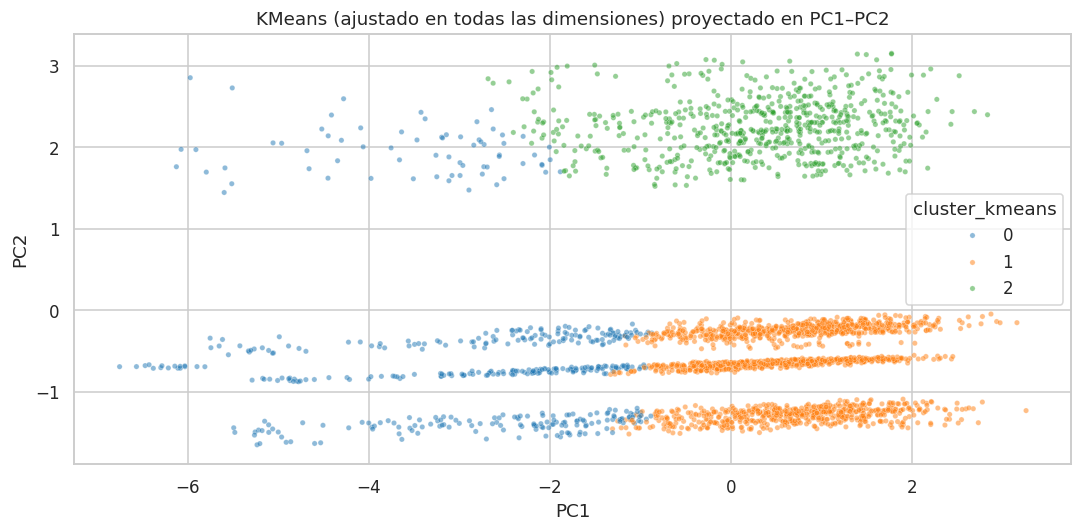

In [ ]:
resultado = datos.loc[Z.index].copy()
resultado['cluster_kmeans'] = etiquetas_km

centroides = pd.DataFrame(escaladores[ESCALADOR_ELEGIDO].inverse_transform(km.cluster_centers_), columns=Z.columns)
centroides.index.name = 'cluster_kmeans'
display(centroides)
display(resultado.groupby('cluster_kmeans').size().rename('minutos'))
display(pd.crosstab(resultado['cluster_kmeans'], resultado['id_ruta'], normalize='index').round(3))
display(pd.crosstab(resultado['cluster_kmeans'], resultado['id_vehiculo'], normalize='index').round(3))
display(agregar_rendimiento(resultado, ['cluster_kmeans']))

pc_clusters = puntajes_df.assign(cluster_kmeans=etiquetas_km)
display(pc_clusters.groupby('cluster_kmeans')[['PC1', 'PC2', 'PC3']].mean())

plt.figure(figsize=(10, 5))
sns.scatterplot(data=pc_clusters.sample(min(3000, len(pc_clusters)), random_state=SEMILLA),
                x='PC1', y='PC2', hue='cluster_kmeans', palette='tab10', s=12, alpha=.5)
plt.title('KMeans (ajustado en todas las dimensiones) proyectado en PC1–PC2')
plt.tight_layout()
plt.show()

### 6.1.2 Sensibilidad al escalado

Se repite KMeans con el mismo k usando StandardScaler y RobustScaler y compara las etiquetas con el **ARI** (Índice de Rand Ajustado: 1 = particiones idénticas, ~0 = coincidencia por azar), que no depende de qué número se asigne a cada grupo.

Si el resultado cambia mucho al cambiar de escalador, los grupos dependen de la representación y deben interpretarse con cautela. Las siluetas se calculan en espacios distintos y no bastan para elegir el escalador.

In [ ]:
filas_sensibilidad = []
etiquetas_por_escalador = {}
for nombre, Zi in matrices.items():
    modelo = KMeans(n_clusters=K_ELEGIDO, n_init=10, random_state=SEMILLA).fit(Zi)
    etiquetas_por_escalador[nombre] = modelo.labels_
    filas_sensibilidad.append({'escalador': nombre, 'k': K_ELEGIDO, 'silueta': silueta_segura(Zi, modelo.labels_)})
display(pd.DataFrame(filas_sensibilidad))
ARI_ESCALADORES = adjusted_rand_score(etiquetas_por_escalador['StandardScaler'], etiquetas_por_escalador['RobustScaler'])
print('ARI Standard vs Robust:', round(ARI_ESCALADORES, 4))

,escalador,k,silueta
0,StandardScaler,3,0.2428
1,RobustScaler,3,0.3424


ARI Standard vs Robust: 0.4015


### 6.2 DBSCAN: grupos por densidad y ruido

Se prueba DBSCAN con dos valores de `min_samples` (12 y 24) y tres radios `eps` tomados de cuantiles de la curva de distancias al k-ésimo vecino.

A diferencia de KMeans, DBSCAN no exige fijar k ni asume grupos esféricos, y marca como ruido (etiqueta −1) los puntos de baja densidad. Es útil para detectar regímenes poco frecuentes. Sus parámetros no son universales; por eso se evalúan candidatos con criterios explícitos.


,candidato,eps,min_samples,clusters,cobertura,ruido_pct,grupo_minimo,silueta_sin_ruido
0,0,0.9172,12,18,0.9041,9.5903,6,0.0303
1,1,1.0178,12,11,0.9726,2.7361,6,0.0996
2,2,1.1510,12,8,0.9960,0.3958,60,0.1769
3,3,1.0814,24,9,0.9342,6.5833,22,0.1643
4,4,1.2019,24,7,0.9834,1.6597,60,0.2137
5,5,1.3501,24,5,0.9972,0.2778,60,0.2141


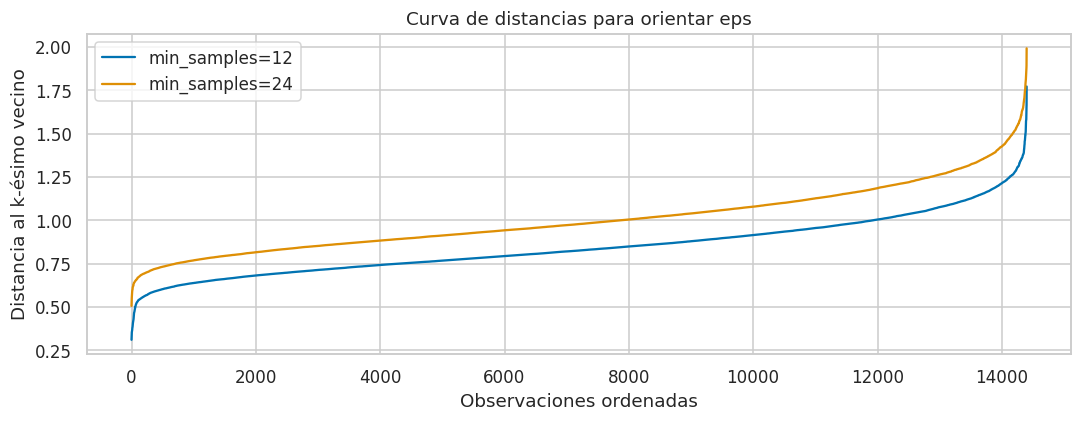

,candidato,eps,min_samples,clusters,cobertura,ruido_pct,grupo_minimo,silueta_sin_ruido
5,5,1.3501,24,5,0.9972,0.2778,60,0.2141


velocidad_media_kmh       peso_actual_kg       soc_inicio_pct  \
                              mean count           mean count           mean   
cluster_dbscan                                                                 
-1                         26.3109    40     16042.5000    40        45.5526   
 0                          1.7829    60     13500.0000    60        43.0501   
 1                         25.6042    60     13500.0000    60        43.0276   
 2                         29.6059  7180     15625.7068  7180        29.5141   
 3                          0.0604  3540     15661.6102  3540        29.6369   
 4                         25.5598  3520     15656.8253  3520        29.5292   

                     pendiente_pct        
               count          mean count  
cluster_dbscan                            
-1                40        3.8169    40  
 0                60        0.0000    60  
 1                60        0.5397    60  
 2              7180        0.3474  7180  
 3              3540        0.3396  3540  
 4              3520        0.3337  3520

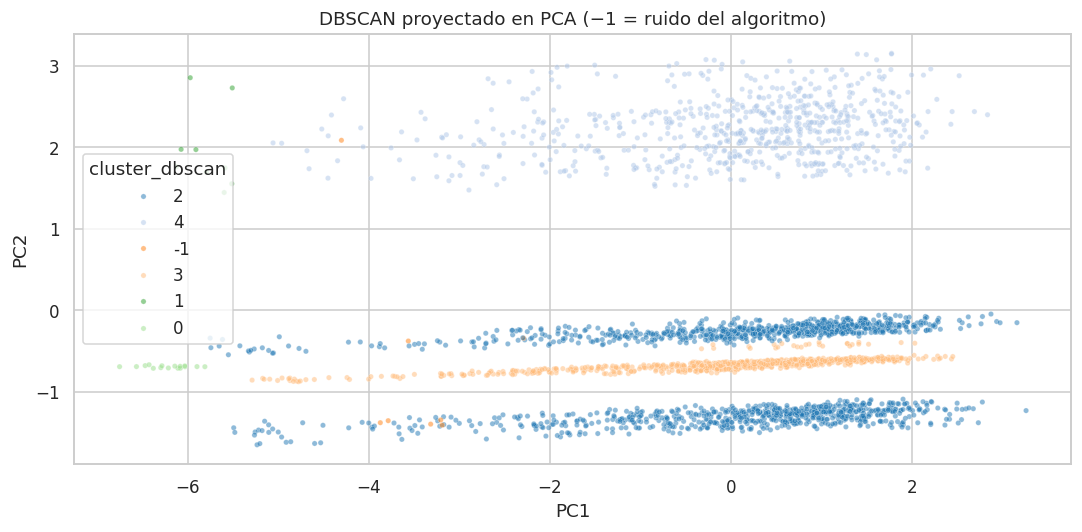

In [ ]:
filas_db = []
modelos_db = {}
curvas_distancia = {}
for min_muestras in [12, 24]:
    vecinos = NearestNeighbors(n_neighbors=min_muestras).fit(Z)
    distancias = vecinos.kneighbors(Z, return_distance=True)[0][:, -1]
    curvas_distancia[min_muestras] = np.sort(distancias)
    for eps in np.unique(np.maximum(np.quantile(distancias, [.70, .85, .95]), 1e-6)):
        modelo = DBSCAN(eps=float(eps), min_samples=min_muestras).fit(Z)
        etiquetas = modelo.labels_
        sin_ruido = etiquetas != -1
        conteo = pd.Series(etiquetas[sin_ruido]).value_counts()
        clave = len(filas_db)
        modelos_db[clave] = modelo
        filas_db.append({
            'candidato': clave, 'eps': eps, 'min_samples': min_muestras, 'clusters': len(conteo),
            'cobertura': sin_ruido.mean(), 'ruido_pct': 100 * (~sin_ruido).mean(),
            'grupo_minimo': int(conteo.min()) if len(conteo) else 0,
            'silueta_sin_ruido': silueta_segura(Z, etiquetas, excluir_ruido=True),
        })
evaluacion_db = pd.DataFrame(filas_db)
display(evaluacion_db)

fig, ax = plt.subplots(figsize=(10, 4))
for min_muestras, curva in curvas_distancia.items():
    ax.plot(curva, label=f'min_samples={min_muestras}')
ax.set(xlabel='Observaciones ordenadas', ylabel='Distancia al k-ésimo vecino', title='Curva de distancias para orientar eps')
ax.legend()
plt.tight_layout()
plt.show()

admisibles = evaluacion_db[
    evaluacion_db['clusters'].between(2, 15) & (evaluacion_db['cobertura'] >= .70)
    & (evaluacion_db['grupo_minimo'] >= 20) & evaluacion_db['silueta_sin_ruido'].notna()
]
DBSCAN_ADMISIBLE = not admisibles.empty
if DBSCAN_ADMISIBLE:
    id_db = int(admisibles.sort_values('silueta_sin_ruido', ascending=False).iloc[0]['candidato'])
else:
    id_db = int(evaluacion_db.sort_values('cobertura', ascending=False).iloc[0]['candidato'])
    print('Ningún candidato cumple los criterios; se muestra uno solo para diagnóstico.')

db = modelos_db[id_db]
resultado['cluster_dbscan'] = db.labels_
display(evaluacion_db[evaluacion_db['candidato'] == id_db])
display(resultado.groupby('cluster_dbscan')[['velocidad_media_kmh', 'peso_actual_kg', 'soc_inicio_pct', 'pendiente_pct']]
        .agg(['mean', 'count']))

plt.figure(figsize=(10, 5))
sns.scatterplot(data=puntajes_df.assign(cluster_dbscan=db.labels_.astype(str)).sample(min(3000, len(puntajes_df)), random_state=SEMILLA),
                x='PC1', y='PC2', hue='cluster_dbscan', s=12, alpha=.5, palette='tab20')
plt.title('DBSCAN proyectado en PCA (−1 = ruido del algoritmo)')
plt.tight_layout()
plt.show()

## 7. Análisis con la matriz transpuesta

### 7.1 ¿Cuándo tiene sentido transponer?
Se transpone las variables ya estandarizadas.

La tabla habitual agrupa *minutos* (estados del vehículo). La transpuesta permite preguntar otra cosa: **¿qué variables siguen perfiles temporales parecidos?** Sirve para detectar redundancia y orientar una eventual selección de variables. Se transponen solo las variables continuas con `StandardScaler` (para que kg y °C sean comparables), sin one-hot ni constantes. No se calcula nunca una correlación de minutos × minutos (14.400 × 14.400): el objeto de interés es la matriz pequeña variables × variables.

In [ ]:
T = matrices['StandardScaler'].T.copy()
T.columns = [f'minuto_{i}' for i in range(T.shape[1])]
print('Original (minutos, variables):', X.shape)
print('Transpuesta (variables, minutos):', T.shape)
display(T.iloc[:, :6])

Original (minutos, variables): (14400, 9)
Transpuesta (variables, minutos): (9, 14400)


,minuto_0,minuto_1,minuto_2,minuto_3,minuto_4,minuto_5
soc_inicio_pct,0.5983,0.5959,0.5804,0.5673,0.5601,0.5582
velocidad_media_kmh,-1.5049,0.2091,0.7469,0.2713,-1.6430,0.2091
aceleracion_m_s2,0.0000,1.3132,0.0000,-1.3132,0.0000,1.3132
aceleracion_positiva_media_m_s2,-0.3256,1.5665,-0.5755,-0.5755,-0.5755,1.5665
peso_actual_kg,-1.5516,-1.5516,-1.5516,-1.5516,-0.2377,-0.2377
temperatura_electromotor_c,-5.1916,-4.6751,-4.2438,-3.8556,-3.6644,-3.2247
temperatura_bateria_c,-3.1140,-3.0385,-2.9693,-2.9035,-2.8686,-2.7751
temperatura_ambiente_c,-2.3981,-2.3447,-2.1783,-2.0226,-1.9512,-1.9505
pendiente_pct,-0.1615,-0.0718,0.0145,0.0941,0.1638,0.2210


### 7.2 PCA de la tabla transpuesta

Se aplica PCA a los perfiles de las variables; cada punto del gráfico es ahora una variable.

Las variables cercanas en el plano tienen perfiles temporales similares. Este PCA responde otra pregunta que el de observaciones, por lo que su varianza explicada no es comparable. Con tan pocas variables (nueve) es una vista exploratoria sensible al conjunto elegido; no se descarta ninguna variable automáticamente por su posición.

,componente,varianza,acumulada
0,PCT1,0.3090,0.3090
1,PCT2,0.1962,0.5052
2,PCT3,0.1403,0.6455
3,PCT4,0.1370,0.7825
4,PCT5,0.1334,0.9159
5,PCT6,0.0503,0.9662
6,PCT7,0.0215,0.9877
7,PCT8,0.0123,1.0000


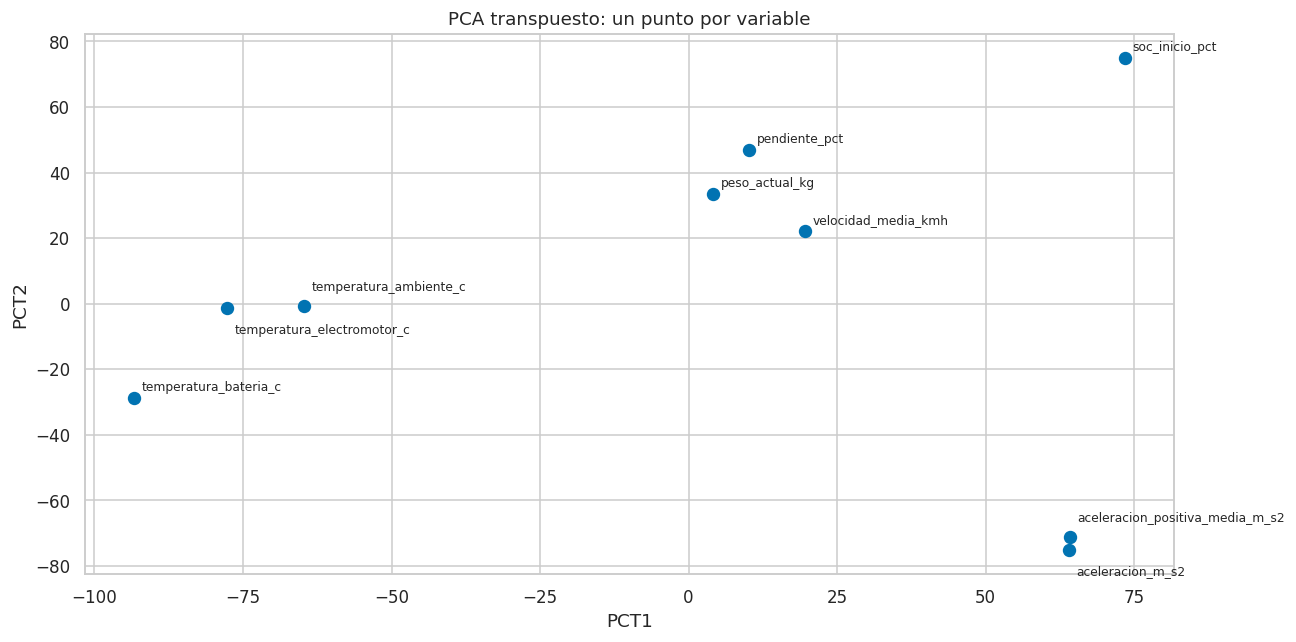

In [ ]:
pca_t = PCA(n_components=min(T.shape[0] - 1, T.shape[1]), svd_solver='full')
puntajes_t = pca_t.fit_transform(T)
tabla_t = pd.DataFrame(puntajes_t, index=T.index, columns=[f'PCT{i + 1}' for i in range(puntajes_t.shape[1])])
display(pd.DataFrame({'componente': tabla_t.columns, 'varianza': pca_t.explained_variance_ratio_,
                      'acumulada': np.cumsum(pca_t.explained_variance_ratio_)}))

fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(tabla_t['PCT1'], tabla_t['PCT2'], s=60)
desplazamientos = {'temperatura_electromotor_c': (5, -17), 'temperatura_ambiente_c': (5, 10),
                   'aceleracion_m_s2': (5, -16), 'aceleracion_positiva_media_m_s2': (5, 10)}
for nombre, fila in tabla_t.iterrows():
    ax.annotate(nombre, (fila['PCT1'], fila['PCT2']), xytext=desplazamientos.get(nombre, (5, 5)),
                textcoords='offset points', fontsize=8)
ax.set(xlabel='PCT1', ylabel='PCT2', title='PCA transpuesto: un punto por variable')
plt.tight_layout()
plt.show()

### 7.3 y 7.6 Clustering de variables: KMeans con codo y silueta
 se agrupan las variables (filas de `T`) con KMeans, evaluando codo y silueta para k = 2…5.


,k,inercia,silueta,grupo_minimo
0,2,78915.2300,0.1536,4
1,3,58628.2017,0.2214,2
2,4,44368.1923,0.2152,1
3,5,26105.6540,0.2581,1
4,6,12076.9286,0.2587,1


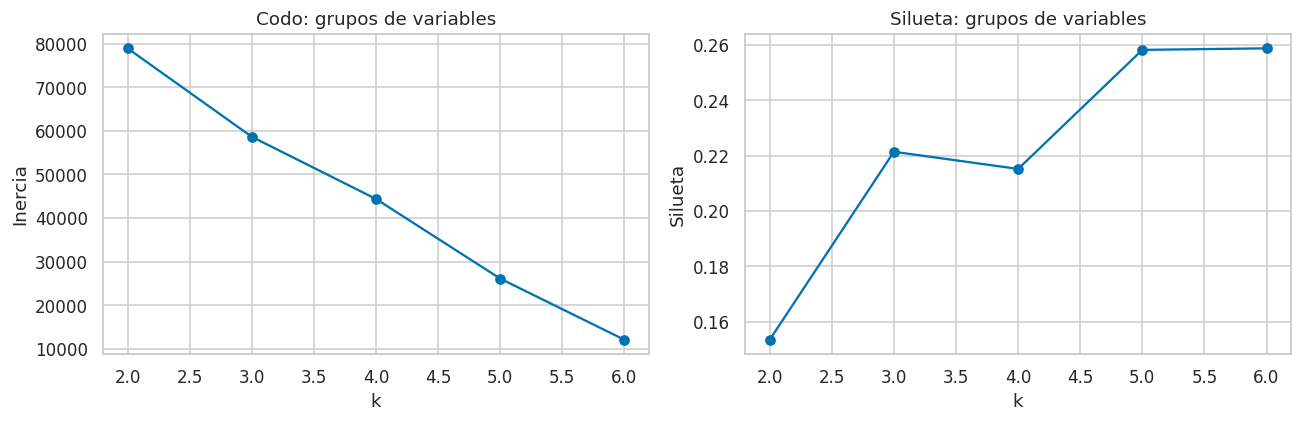

,variable,grupo_variable_kmeans
6,temperatura_bateria_c,0
7,temperatura_ambiente_c,0
5,temperatura_electromotor_c,0
3,aceleracion_positiva_media_m_s2,1
2,aceleracion_m_s2,1
0,soc_inicio_pct,2
4,peso_actual_kg,3
8,pendiente_pct,4
1,velocidad_media_kmh,5


In [ ]:
filas_t = []
modelos_t = {}
for k in range(2, min(6, len(T) - 1) + 1):
    modelo = KMeans(n_clusters=k, n_init=20, random_state=SEMILLA).fit(T)
    modelos_t[k] = modelo
    filas_t.append({'k': k, 'inercia': modelo.inertia_, 'silueta': silueta_segura(T, modelo.labels_),
                    'grupo_minimo': int(np.bincount(modelo.labels_).min())})
evaluacion_t = pd.DataFrame(filas_t)
display(evaluacion_t)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(evaluacion_t['k'], evaluacion_t['inercia'], 'o-')
axes[0].set(title='Codo: grupos de variables', xlabel='k', ylabel='Inercia')
axes[1].plot(evaluacion_t['k'], evaluacion_t['silueta'], 'o-')
axes[1].set(title='Silueta: grupos de variables', xlabel='k', ylabel='Silueta')
plt.tight_layout()
plt.show()

K_VARIABLES = int(evaluacion_t.loc[evaluacion_t['silueta'].idxmax(), 'k'])
grupos_variables = pd.DataFrame({'variable': T.index, 'grupo_variable_kmeans': modelos_t[K_VARIABLES].labels_})
display(grupos_variables.sort_values('grupo_variable_kmeans'))

### 7.4 Reducción de dimensionalidad
Se dejaron comentadas dos alternativas de reducción:

* **Opción A:** reemplazar las variables por componentes PCA que retengan el 90 % de la varianza.
* **Opción B:** conservar una variable representativa por grupo de variables.

Se implementará como trabajos futuros.

In [1]:
# OPCIÓN A: reducir las observaciones a componentes que retengan el 90 % de la varianza.
# pca_reductor = PCA(n_components=0.90, svd_solver='full')
# X_reducida_pca = pd.DataFrame(pca_reductor.fit_transform(Z), index=Z.index)
# X_reducida_pca.columns = [f'PC_red_{i + 1}' for i in range(X_reducida_pca.shape[1])]
# display(X_reducida_pca.corr())  # ~0 por construcción: no prueba independencia ni utilidad predictiva.

# OPCIÓN B: una variable representativa por grupo de variables (provisional).
# representantes = []
# for grupo in np.unique(modelos_t[K_VARIABLES].labels_):
#     nombres = T.index[modelos_t[K_VARIABLES].labels_ == grupo]
#     perfiles = T.loc[nombres]
#     distancias = ((perfiles - perfiles.mean(axis=0)) ** 2).sum(axis=1)
#     representantes.append(distancias.idxmin())
# X_reducida_variables = X[representantes].copy()
# display(X_reducida_variables.corr())
# print('Revisar manualmente antes de aceptar:', representantes)


### 7.5 Matriz de correlación de las variables transpuestas y de su reducción

Se calcula la correlación entre las filas de `T` (equivale a la correlación entre variables originales) y la compara con una reconstrucción que usa solo dos componentes del PCA transpuesto.

La reconstrucción es un diagnóstico visual de la información perdida al reducir, no una reducción aprobada. La diferencia absoluta media entre ambas matrices mide cuánto se distorsiona la estructura de correlación.

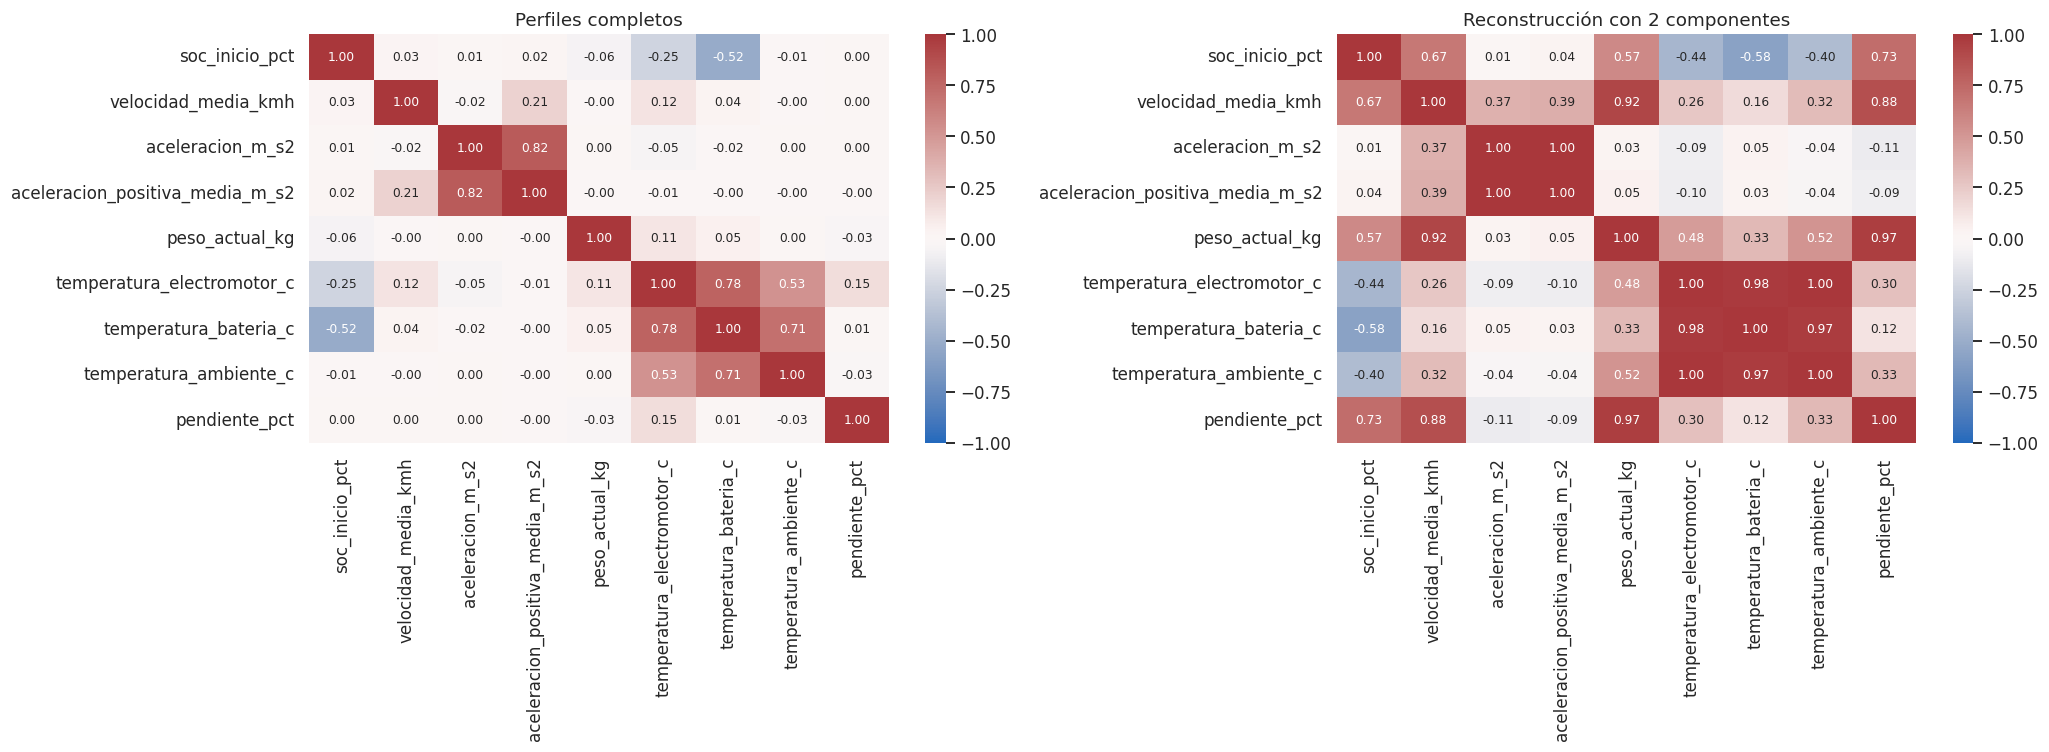

Diferencia absoluta media en correlaciones: 0.2493
Varianza retenida en esta vista: 0.5052


In [ ]:
corr_variables_t = T.T.corr()
N_COMPONENTES_VISTA = 2
T_reconstruida = pd.DataFrame(
    puntajes_t[:, :N_COMPONENTES_VISTA] @ pca_t.components_[:N_COMPONENTES_VISTA, :] + pca_t.mean_,
    index=T.index, columns=T.columns)
corr_reconstruida = T_reconstruida.T.corr()

fig, axes = plt.subplots(1, 2, figsize=(19, 7))
for ax, matriz, titulo in zip(axes, [corr_variables_t, corr_reconstruida],
                              ['Perfiles completos', f'Reconstrucción con {N_COMPONENTES_VISTA} componentes']):
    sns.heatmap(matriz, ax=ax, cmap='vlag', vmin=-1, vmax=1, center=0, annot=True, fmt='.2f', annot_kws={'size': 8})
    ax.set_title(titulo)
plt.tight_layout()
plt.show()

ERROR_CORRELACION = float(np.nanmean(np.abs(corr_variables_t - corr_reconstruida)))
print('Diferencia absoluta media en correlaciones:', round(ERROR_CORRELACION, 4))
print('Varianza retenida en esta vista:', round(float(pca_t.explained_variance_ratio_[:N_COMPONENTES_VISTA].sum()), 4))

### 7.7 Clustering aglomerativo (experimental)

**Qué hace:** (a) agrupa las variables jerárquicamente y muestra el dendrograma; (b) compara Ward con KMeans para las observaciones sobre una misma muestra de hasta 2.000 minutos.

**Por qué:** el método jerárquico es una alternativa a KMeans que no necesita fijar k de antemano (el dendrograma muestra todas las fusiones).

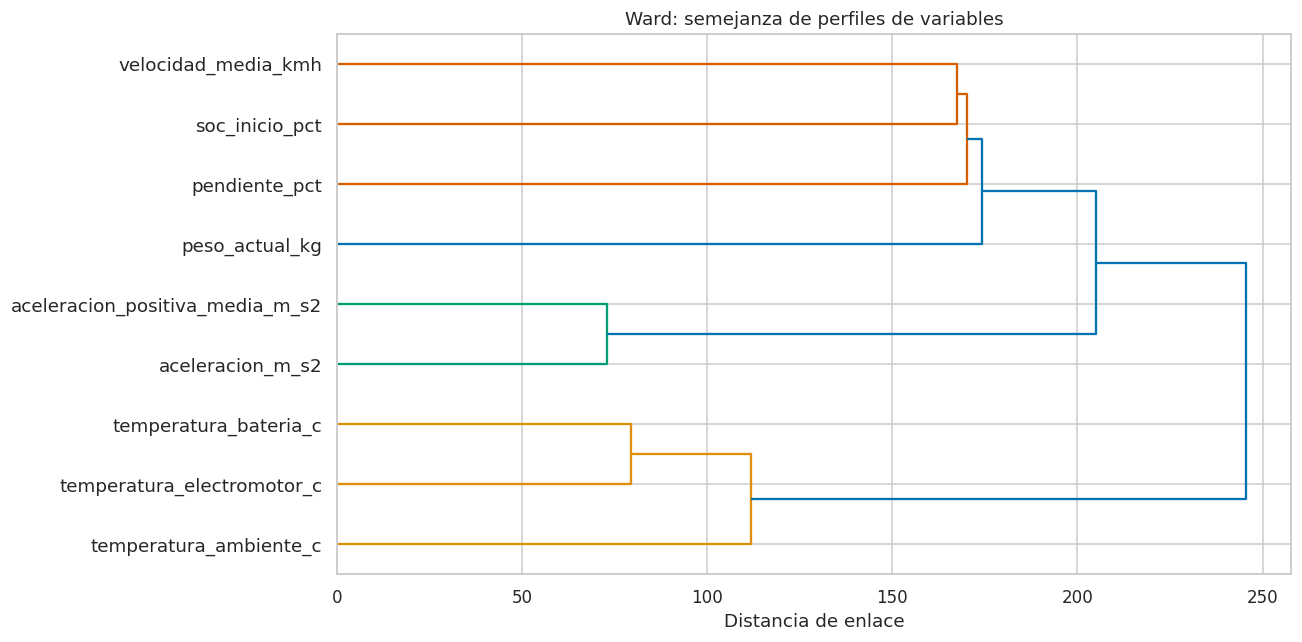

,variable,grupo_variable_kmeans,grupo_variable_ward
0,soc_inicio_pct,2,5
1,velocidad_media_kmh,5,4
2,aceleracion_m_s2,1,2
3,aceleracion_positiva_media_m_s2,1,2
4,peso_actual_kg,3,3
5,temperatura_electromotor_c,0,0
6,temperatura_bateria_c,0,0
7,temperatura_ambiente_c,0,0
8,pendiente_pct,4,1


ARI KMeans vs Ward (variables): 1.0


,k,silueta_ward,silueta_kmeans,ARI_entre_metodos
0,2,0.2145,0.2580,-0.0118
1,3,0.2254,0.2458,0.8021
2,4,0.2047,0.2398,0.8057
3,5,0.1997,0.2056,0.6276
4,6,0.2020,0.1981,0.5012


In [ ]:
arbol = linkage(T.to_numpy(), method='ward', metric='euclidean')
fig, ax = plt.subplots(figsize=(12, 6))
dendrogram(arbol, labels=T.index.tolist(), orientation='right', ax=ax)
ax.set(title='Ward: semejanza de perfiles de variables', xlabel='Distancia de enlace')
plt.tight_layout()
plt.show()

ward_variables = AgglomerativeClustering(n_clusters=K_VARIABLES, linkage='ward').fit_predict(T)
grupos_variables['grupo_variable_ward'] = ward_variables
display(grupos_variables)
print('ARI KMeans vs Ward (variables):', round(adjusted_rand_score(modelos_t[K_VARIABLES].labels_, ward_variables), 4))

Z_muestra = Z.sample(min(2000, len(Z)), random_state=SEMILLA).sort_index()
filas_ag = []
for k in [2, 3, 4, 5, 6]:
    etiquetas_ward = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(Z_muestra)
    etiquetas_km_k = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit_predict(Z_muestra)
    filas_ag.append({'k': k, 'silueta_ward': silueta_segura(Z_muestra, etiquetas_ward),
                     'silueta_kmeans': silueta_segura(Z_muestra, etiquetas_km_k),
                     'ARI_entre_metodos': adjusted_rand_score(etiquetas_ward, etiquetas_km_k)})
display(pd.DataFrame(filas_ag))

---
## 8. Cierre de la exploración: de los hallazgos a las decisiones de modelado

Resumen de los resultados numéricos.


In [ ]:
conclusiones_fase1 = pd.Series({
    'registros_entrenamiento_explorados': len(datos),
    'registros_test_reservados_sin_explorar': int((df_todo['rol'] == 'test').sum()),
    'variables_originales': len(COLUMNAS_REQUERIDAS),
    'variables_matriz_analitica': X.shape[1],
    'consumos_indefinidos_en_detencion': int(datos['consumo_kwh_km'].isna().sum()),
    'filas_eliminadas_o_imputadas': 0,
    'componentes_PCA_para_90_pct_varianza': n_componentes_90,
    'kmeans_k_propuesto_por_silueta': K_PROPUESTO,
    'kmeans_silueta': round(float(evaluacion_km.set_index('k').loc[K_ELEGIDO, 'silueta']), 4),
    'ARI_standard_vs_robust': round(float(ARI_ESCALADORES), 4),
    'dbscan_solucion_admisible': DBSCAN_ADMISIBLE,
    'dbscan_ruido_pct': round(float(evaluacion_db.set_index('candidato').loc[id_db, 'ruido_pct']), 3),
    'rendimiento_BUS3107_km_kwh': round(float(rendimiento_bus.loc['BUS3107', 'rendimiento_neto_km_kwh']), 4),
    'rendimiento_BUS3135_km_kwh': round(float(rendimiento_bus.loc['BUS3135', 'rendimiento_neto_km_kwh']), 4),
    'reduccion_dimensionalidad_aplicada': False,
}, name='resultado')
display(conclusiones_fase1.to_frame())

,resultado
registros_entrenamiento_explorados,14400
registros_test_reservados_sin_explorar,7200
variables_originales,31
variables_matriz_analitica,9
consumos_indefinidos_en_detencion,3420
filas_eliminadas_o_imputadas,0
componentes_PCA_para_90_pct_varianza,6
kmeans_k_propuesto_por_silueta,3
kmeans_silueta,0.2428
ARI_standard_vs_robust,0.4015


### Decisiones adoptadas para la Fase 2

| Hallazgo de la exploración | Decisión en la predicción | Razón |
|---|---|---|
| Los vacíos de `consumo_kwh_km` ocurren solo con distancia 0 (paradas de 1 minuto) | No se imputa ni se usa `consumo_kwh_km`; el rendimiento se obtiene como distancia / energía neta | El cociente está indefinido, no perdido; imputarlo crea una contradicción física |
| Energía, SOC, rpm y potencia son identidades entre sí | Se prohíbe usar como entrada cualquier variable del horizonte futuro | Evita que el modelo "reconstruya" la respuesta (fuga de información) |
| `odometro_km` y `desgaste_frenos_pct` crecen con el tiempo | Se excluyen de los predictores | Solo codifican la fecha y no se transfieren a otro autobús |
| `rpm_motor` es función de la velocidad; `asistente_escalada` de la pendiente | Se excluyen | Redundancia |
| Las variables están en escalas muy distintas (kg, °C, kWh) | StandardScaler ajustado solo con entrenamiento, para LSTM, ANN y SVR | Redes y SVR dependen de la escala; los árboles no |
| La ruta condiciona el consumo y se conoce al emitir la predicción | One-hot de `id_ruta` como entrada | Evita una jerarquía artificial entre rutas |
| PCA y clusters se ajustaron con todos los datos de exploración y las señales físicas son pocas (12) e interpretables | No se usa PCA ni etiquetas de cluster como entradas | Evita fuga y pérdida de interpretabilidad; la reducción queda como experimento comentado |
| Los dos autobuses de entrenamiento ocupan zonas equivalentes del plano PCA | Se tratan como un único conjunto de entrenamiento | Más ejemplos y diversidad de vehículos |
| El rendimiento de un minuto es inestable (paradas, regeneración) | Se predice sobre un horizonte de 15 minutos | Agregar suaviza la indefinición y es útil para planificación |

---
# FASE 2 · PREDICCIÓN DEL RENDIMIENTO ENERGÉTICO

## 9. Diseño de la predicción y particiones

### 9.1 Problema, horizonte y parámetros fijados antes de mirar el test

**Problema:** al terminar **15 minutos de historial**, anticipar la energía neta (kWh) y la distancia (km) de los **siguientes 15 minutos**. Su cociente es el rendimiento futuro (km/kWh).

**Por qué predecir dos magnitudes y no el rendimiento directamente:** el rendimiento es un cociente inestable (explota cuando la energía neta se acerca a cero por regeneración). Energía y distancia son magnitudes físicas integradas, siempre definidas y mucho más fáciles de modelar; el rendimiento se reconstruye después y se evalúa por separado.


### 9.2 Particiones

* **Entrenamiento:** jornadas 1–24 de BUS3107 y de BUS3135.
* **Validación:** jornadas 25–30 de BUS3107 y de BUS3135 (cronológica; elige hiperparámetros, número de épocas/árboles y el modelo final).
* **Test:** BUS3125 completo (30 jornadas), un vehículo que los modelos nunca han visto.

No se usa `train_test_split` aleatorio: en series temporales mezclar minutos vecinos entre entrenamiento y validación filtraría información.

In [ ]:
HISTORIAL = 15
HORIZONTE = 15
PASO_ENTRENAMIENTO = 5
PASO_EVALUACION = HORIZONTE
E_MIN = 0.5            # kWh netos mínimos para interpretar el rendimiento.
D_MIN = 0.1            # km mínimos para interpretar el rendimiento.
R_MIN_MAPE = 0.05      # km/kWh mínimos para calcular el MAPE del rendimiento.
SOC_RESERVA = 15.0     # Escenario editable de autonomía (no es una recomendación operativa).
EPOCAS_MAX = 60
PACIENCIA = 8
JORNADAS_VALIDACION = 6

# Señales de entrada. Todas se observan DENTRO del historial (nunca del futuro).
FEATURES = [
    'soc_pct', 'velocidad_media_kmh', 'aceleracion_m_s2', 'aceleracion_positiva_media_m_s2',
    'peso_actual_kg', 'temperatura_electromotor_c', 'temperatura_bateria_c', 'temperatura_ambiente_c',
    'pendiente_pct', 'energia_neta_kwh', 'energia_regenerada_kwh', 'sentido_marcha',
]

tabla_entrenamiento_total = df_todo[df_todo['rol'] == 'entrenamiento']
partes_train, partes_val = [], []
for bus in BUSES_ENTRENAMIENTO:
    sub = tabla_entrenamiento_total[tabla_entrenamiento_total['id_vehiculo'] == bus]
    dias = sorted(sub['fecha'].unique())
    partes_train.append(sub[sub['fecha'].isin(dias[:-JORNADAS_VALIDACION])])
    partes_val.append(sub[sub['fecha'].isin(dias[-JORNADAS_VALIDACION:])])

partes = {
    'train': pd.concat(partes_train),
    'validacion': pd.concat(partes_val),
    'test': df_todo[df_todo['rol'] == 'test'].copy(),
}

# Controles anti-fuga: el test es otro autobús y, dentro de cada bus, validación es posterior a train.
assert set(partes['test']['id_vehiculo']) == {BUS_TEST}
assert not set(partes['test']['id_vehiculo']) & set(partes['train']['id_vehiculo'])
for bus in BUSES_ENTRENAMIENTO:
    ultimo_train = partes['train'].loc[partes['train']['id_vehiculo'] == bus, 'fecha'].max()
    primer_val = partes['validacion'].loc[partes['validacion']['id_vehiculo'] == bus, 'fecha'].min()
    assert ultimo_train < primer_val

display(pd.DataFrame([{
    'particion': nombre, 'autobuses': ', '.join(sorted(t['id_vehiculo'].unique())),
    'jornadas_por_bus': t.groupby('id_vehiculo')['fecha'].nunique().iloc[0], 'filas': len(t),
} for nombre, t in partes.items()]))

,particion,autobuses,jornadas_por_bus,filas
0,train,"BUS3107, BUS3135",24,11520
1,validacion,"BUS3107, BUS3135",6,2880
2,test,BUS3125,30,7200


## 10. Construcción de secuencias sin información futura

Se recorre cada segmento continuo (autobús–jornada–ruta) y, para cada punto de corte, toma los 15 minutos anteriores como entrada y suma energía neta y distancia de los 15 minutos siguientes como etiquetas.

* Las ventanas se construyen después de separar las particiones, así ninguna cruza el límite entre entrenamiento, validación y test.
* Nunca atraviesan noches, cambios de ruta ni de autobús (por eso se usa el segmento).
* El historial incluye energía y SOC pasados, que sí están disponibles en la práctica; los valores del futuro solo aparecen como etiqueta.
* Las marcas de tiempo representan el inicio del minuto: una ventana que termina en 06:14 predice desde el instante 06:15.
* Se excluyen odómetro, identificador del autobús (para que el modelo sea transferible a otro vehículo), desgaste acumulado y rpm redundantes.


In [ ]:
def crear_ventanas(tabla, paso):
    """Convierte una tabla de telemetría en pares (historial de 15 min -> energía y distancia de los 15 min siguientes)."""
    secuencias, etiquetas, filas_meta, idx_historia, idx_objetivo = [], [], [], [], []
    for _, g in tabla.groupby('segmento', sort=False):
        g = g.sort_values('fecha_hora')
        for i in range(HISTORIAL, len(g) - HORIZONTE + 1, paso):
            hist = g.iloc[i - HISTORIAL:i]
            fut = g.iloc[i:i + HORIZONTE]
            assert hist['fecha_hora'].iloc[-1] + pd.Timedelta(minutes=1) == fut['fecha_hora'].iloc[0]
            secuencias.append(hist[FEATURES].to_numpy(dtype=np.float32))
            etiquetas.append([fut['energia_neta_kwh'].sum(), fut['distancia_km'].sum()])
            idx_historia.append(hist.index.to_numpy())
            idx_objetivo.append(fut.index.to_numpy())
            filas_meta.append({
                'id_vehiculo': hist['id_vehiculo'].iloc[-1], 'id_ruta': hist['id_ruta'].iloc[-1],
                'fecha': hist['fecha'].iloc[-1], 'inicio_historial': hist['fecha_hora'].iloc[0],
                'instante_prediccion': fut['fecha_hora'].iloc[0],
                'fin_objetivo': fut['fecha_hora'].iloc[-1] + pd.Timedelta(minutes=1),
                'soc_actual_pct': hist['soc_pct'].iloc[-1],
                'capacidad_actual_kwh': hist['capacidad_util_bateria_kwh'].iloc[-1],
                'energia_historial_kwh': hist['energia_neta_kwh'].sum(),
                'distancia_historial_km': hist['distancia_km'].sum(),
            })
    return {'raw': np.asarray(secuencias), 'y': np.asarray(etiquetas), 'meta': pd.DataFrame(filas_meta),
            'indices_historia': np.asarray(idx_historia), 'indices_objetivo': np.asarray(idx_objetivo)}


ventanas = {nombre: crear_ventanas(t, PASO_ENTRENAMIENTO if nombre == 'train' else PASO_EVALUACION)
            for nombre, t in partes.items()}

for nombre, v in ventanas.items():
    assert len(v['raw']) > 0 and (v['meta']['inicio_historial'] < v['meta']['instante_prediccion']).all()
    if nombre != 'train':  # los objetivos de validación y test no deben solaparse
        assert len(np.unique(v['indices_objetivo'])) == v['indices_objetivo'].size

display(pd.DataFrame([{
    'particion': nombre, 'secuencias': len(v['y']),
    'energia_neta_no_positiva': int((v['y'][:, 0] <= 0).sum()),
    'rendimiento_interpretable': int(((v['y'][:, 0] > E_MIN) & (v['y'][:, 1] > D_MIN)).sum()),
} for nombre, v in ventanas.items()]))
print('Forma de las secuencias de entrenamiento (ejemplos, minutos, variables):', ventanas['train']['raw'].shape)

,particion,secuencias,energia_neta_no_positiva,rendimiento_interpretable
0,train,1584,254,1294
1,validacion,144,27,108
2,test,360,66,270


Forma de las secuencias de entrenamiento (ejemplos, minutos, variables): (1584, 15, 12)


**Lectura:** las ventanas con energía neta no positiva son tramos donde la regeneración compensa o supera al consumo (bajadas). No se eliminan: son comportamiento real del vehículo y el modelo debe aprenderlo. Para ellas el rendimiento convencional queda indefinido (por eso se informa cuántas ventanas son interpretables).

## 11. Escalado y codificación ajustados solo con entrenamiento

* `StandardScaler` de las señales de entrada y de las dos etiquetas, ajustado con las ventanas de entrenamiento.
* One-hot de la ruta, también ajustado con entrenamiento.
* Dos representaciones del mismo historial:
  * **Secuencial** (15 × variables) para la **LSTM**, conservando el orden temporal.
  * **Tabular** para XGBoost, RF, GBDT, SVR y ANN: último valor, media, desviación y tendencia de cada señal (4 × 12 = 48 variables) más la ruta.

**Por qué:** si el escalador se ajustara con todos los datos, la media y desviación del test contaminarían el entrenamiento (fuga de información). Las etiquetas se estandarizan para que la pérdida no esté dominada por los kWh frente a los km, y todas las métricas se calculan después de invertir esa transformación, en unidades físicas. Los árboles no necesitan escalado, pero comparten la misma representación para que la comparación sea justa. No se aplica PCA.

In [ ]:
N_VARIABLES = len(FEATURES)

escalador_x = StandardScaler().fit(
    df_todo.loc[np.unique(ventanas['train']['indices_historia']), FEATURES].to_numpy())
escalador_y = StandardScaler().fit(ventanas['train']['y'])
try:
    codificador_pred = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    codificador_pred = OneHotEncoder(handle_unknown='ignore', sparse=False)
codificador_pred.fit(ventanas['train']['meta'][['id_ruta']])

NOMBRES_TABULARES = (
    [f'{c}_{estadistico}' for estadistico in ['ultimo', 'media', 'std', 'tendencia'] for c in FEATURES]
    + list(codificador_pred.get_feature_names_out()))


def construir_representaciones(raw, rutas_ohe):
    """Devuelve (secuencia escalada para LSTM, resumen tabular para los demás modelos)."""
    n = raw.shape[0]
    z = escalador_x.transform(raw.reshape(-1, N_VARIABLES)).reshape(raw.shape)
    secuencia = np.concatenate([z, np.repeat(rutas_ohe[:, None, :], HISTORIAL, axis=1)], axis=2).astype('float32')
    tabular = np.concatenate([
        raw[:, -1, :], raw.mean(axis=1), raw.std(axis=1),
        (raw[:, -1, :] - raw[:, 0, :]) / (HISTORIAL - 1), rutas_ohe], axis=1)
    return secuencia, tabular


for nombre, v in ventanas.items():
    v['ohe'] = codificador_pred.transform(v['meta'][['id_ruta']])
    v['seq'], v['tab'] = construir_representaciones(v['raw'], v['ohe'])
    v['ys'] = escalador_y.transform(v['y']).astype('float32')

assert np.isfinite(ventanas['train']['seq']).all()
print('LSTM (ejemplos, minutos, variables+ruta):', ventanas['train']['seq'].shape)
print('Tabular (ejemplos, variables):', ventanas['train']['tab'].shape)

LSTM (ejemplos, minutos, variables+ruta): (1584, 15, 15)
Tabular (ejemplos, variables): (1584, 51)


## 12. Métricas y criterio de selección

**Definiciones:** (el error se define como *predicción − observado*, de modo que un error medio positivo es *sobreestimación*):

| Métrica | Fórmula / significado |
|---|---|
| **RMSE** | $\sqrt{\text{media}(e^2)}$ · penaliza los errores grandes; misma unidad que el objetivo |
| **MAE** | media$(|e|)$ · error típico, menos sensible a casos extremos |
| **MAPE** | media$(|e|/|y|)\times100$ · error relativo; se calcula solo donde $|y|$ supera un umbral (E_MIN, D_MIN, R_MIN_MAPE) y se informa cuántos casos entran (`N_MAPE`) |
| **Error medio** | media$(e)$ · sesgo sistemático |
| **Desviación estándar** | desviación muestral de $e$ (`ddof=1`) · dispersión de los errores; **no** es un intervalo de confianza |
| **R²** | proporción de varianza explicada (apoyo) |

**Criterio de selección fijado antes de abrir el test:** RMSE conjunto de energía y distancia **estandarizadas, en validación**. El MAPE no se usa para elegir porque es inestable con energías cercanas a cero.

In [ ]:
def calcular_metricas(observado, predicho, umbral_mape=1e-8):
    """RMSE, MAE, MAPE, error medio, desviación estándar del error y R2 (error = predicho - observado)."""
    y = np.asarray(observado, dtype=float).ravel()
    p = np.asarray(predicho, dtype=float).ravel()
    ok = np.isfinite(y) & np.isfinite(p)
    y, p = y[ok], p[ok]
    if len(y) == 0:
        return dict(N=0, RMSE=np.nan, MAE=np.nan, MAPE_pct=np.nan, N_MAPE=0, Error_medio=np.nan, DE_error=np.nan, R2=np.nan)
    e = p - y
    mascara = np.abs(y) > umbral_mape
    return {
        'N': len(y),
        'RMSE': np.sqrt(np.mean(e ** 2)),
        'MAE': np.mean(np.abs(e)),
        'MAPE_pct': 100 * np.mean(np.abs(e[mascara]) / np.abs(y[mascara])) if mascara.any() else np.nan,
        'N_MAPE': int(mascara.sum()),
        'Error_medio': np.mean(e),
        'DE_error': np.std(e, ddof=1) if len(e) > 1 else np.nan,
        'R2': r2_score(y, p) if len(y) > 1 else np.nan,
    }


def rmse_estandarizado(prediccion, etiquetas_estandarizadas):
    """RMSE conjunto (energía y distancia estandarizadas): criterio de selección en validación."""
    return float(np.sqrt(np.mean((escalador_y.transform(prediccion) - etiquetas_estandarizadas) ** 2)))


def rendimiento(pares):
    """Rendimiento km/kWh = distancia / energía neta; NaN cuando el cociente no es interpretable."""
    pares = np.asarray(pares)
    r = np.full(len(pares), np.nan)
    valido = (pares[:, 0] > E_MIN) & (pares[:, 1] > D_MIN) & np.isfinite(pares).all(axis=1)
    r[valido] = pares[valido, 1] / pares[valido, 0]
    return r


modelos = {}            # nombre -> función que recibe una partición y devuelve [energía, distancia] en kWh y km
pred_validacion = {}
tiempos = {}
ajustes = []            # registro de cada configuración probada en validación

## 13. Referencias simples: promedio por ruta y persistencia

Se define dos modelos sin aprendizaje:

* **Media por ruta:** predice el promedio de energía y distancia de esa ruta en el entrenamiento.
* **Persistencia:** supone que los próximos 15 minutos consumirán lo mismo que los 15 anteriores.


In [ ]:
tabla_base = ventanas['train']['meta'][['id_ruta']].copy()
tabla_base[['energia', 'distancia']] = ventanas['train']['y']
base_ruta = tabla_base.groupby('id_ruta')[['energia', 'distancia']].mean()
base_global = ventanas['train']['y'].mean(axis=0)


def predecir_media_ruta(v):
    return np.stack([base_ruta.loc[r].to_numpy() if r in base_ruta.index else base_global for r in v['meta']['id_ruta']])


def predecir_persistencia(v):
    return v['meta'][['energia_historial_kwh', 'distancia_historial_km']].to_numpy() * HORIZONTE / HISTORIAL


modelos['Media_ruta'] = predecir_media_ruta
modelos['Persistencia'] = predecir_persistencia
for nombre in ['Media_ruta', 'Persistencia']:
    pred_validacion[nombre] = modelos[nombre](ventanas['validacion'])
    tiempos[nombre] = 0.0

display(pd.Series({n: rmse_estandarizado(p, ventanas['validacion']['ys']) for n, p in pred_validacion.items()},
                  name='RMSE_validacion_estandarizado'))

,RMSE_validacion_estandarizado
Media_ruta,0.8553
Persistencia,1.4885


## 14. XGBoost (Extreme Gradient Boosting)

Se entrena un regresor por objetivo (uno para energía, otro para distancia) y compara profundidades de árbol 2, 3 y 4, con un máximo de 400 árboles y parada temprana según el error en validación. Se conserva la configuración con menor RMSE conjunto de validación.

**XGBoost:** el estudio citado propuso un marco de predicción de consumo de autobuses eléctricos con potenciación de gradiente extrema. XGBoost combina muchos árboles pequeños, captura relaciones no lineales entre pendiente, peso y velocidad, y admite regularización (`reg_lambda`, `subsample`, `colsample_bytree`) para controlar el sobreajuste con pocos datos.

*Alcance:* aquí no se reproduce el marco integrado completo del artículo (no se dispone de sus datos meteorológicos y viales ni del módulo cinemático); se adopta su algoritmo central sobre la telemetría disponible.

In [ ]:
inicio = time.perf_counter()
candidatos_xgb = []
for profundidad in [2, 3, 4]:
    estimadores = []
    for j in range(2):  # j=0 energía, j=1 distancia
        modelo = xgb.XGBRegressor(
            n_estimators=400, max_depth=profundidad, learning_rate=.04, subsample=.85, colsample_bytree=.85,
            reg_lambda=5, objective='reg:squarederror', eval_metric='rmse', early_stopping_rounds=25,
            tree_method='hist', n_jobs=2, random_state=SEMILLA)
        modelo.fit(ventanas['train']['tab'], ventanas['train']['ys'][:, j],
                   eval_set=[(ventanas['validacion']['tab'], ventanas['validacion']['ys'][:, j])], verbose=False)
        estimadores.append(modelo)
    pred_v = escalador_y.inverse_transform(np.column_stack([m.predict(ventanas['validacion']['tab']) for m in estimadores]))
    puntaje = rmse_estandarizado(pred_v, ventanas['validacion']['ys'])
    candidatos_xgb.append((puntaje, profundidad, estimadores, pred_v))
    ajustes.append({'modelo': 'XGBoost', 'configuracion': f'max_depth={profundidad}', 'score_validacion': puntaje})

_, profundidad_xgb, xgb_modelos, pred_v = min(candidatos_xgb, key=lambda t: t[0])
modelos['XGBoost'] = lambda v: escalador_y.inverse_transform(np.column_stack([m.predict(v['tab']) for m in xgb_modelos]))
pred_validacion['XGBoost'] = pred_v
tiempos['XGBoost'] = time.perf_counter() - inicio
print('Profundidad seleccionada:', profundidad_xgb, '| árboles usados (energía, distancia):', [m.best_iteration + 1 for m in xgb_modelos])
display(pd.DataFrame([a for a in ajustes if a['modelo'] == 'XGBoost']))

Profundidad seleccionada: 4 | árboles usados (energía, distancia): [137, 284]


,modelo,configuracion,score_validacion
0,XGBoost,max_depth=2,0.0640
1,XGBoost,max_depth=3,0.0580
2,XGBoost,max_depth=4,0.0555


## 15. LSTM (Long Short-Term Memory)

Se entrena una red recurrente que lee los 15 minutos de historial en orden y emite dos salidas (energía y distancia futuras). Arquitectura: una capa **LSTM** → **Dropout** (10 %) → capa densa de 16 neuronas → salida lineal de 2 valores. Se comparan 16, 32 y 64 unidades LSTM.

**LSTM:** la investigación de referencia la usó para estimar el estado de salud (SOH) de baterías porque su memoria interna captura dependencias temporales. Aquí se adapta al rendimiento energético: el consumo de los próximos minutos depende de la dinámica reciente (aceleración, pendiente que se acaba de recorrer, estado térmico), no solo del instante actual. Se aprovecha el mismo principio (memoria temporal) con otra variable objetivo, y por ello se auditan en la sección 22 qué señales aportan realmente.

**Detalles técnicos y su razón:**
* **Salida lineal:** la energía neta puede ser negativa (regeneración) y no debe recortarse.
* **Pérdida MSE** sobre las etiquetas estandarizadas.
* **Parada temprana** con paciencia de 8 épocas, restaurando los pesos de la mejor época de validación.


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 15, 15)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │         6,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,120 (78.60 KB)

 Trainable params: 6,706 (26.20 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 13,414 (52.40 KB)

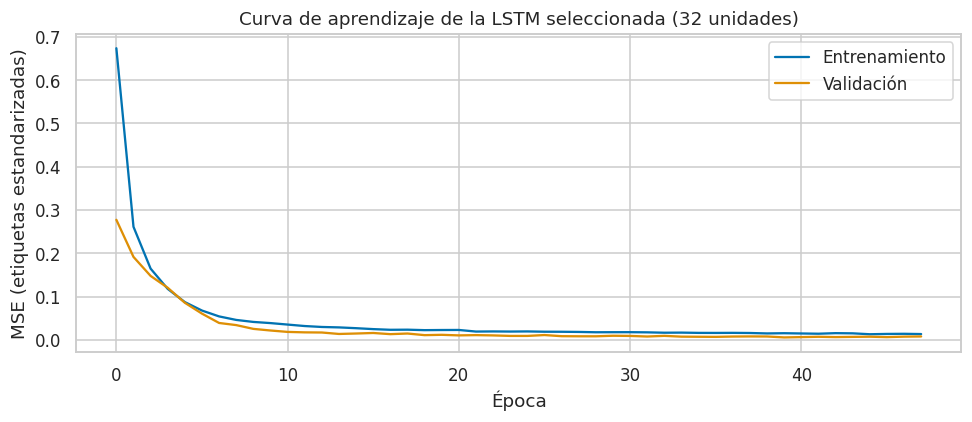

,modelo,configuracion,score_validacion
0,LSTM,unidades=16,0.0861
1,LSTM,unidades=32,0.0752
2,LSTM,unidades=64,0.0780


In [ ]:
def crear_dataset_tf(entradas, objetivos, tamano_lote=32):
    """Dataset de TensorFlow sin barajar y con un solo hilo (reproducibilidad)."""
    ds = tf.data.Dataset.from_tensor_slices((entradas.astype('float32'), objetivos.astype('float32'))).batch(tamano_lote)
    opciones = tf.data.Options()
    opciones.threading.private_threadpool_size = 1
    opciones.threading.max_intra_op_parallelism = 1
    return ds.with_options(opciones)


def crear_red(forma_entrada, n_salidas, unidades=32, tipo='LSTM'):
    """Red con capa LSTM (secuencias) o densa (tabular), Dropout y salida lineal."""
    entrada = tf.keras.Input(shape=forma_entrada)
    if tipo == 'LSTM':
        h = tf.keras.layers.LSTM(unidades)(entrada)
    else:
        h = tf.keras.layers.Dense(32, activation='relu')(entrada)
    h = tf.keras.layers.Dropout(.10)(h)
    h = tf.keras.layers.Dense(16, activation='relu')(h)
    salida = tf.keras.layers.Dense(n_salidas)(h)
    red = tf.keras.Model(entrada, salida)
    red.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=.001, clipnorm=1.), loss='mse')
    return red


def entrenar_red(red, entradas, objetivos, entradas_val, objetivos_val):
    parada = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=PACIENCIA, restore_best_weights=True)
    return red.fit(crear_dataset_tf(entradas, objetivos), validation_data=crear_dataset_tf(entradas_val, objetivos_val),
                   epochs=EPOCAS_MAX, callbacks=[parada], verbose=0)


def salida_red(red, entradas):
    """Predice por lotes y devuelve un arreglo NumPy."""
    return np.concatenate([red(entradas[i:i + 256].astype('float32'), training=False).numpy()
                           for i in range(0, len(entradas), 256)])


inicio = time.perf_counter()
candidatos_lstm = []
for unidades in [16, 32, 64]:
    tf.keras.utils.set_random_seed(SEMILLA)
    red = crear_red(ventanas['train']['seq'].shape[1:], 2, unidades=unidades)
    historia = entrenar_red(red, ventanas['train']['seq'], ventanas['train']['ys'],
                            ventanas['validacion']['seq'], ventanas['validacion']['ys'])
    pred_v = escalador_y.inverse_transform(salida_red(red, ventanas['validacion']['seq']))
    puntaje = rmse_estandarizado(pred_v, ventanas['validacion']['ys'])
    candidatos_lstm.append((puntaje, unidades, red, historia.history, pred_v))
    ajustes.append({'modelo': 'LSTM', 'configuracion': f'unidades={unidades}', 'score_validacion': puntaje})

_, unidades_lstm, red_lstm, historia_lstm, pred_v = min(candidatos_lstm, key=lambda t: t[0])
modelos['LSTM'] = lambda v: escalador_y.inverse_transform(salida_red(red_lstm, v['seq']))
pred_validacion['LSTM'] = pred_v
tiempos['LSTM'] = time.perf_counter() - inicio
red_lstm.summary()

plt.figure(figsize=(9, 4))
plt.plot(historia_lstm['loss'], label='Entrenamiento')
plt.plot(historia_lstm['val_loss'], label='Validación')
plt.title(f'Curva de aprendizaje de la LSTM seleccionada ({unidades_lstm} unidades)')
plt.xlabel('Época')
plt.ylabel('MSE (etiquetas estandarizadas)')
plt.legend()
plt.tight_layout()
plt.show()
display(pd.DataFrame([a for a in ajustes if a['modelo'] == 'LSTM']))

## 16. Modelos de comparación: SVR, RF, GBDT y ANN

Las familias señaladas en el estudio de demanda energética de autobuses (Toronto): máquinas de vectores de soporte (**SVR**), bosques aleatorios (**RF**), árboles con potenciación de gradiente (**GBDT**) y una red neuronal artificial densa (**ANN**).

**Por qué cada una:**
* **SVR** (propuesta específica de este proyecto): con kernel RBF modela relaciones no lineales suaves y funciona bien con pocos ejemplos y muchas variables. Es sensible a la escala y a sus hiperparámetros, por eso va dentro de un *pipeline* con `StandardScaler` y se ajusta con una pequeña búsqueda en validación (C y épsilon).
* **RF:** promedio de muchos árboles decorrelacionados; robusto y casi sin ajuste.
* **GBDT:** potenciación secuencial de árboles poco profundos; en el estudio de referencia fue uno de los más precisos.
* **ANN:** perceptrón multicapa sobre las variables tabulares; permite contrastar "red densa" frente a "red recurrente" (LSTM).

RF y GBDT no necesitan escalado; SVR y ANN sí. GBDT y SVR se entrenan por objetivo (`MultiOutputRegressor`). Salvo SVR, las configuraciones son pequeñas y fijadas a priori: no se afirma que sean óptimas ni que reproduzcan los parámetros del artículo.

In [ ]:
inicio = time.perf_counter()
candidatos_svr = []
for C in [1, 10, 100]:
    for epsilon in [.01, .05, .10]:
        modelo = make_pipeline(StandardScaler(), MultiOutputRegressor(SVR(C=C, epsilon=epsilon, kernel='rbf')))
        modelo.fit(ventanas['train']['tab'], ventanas['train']['ys'])
        pred_v = escalador_y.inverse_transform(modelo.predict(ventanas['validacion']['tab']))
        puntaje = rmse_estandarizado(pred_v, ventanas['validacion']['ys'])
        candidatos_svr.append((puntaje, C, epsilon, modelo, pred_v))
        ajustes.append({'modelo': 'SVR', 'configuracion': f'C={C}, epsilon={epsilon}', 'score_validacion': puntaje})
puntaje, C_svr, epsilon_svr, svr_modelo, pred_v = min(candidatos_svr, key=lambda t: t[0])
modelos['SVR'] = lambda v: escalador_y.inverse_transform(svr_modelo.predict(v['tab']))
pred_validacion['SVR'] = pred_v
tiempos['SVR'] = time.perf_counter() - inicio
print(f'SVR seleccionada: C={C_svr}, epsilon={epsilon_svr}')

comparativos = {
    'RF': RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_features=.8, random_state=SEMILLA, n_jobs=2),
    'GBDT': MultiOutputRegressor(GradientBoostingRegressor(
        n_estimators=200, max_depth=2, learning_rate=.04, min_samples_leaf=5, random_state=SEMILLA)),
}
for nombre, modelo in comparativos.items():
    inicio = time.perf_counter()
    modelo.fit(ventanas['train']['tab'], ventanas['train']['ys'])
    modelos[nombre] = lambda v, m=modelo: escalador_y.inverse_transform(m.predict(v['tab']))
    pred_validacion[nombre] = modelos[nombre](ventanas['validacion'])
    tiempos[nombre] = time.perf_counter() - inicio

# ANN densa: mismas variables tabulares, escaladas con un escalador ajustado en entrenamiento.
escalador_ann = StandardScaler().fit(ventanas['train']['tab'])
inicio = time.perf_counter()
tf.keras.utils.set_random_seed(SEMILLA)
red_ann = crear_red((ventanas['train']['tab'].shape[1],), 2, tipo='ANN')
historia_ann = entrenar_red(red_ann, escalador_ann.transform(ventanas['train']['tab']), ventanas['train']['ys'],
                            escalador_ann.transform(ventanas['validacion']['tab']), ventanas['validacion']['ys'])
modelos['ANN'] = lambda v: escalador_y.inverse_transform(salida_red(red_ann, escalador_ann.transform(v['tab'])))
pred_validacion['ANN'] = modelos['ANN'](ventanas['validacion'])
tiempos['ANN'] = time.perf_counter() - inicio

tabla_ajustes = pd.DataFrame(ajustes).sort_values(['modelo', 'score_validacion'])
display(tabla_ajustes)

SVR seleccionada: C=1, epsilon=0.01


,modelo,configuracion,score_validacion
4,LSTM,unidades=32,0.0752
5,LSTM,unidades=64,0.0780
3,LSTM,unidades=16,0.0861
6,SVR,"C=1, epsilon=0.01",0.0732
9,SVR,"C=10, epsilon=0.01",0.0759
12,SVR,"C=100, epsilon=0.01",0.0786
7,SVR,"C=1, epsilon=0.05",0.0814
10,SVR,"C=10, epsilon=0.05",0.0819
13,SVR,"C=100, epsilon=0.05",0.0820
8,SVR,"C=1, epsilon=0.1",0.0949


## 17. Elección del modelo con validación (antes de abrir el test)

En esta sección se ordena los ocho modelos por el criterio predefinido (RMSE conjunto estandarizado en validación) y **fija** el modelo elegido.

**Por qué ahora y no después:** si el modelo se eligiera mirando el test, el test dejaría de ser independiente y sus métricas serían optimistas. A partir de aquí no se reentrena ni se ajusta nada con el test. El modelo elegido puede ser una referencia simple; no se fuerza que gane un modelo complejo.

,modelo,RMSE_validacion_estandarizado,segundos_ajuste
0,XGBoost,0.0555,3.4753
1,GBDT,0.0688,8.3279
2,RF,0.0708,6.9772
3,SVR,0.0732,5.2520
4,ANN,0.0739,8.6276
5,LSTM,0.0752,67.8005
6,Media_ruta,0.8553,0.0000
7,Persistencia,1.4885,0.0000


Modelo fijado ANTES de abrir el test: XGBoost


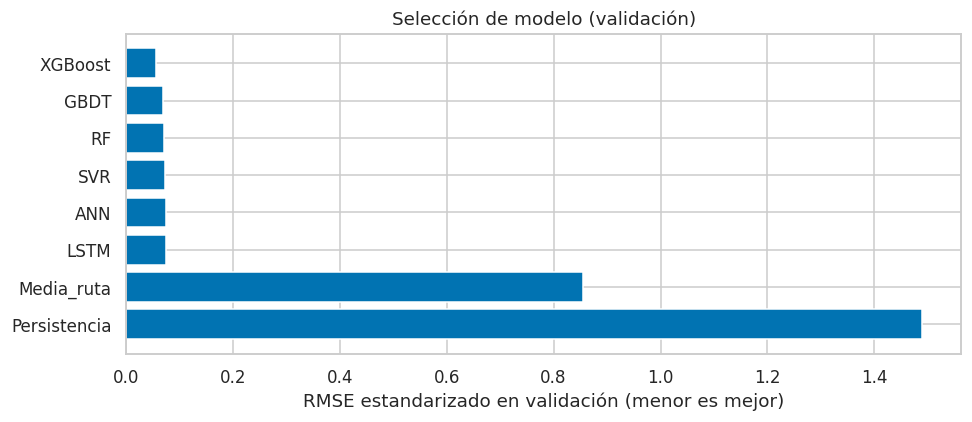

LECTURA: XGBoost obtiene el menor error de validación (0.056); la mejor referencia simple obtiene 0.855, es decir, el modelo reduce el error en 93.5 %.


In [ ]:
seleccion = pd.DataFrame([{
    'modelo': nombre,
    'RMSE_validacion_estandarizado': rmse_estandarizado(p, ventanas['validacion']['ys']),
    'segundos_ajuste': tiempos[nombre],
} for nombre, p in pred_validacion.items()]).sort_values('RMSE_validacion_estandarizado').reset_index(drop=True)
display(seleccion)

MODELO_ELEGIDO = seleccion.loc[0, 'modelo']
print('Modelo fijado ANTES de abrir el test:', MODELO_ELEGIDO)

plt.figure(figsize=(9, 4))
plt.barh(seleccion['modelo'][::-1], seleccion['RMSE_validacion_estandarizado'][::-1])
plt.xlabel('RMSE estandarizado en validación (menor es mejor)')
plt.title('Selección de modelo (validación)')
plt.tight_layout()
plt.show()

mejor_ref = seleccion[seleccion['modelo'].isin(['Media_ruta', 'Persistencia'])]['RMSE_validacion_estandarizado'].min()
mejor_val = seleccion.loc[0, 'RMSE_validacion_estandarizado']
print(f'LECTURA: {MODELO_ELEGIDO} obtiene el menor error de validación ({mejor_val:.3f}); '
      f'la mejor referencia simple obtiene {mejor_ref:.3f}, es decir, el modelo reduce el error '
      f'en {100 * (1 - mejor_val / mejor_ref):.1f} %.')

## 18. Test en el autobús no visto (BUS3125): energía y distancia

En este punto se predice con los ocho modelos ya entrenados las ventanas de **BUS3125** y calcula las cinco métricas solicitadas para energía neta (kWh) y distancia (km), en las tres particiones.

**Por qué mostrar también train y validación:** si el error de entrenamiento es mucho menor que el de test hay sobreajuste; si ambos son parecidos, el modelo generaliza. Las métricas de entrenamiento no son comparables en independencia (sus ventanas se solapan en pasos de 5 min); las de validación y test usan horizontes sin solapamiento.

**Sobre el significado del resultado:** los "valores observados" son etiquetas de un dataset ajustado. Un error bajo demuestra que el modelo reproduce bien los resultados en un vehículo nuevo, no que generalice a otras ciudades, baterías o datos reales. Se informan además las predicciones no físicas (distancias negativas) sin recortarlas.

In [ ]:
predicciones = {
    'train': {n: f(ventanas['train']) for n, f in modelos.items()},
    'validacion': pred_validacion,
    'test': {n: f(ventanas['test']) for n, f in modelos.items()},
}

filas_metricas = []
for particion, preds in predicciones.items():
    for nombre, p in preds.items():
        assert p.shape == ventanas[particion]['y'].shape and np.isfinite(p).all()
        for j, objetivo, unidad, umbral in [(0, 'energia_neta', 'kWh', E_MIN), (1, 'distancia', 'km', D_MIN)]:
            filas_metricas.append({'particion': particion, 'modelo': nombre, 'objetivo': objetivo, 'unidad': unidad,
                                   **calcular_metricas(ventanas[particion]['y'][:, j], p[:, j], umbral)})
metricas_fisicas = pd.DataFrame(filas_metricas)

columnas_metricas = ['modelo', 'N', 'RMSE', 'MAE', 'MAPE_pct', 'N_MAPE', 'Error_medio', 'DE_error', 'R2']
for objetivo in ['energia_neta', 'distancia']:
    print(f'\n=== TEST · {objetivo} ===')
    display(metricas_fisicas.query("particion == 'test' and objetivo == @objetivo")
            .sort_values('RMSE')[columnas_metricas].reset_index(drop=True))

print('\n=== RMSE por partición (diagnóstico de sobreajuste) ===')
display(metricas_fisicas.pivot_table(index=['objetivo', 'modelo'], columns='particion', values='RMSE')[['train', 'validacion', 'test']])

display(pd.DataFrame([{
    'modelo': n, 'distancias_predichas_negativas': int((p[:, 1] < 0).sum()),
    'energia_predicha_no_positiva': int((p[:, 0] <= 0).sum())} for n, p in predicciones['test'].items()]))


=== TEST · energia_neta ===


,modelo,N,RMSE,MAE,MAPE_pct,N_MAPE,Error_medio,DE_error,R2
0,XGBoost,360,0.2750,0.1940,5.2595,301,-0.0311,0.2736,0.9940
1,LSTM,360,0.3010,0.2327,7.0562,301,0.0280,0.3001,0.9928
2,GBDT,360,0.3159,0.2301,6.3765,301,-0.0504,0.3123,0.9921
3,RF,360,0.3181,0.2353,6.7157,301,-0.0490,0.3148,0.9920
4,SVR,360,0.3576,0.2486,6.9566,301,-0.0164,0.3577,0.9899
5,ANN,360,0.3617,0.2650,7.9510,301,-0.0715,0.3550,0.9897
6,Media_ruta,360,3.5423,3.1590,94.7951,301,0.0534,3.5469,0.0093
7,Persistencia,360,7.4788,6.6896,202.7590,301,0.3715,7.4800,-3.4160



=== TEST · distancia ===


,modelo,N,RMSE,MAE,MAPE_pct,N_MAPE,Error_medio,DE_error,R2
0,XGBoost,360,0.0293,0.0167,0.3000,360,-0.0066,0.0286,0.9982
1,GBDT,360,0.0402,0.0292,0.5239,360,-0.0131,0.0381,0.9966
2,ANN,360,0.0522,0.0405,0.7307,360,-0.0264,0.0451,0.9943
3,LSTM,360,0.0544,0.0418,0.7627,360,-0.0231,0.0493,0.9938
4,RF,360,0.0554,0.0355,0.6374,360,-0.0082,0.0549,0.9936
5,SVR,360,0.0663,0.0404,0.7280,360,-0.0016,0.0663,0.9908
6,Persistencia,360,0.3276,0.2867,5.2574,360,0.0074,0.3280,0.7753
7,Media_ruta,360,0.4980,0.4098,7.5557,360,-0.0552,0.4957,0.4806



=== RMSE por partición (diagnóstico de sobreajuste) ===


particion                   train  validacion    test
objetivo     modelo                                  
distancia    ANN           0.0436      0.0404  0.0522
             GBDT          0.0275      0.0306  0.0402
             LSTM          0.0404      0.0467  0.0544
             Media_ruta    0.5017      0.5012  0.4980
             Persistencia  0.3273      0.3154  0.3276
             RF            0.0356      0.0354  0.0554
             SVR           0.0176      0.0376  0.0663
             XGBoost       0.0098      0.0171  0.0293
energia_neta ANN           0.3254      0.3022  0.3617
             GBDT          0.2963      0.3019  0.3159
             LSTM          0.2676      0.2863  0.3010
             Media_ruta    3.4601      3.3749  3.5423
             Persistencia  6.7853      7.1550  7.4788
             RF            0.2438      0.2999  0.3181
             SVR           0.1896      0.3068  0.3576
             XGBoost       0.1983      0.2595  0.2750

,modelo,distancias_predichas_negativas,energia_predicha_no_positiva
0,Media_ruta,0,0
1,Persistencia,0,66
2,XGBoost,0,79
3,LSTM,0,48
4,SVR,0,54
5,RF,0,87
6,GBDT,0,76
7,ANN,0,77


### Lectura automática de los resultados de test (energía y distancia)


In [ ]:
def lectura_test(objetivo, unidad):
    t = metricas_fisicas.query("particion == 'test' and objetivo == @objetivo").sort_values('RMSE').reset_index(drop=True)
    media_obs = np.mean(ventanas['test']['y'][:, 0 if objetivo == 'energia_neta' else 1])
    mejor = t.iloc[0]
    elegido = t[t['modelo'] == MODELO_ELEGIDO].iloc[0]
    puesto = int(t.index[t['modelo'] == MODELO_ELEGIDO][0]) + 1
    ref = t[t['modelo'] == 'Media_ruta'].iloc[0]
    print(f'[{objetivo}] Menor RMSE en test: {mejor.modelo} ({mejor.RMSE:.3f} {unidad}; MAE {mejor.MAE:.3f}; '
          f'error medio {mejor.Error_medio:+.3f}; DE {mejor.DE_error:.3f}).')
    print(f'   El modelo elegido en validación ({MODELO_ELEGIDO}) queda en el puesto {puesto} de {len(t)} '
          f'con RMSE {elegido.RMSE:.3f} {unidad} (≈ {100 * elegido.RMSE / abs(media_obs):.1f} % de la media observada, '
          f'{media_obs:.2f} {unidad}) y R² {elegido.R2:.3f}.')
    print(f'   Frente a la media por ruta, reduce el RMSE en {100 * (1 - elegido.RMSE / ref.RMSE):.1f} %.')
    if mejor.modelo != MODELO_ELEGIDO:
        print(f'   Nota: {mejor.modelo} supera ligeramente al elegido en test, pero la elección se fijó con validación '
              f'y no se modifica mirando el test. Revisa si la diferencia es mayor que la incertidumbre (sección 21).')


lectura_test('energia_neta', 'kWh')
lectura_test('distancia', 'km')

[energia_neta] Menor RMSE en test: XGBoost (0.275 kWh; MAE 0.194; error medio -0.031; DE 0.274).
   El modelo elegido en validación (XGBoost) queda en el puesto 1 de 8 con RMSE 0.275 kWh (≈ 7.2 % de la media observada, 3.83 kWh) y R² 0.994.
   Frente a la media por ruta, reduce el RMSE en 92.2 %.
[distancia] Menor RMSE en test: XGBoost (0.029 km; MAE 0.017; error medio -0.007; DE 0.029).
   El modelo elegido en validación (XGBoost) queda en el puesto 1 de 8 con RMSE 0.029 km (≈ 0.5 % de la media observada, 5.39 km) y R² 0.998.
   Frente a la media por ruta, reduce el RMSE en 94.1 %.


## 19. Evaluación del rendimiento futuro (km/kWh)

Se calcula el rendimiento observado como *distancia / energía neta* del horizonte y el predicho como *distancia predicha / energía predicha*, y aplica las cinco métricas.

**Dos lecturas, por transparencia:**
1. **Casos propios:** cada modelo se evalúa donde su predicción es interpretable.
2. **Intersección común** (lectura principal): todos los modelos aprendidos se comparan sobre **exactamente los mismos casos**, para que ninguno parezca mejor por evaluarse en ventanas más fáciles. La persistencia se excluye de la intersección porque su predicción queda indefinida con frecuencia; se informa aparte con su cobertura.


In [ ]:
rend_obs = rendimiento(ventanas['test']['y'])
rend_pred = {n: rendimiento(p) for n, p in predicciones['test'].items()}
observado_valido = np.isfinite(rend_obs)

MODELOS_INTERSECCION = [n for n in rend_pred if n != 'Persistencia']
mascara_comun = observado_valido.copy()
for n in MODELOS_INTERSECCION:
    mascara_comun &= np.isfinite(rend_pred[n])

filas_cobertura, filas_rend = [], []
for nombre, r in rend_pred.items():
    validos = observado_valido & np.isfinite(r)
    filas_cobertura.append({
        'modelo': nombre, 'N_test': len(r), 'N_observado_interpretable': int(observado_valido.sum()),
        'N_pares_interpretables': int(validos.sum()),
        'cobertura_pct': 100 * validos.sum() / max(1, observado_valido.sum()),
        'prediccion_indefinida_con_observado_valido': int((observado_valido & ~np.isfinite(r)).sum())})
    filas_rend.append({'modelo': nombre, 'evaluacion': 'casos_propios',
                       **calcular_metricas(rend_obs[validos], r[validos], R_MIN_MAPE)})
    if nombre in MODELOS_INTERSECCION:
        filas_rend.append({'modelo': nombre, 'evaluacion': 'interseccion_comun',
                           **calcular_metricas(rend_obs[mascara_comun], r[mascara_comun], R_MIN_MAPE)})

tabla_cobertura = pd.DataFrame(filas_cobertura)
metricas_rendimiento = pd.DataFrame(filas_rend)
display(tabla_cobertura)
print(f'Casos con rendimiento observado interpretable: {int(observado_valido.sum())} de {len(rend_obs)} | '
      f'casos comunes a los modelos aprendidos: {int(mascara_comun.sum())}')

print('\n=== RENDIMIENTO (km/kWh) · intersección común (lectura principal) ===')
display(metricas_rendimiento.query("evaluacion == 'interseccion_comun'").sort_values('RMSE')[columnas_metricas].reset_index(drop=True))
print('=== RENDIMIENTO (km/kWh) · casos propios de cada modelo ===')
display(metricas_rendimiento.query("evaluacion == 'casos_propios'").sort_values('RMSE')[columnas_metricas].reset_index(drop=True))

,modelo,N_test,N_observado_interpretable,N_pares_interpretables,cobertura_pct,prediccion_indefinida_con_observado_valido
0,Media_ruta,360,270,270,100.0000,0
1,Persistencia,360,270,180,66.6667,90
2,XGBoost,360,270,270,100.0000,0
3,LSTM,360,270,270,100.0000,0
4,SVR,360,270,270,100.0000,0
5,RF,360,270,270,100.0000,0
6,GBDT,360,270,270,100.0000,0
7,ANN,360,270,270,100.0000,0


Casos con rendimiento observado interpretable: 270 de 360 | casos comunes a los modelos aprendidos: 270

=== RENDIMIENTO (km/kWh) · intersección común (lectura principal) ===


,modelo,N,RMSE,MAE,MAPE_pct,N_MAPE,Error_medio,DE_error,R2
0,XGBoost,270,0.2424,0.1034,4.6662,270,0.0043,0.2428,0.9681
1,SVR,270,0.2661,0.1161,5.1877,270,-0.0429,0.2631,0.9615
2,GBDT,270,0.2866,0.1243,5.5182,270,-0.0128,0.2868,0.9554
3,LSTM,270,0.3520,0.1386,5.4343,270,-0.0745,0.3447,0.9326
4,ANN,270,0.4332,0.1598,6.8577,270,0.0233,0.4334,0.8980
5,RF,270,0.5579,0.1845,6.8352,270,0.1074,0.5484,0.8308
6,Media_ruta,270,1.3529,0.9666,68.9538,270,-0.2107,1.3389,0.0049


=== RENDIMIENTO (km/kWh) · casos propios de cada modelo ===


,modelo,N,RMSE,MAE,MAPE_pct,N_MAPE,Error_medio,DE_error,R2
0,XGBoost,270,0.2424,0.1034,4.6662,270,0.0043,0.2428,0.9681
1,SVR,270,0.2661,0.1161,5.1877,270,-0.0429,0.2631,0.9615
2,GBDT,270,0.2866,0.1243,5.5182,270,-0.0128,0.2868,0.9554
3,LSTM,270,0.3520,0.1386,5.4343,270,-0.0745,0.3447,0.9326
4,ANN,270,0.4332,0.1598,6.8577,270,0.0233,0.4334,0.8980
5,RF,270,0.5579,0.1845,6.8352,270,0.1074,0.5484,0.8308
6,Media_ruta,270,1.3529,0.9666,68.9538,270,-0.2107,1.3389,0.0049
7,Persistencia,180,2.6451,2.2507,160.4484,180,-0.0198,2.6524,-2.4472


### 19.1 Tabla resumen final de test (las cinco métricas pedidas)

Se muestra en una tabla los datos obtendos de los modelos, RMSE, MAE, MAPE, error medio y desviación estándar para los tres objetivos (energía, distancia y rendimiento).

In [ ]:
bloques = []
for objetivo, etiqueta in [('energia_neta', 'Energía (kWh)'), ('distancia', 'Distancia (km)')]:
    t = metricas_fisicas.query("particion == 'test' and objetivo == @objetivo").set_index('modelo')
    bloques.append(t[['RMSE', 'MAE', 'MAPE_pct', 'Error_medio', 'DE_error']].add_prefix(f'{etiqueta} | '))
t = metricas_rendimiento.query("evaluacion == 'interseccion_comun'").set_index('modelo')
bloques.append(t[['RMSE', 'MAE', 'MAPE_pct', 'Error_medio', 'DE_error']].add_prefix('Rendimiento (km/kWh) | '))

tabla_final_test = pd.concat(bloques, axis=1).sort_values('Energía (kWh) | RMSE')
display(tabla_final_test.round(4))

# Lectura automática del rendimiento.
tr = metricas_rendimiento.query("evaluacion == 'interseccion_comun'").sort_values('RMSE').reset_index(drop=True)
mejor_r = tr.iloc[0]
print(f'\nLECTURA: en rendimiento (n={int(mejor_r.N)} casos comunes) el menor RMSE es de {mejor_r.modelo} '
      f'({mejor_r.RMSE:.3f} km/kWh; MAE {mejor_r.MAE:.3f}; MAPE {mejor_r.MAPE_pct:.1f} %; error medio {mejor_r.Error_medio:+.3f}).')
if MODELO_ELEGIDO in set(tr['modelo']):
    elegido_r = tr[tr['modelo'] == MODELO_ELEGIDO].iloc[0]
    print(f'El modelo elegido ({MODELO_ELEGIDO}) tiene RMSE {elegido_r.RMSE:.3f} km/kWh y MAPE {elegido_r.MAPE_pct:.1f} %.')
print('Error medio > 0 = sobreestima el rendimiento; < 0 = lo subestima.')

,Energía (kWh) | RMSE,Energía (kWh) | MAE,Energía (kWh) | MAPE_pct,Energía (kWh) | Error_medio,Energía (kWh) | DE_error,Distancia (km) | RMSE,Distancia (km) | MAE,Distancia (km) | MAPE_pct,Distancia (km) | Error_medio,Distancia (km) | DE_error,Rendimiento (km/kWh) | RMSE,Rendimiento (km/kWh) | MAE,Rendimiento (km/kWh) | MAPE_pct,Rendimiento (km/kWh) | Error_medio,Rendimiento (km/kWh) | DE_error
modelo,,,,,,,,,,,,,,,
XGBoost,0.2750,0.1940,5.2595,-0.0311,0.2736,0.0293,0.0167,0.3000,-0.0066,0.0286,0.2424,0.1034,4.6662,0.0043,0.2428
LSTM,0.3010,0.2327,7.0562,0.0280,0.3001,0.0544,0.0418,0.7627,-0.0231,0.0493,0.3520,0.1386,5.4343,-0.0745,0.3447
GBDT,0.3159,0.2301,6.3765,-0.0504,0.3123,0.0402,0.0292,0.5239,-0.0131,0.0381,0.2866,0.1243,5.5182,-0.0128,0.2868
RF,0.3181,0.2353,6.7157,-0.0490,0.3148,0.0554,0.0355,0.6374,-0.0082,0.0549,0.5579,0.1845,6.8352,0.1074,0.5484
SVR,0.3576,0.2486,6.9566,-0.0164,0.3577,0.0663,0.0404,0.7280,-0.0016,0.0663,0.2661,0.1161,5.1877,-0.0429,0.2631
ANN,0.3617,0.2650,7.9510,-0.0715,0.3550,0.0522,0.0405,0.7307,-0.0264,0.0451,0.4332,0.1598,6.8577,0.0233,0.4334
Media_ruta,3.5423,3.1590,94.7951,0.0534,3.5469,0.4980,0.4098,7.5557,-0.0552,0.4957,1.3529,0.9666,68.9538,-0.2107,1.3389
Persistencia,7.4788,6.6896,202.7590,0.3715,7.4800,0.3276,0.2867,5.2574,0.0074,0.3280,NaN,NaN,NaN,NaN,NaN



LECTURA: en rendimiento (n=270 casos comunes) el menor RMSE es de XGBoost (0.242 km/kWh; MAE 0.103; MAPE 4.7 %; error medio +0.004).
El modelo elegido (XGBoost) tiene RMSE 0.242 km/kWh y MAPE 4.7 %.
Error medio > 0 = sobreestima el rendimiento; < 0 = lo subestima.


## 20. Gráficas de observado vs. predicción (LSTM y XGBoost)

1. Serie de la **primera jornada de test**, con energía, distancia y rendimiento observados frente a los predichos por la **LSTM** (gráfica pedida), separando segmentos para no unir puntos de rutas distintas.
2. Serie de las primeras 120 ventanas de test con LSTM y XGBoost superpuestos.
3. Diagramas de dispersión observado-vs-predicho de todo el test; la diagonal punteada es la coincidencia perfecta.

**Cómo leerlas:** puntos sobre la diagonal indican predicción exacta. Un abanico creciente sugiere error que aumenta con la magnitud; una nube desplazada por encima o debajo indica sesgo. Los vacíos en la curva de rendimiento corresponden a casos no interpretables (se conservan como discontinuidades, no se interpolan).

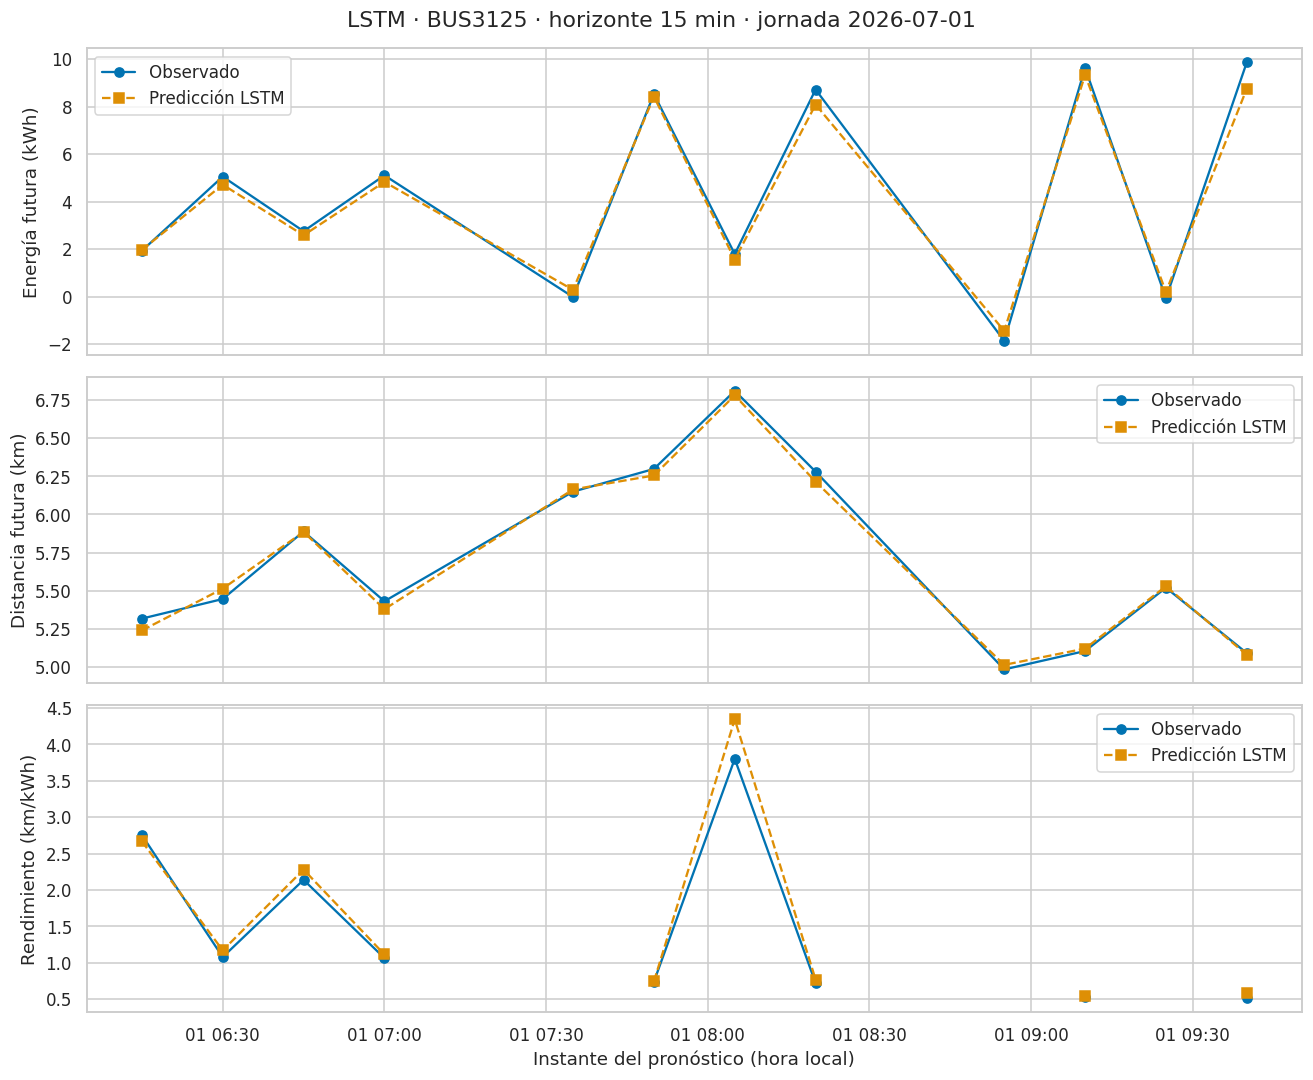

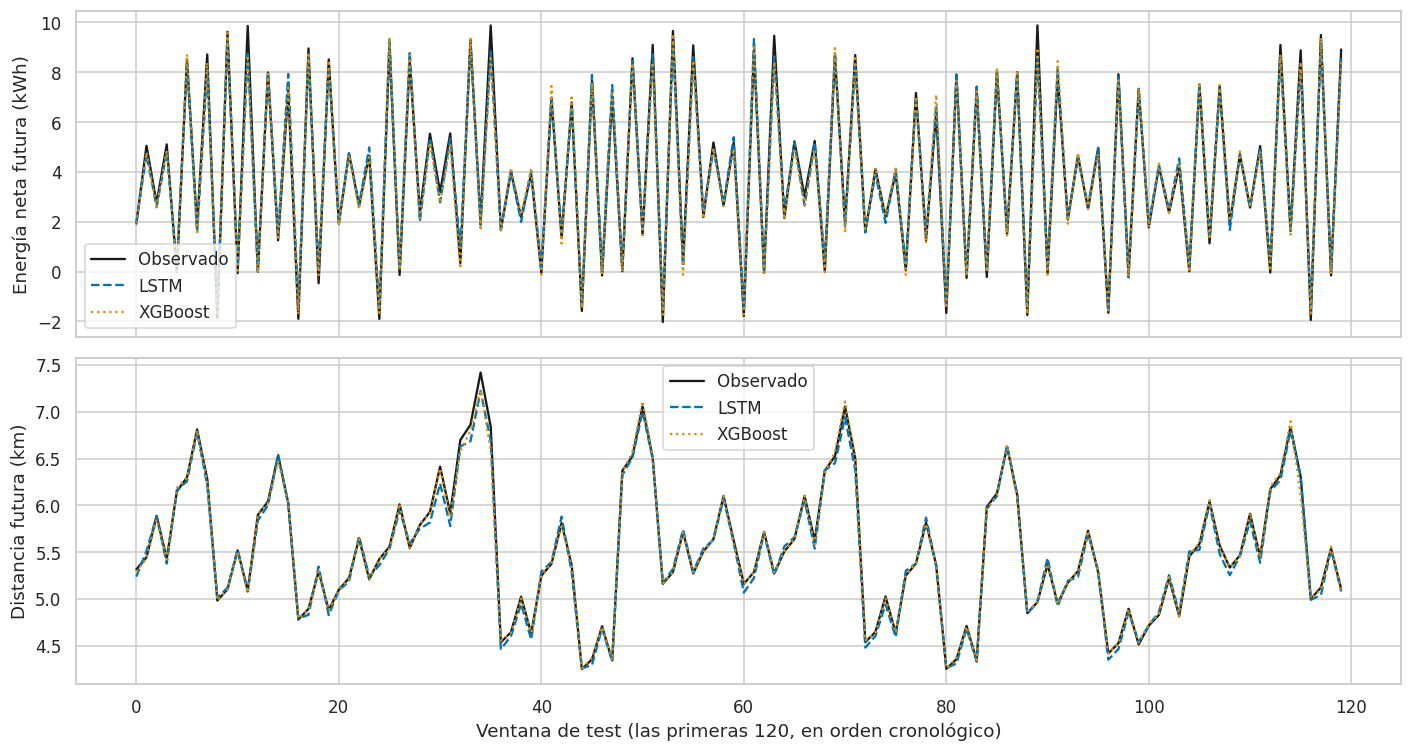

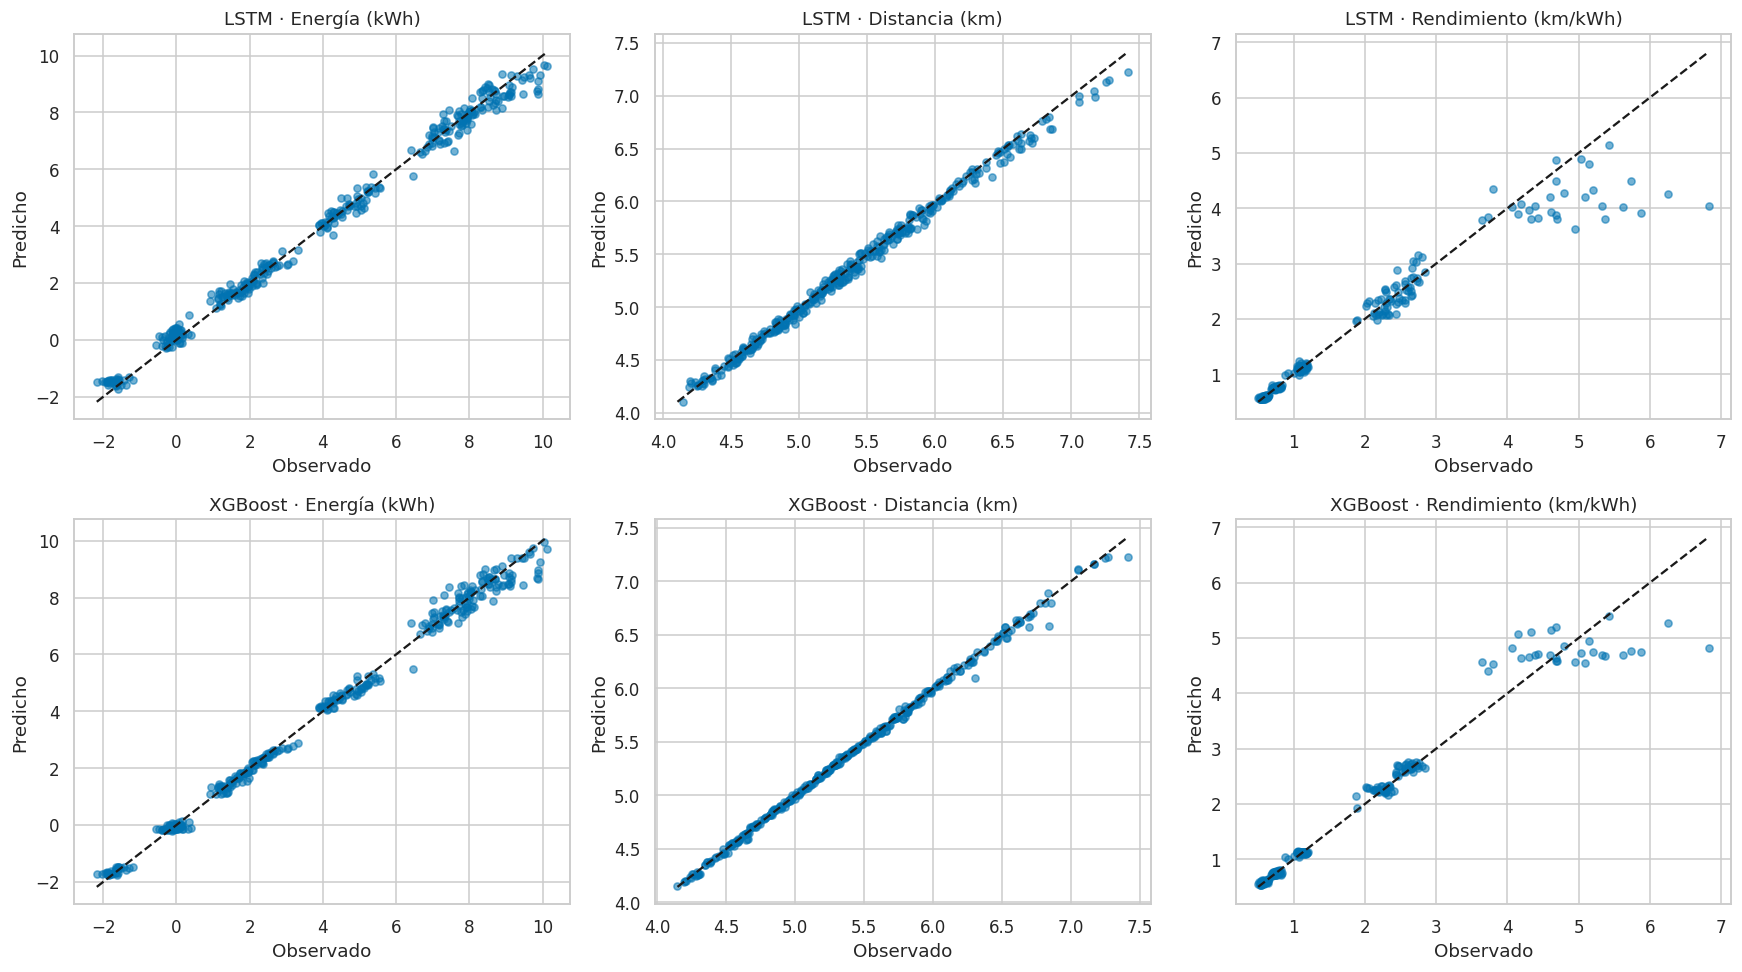

In [ ]:
meta_test = ventanas['test']['meta']
y_test = ventanas['test']['y']
dia_test = meta_test['fecha'].iloc[0]
en_dia = meta_test['fecha'].eq(dia_test).to_numpy()
horas = meta_test.loc[en_dia, 'instante_prediccion']

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for j, etiqueta in [(0, 'Energía futura (kWh)'), (1, 'Distancia futura (km)')]:
    axes[j].plot(horas, y_test[en_dia, j], 'o-', label='Observado')
    axes[j].plot(horas, predicciones['test']['LSTM'][en_dia, j], 's--', label='Predicción LSTM')
    axes[j].set_ylabel(etiqueta)
    axes[j].legend()
axes[2].plot(horas, rend_obs[en_dia], 'o-', label='Observado')
axes[2].plot(horas, rend_pred['LSTM'][en_dia], 's--', label='Predicción LSTM')
axes[2].set_ylabel('Rendimiento (km/kWh)')
axes[2].set_xlabel('Instante del pronóstico (hora local)')
axes[2].legend()
fig.suptitle(f'LSTM · {BUS_TEST} · horizonte {HORIZONTE} min · jornada {dia_test}')
plt.tight_layout()
plt.show()

N_GRAFICO = 120
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for j, etiqueta in [(0, 'Energía neta futura (kWh)'), (1, 'Distancia futura (km)')]:
    axes[j].plot(y_test[:N_GRAFICO, j], 'k-', lw=1.5, label='Observado')
    axes[j].plot(predicciones['test']['LSTM'][:N_GRAFICO, j], '--', label='LSTM')
    axes[j].plot(predicciones['test']['XGBoost'][:N_GRAFICO, j], ':', label='XGBoost')
    axes[j].set_ylabel(etiqueta)
    axes[j].legend()
axes[1].set_xlabel(f'Ventana de test (las primeras {N_GRAFICO}, en orden cronológico)')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for fila, nombre in enumerate(['LSTM', 'XGBoost']):
    for col, (obs, pred, titulo) in enumerate([
            (y_test[:, 0], predicciones['test'][nombre][:, 0], 'Energía (kWh)'),
            (y_test[:, 1], predicciones['test'][nombre][:, 1], 'Distancia (km)'),
            (rend_obs, rend_pred[nombre], 'Rendimiento (km/kWh)')]):
        validos = np.isfinite(obs) & np.isfinite(pred)
        ax = axes[fila, col]
        ax.scatter(obs[validos], pred[validos], s=22, alpha=.55)
        if validos.any():
            bajo = min(obs[validos].min(), pred[validos].min())
            alto = max(obs[validos].max(), pred[validos].max())
            ax.plot([bajo, alto], [bajo, alto], 'k--')
        ax.set(title=f'{nombre} · {titulo}', xlabel='Observado', ylabel='Predicho')
plt.tight_layout()
plt.show()

## 21. Diagnóstico del modelo elegido: ruta, SOC, jornada, residuos e incertidumbre

**Qué hace:**
* Métricas del modelo elegido **por ruta y por nivel de SOC inicial** (¿dónde se concentra el error?).
* Error por **jornada** (¿hay días atípicos?).
* Distribución y dispersión de los **residuos** (predicho − observado).
* **Intervalo bootstrap por jornada** del RMSE: se remuestrean jornadas completas con reemplazo (1.000 veces) para estimar cuánto cambiaría la métrica con otro conjunto de días.

**Por qué bootstrap por jornada y no por ventana:** las ventanas de un mismo día están correlacionadas (misma temperatura, mismo patrón de pasajeros); remuestrear ventanas sueltas subestimaría la incertidumbre. El intervalo permite saber si dos modelos con RMSE parecidos son realmente distinguibles.

**Cautela:** con 30 jornadas de un solo autobús, la desviación estándar del error no es una incertidumbre calibrada del pronóstico, y un grupo de SOC bajo puede tener pocas ventanas.

,agrupacion,grupo,modelo,N,RMSE,MAE,MAPE_pct,Error_medio,DE_error
0,id_ruta,R01,XGBoost,120,0.1959,0.1432,3.9481,-0.0566,0.1884
1,id_ruta,R02,XGBoost,120,0.2834,0.2009,6.2034,0.0026,0.2846
2,id_ruta,R03,XGBoost,120,0.3288,0.2380,6.0552,-0.0391,0.3278
3,grupo_soc,<15,XGBoost,16,0.4996,0.3333,7.6564,-0.2870,0.4224
4,grupo_soc,15–30,XGBoost,166,0.2514,0.1779,4.8185,-0.0013,0.2522
5,grupo_soc,≥30,XGBoost,178,0.2675,0.1966,5.4427,-0.0358,0.2658


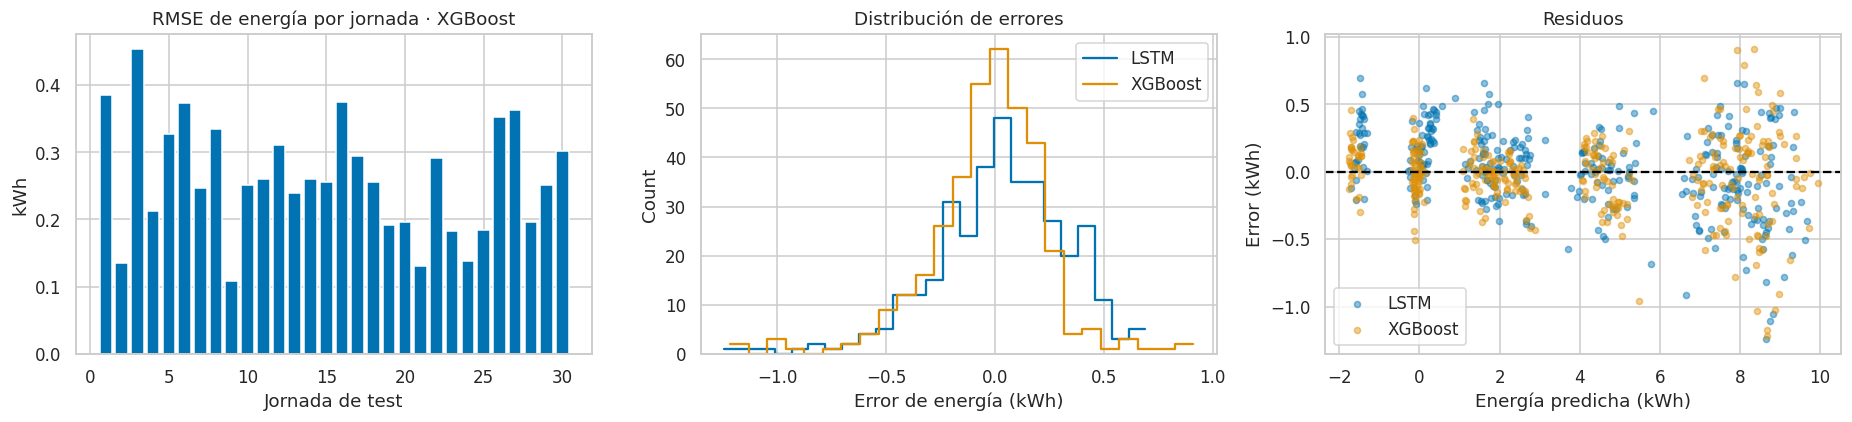

,modelo,RMSE_energia,IC95_energia_inf,IC95_energia_sup,RMSE_distancia,IC95_distancia_inf,IC95_distancia_sup
0,XGBoost,0.2750,0.2449,0.3037,0.0293,0.0194,0.0403
1,LSTM,0.3010,0.2702,0.3293,0.0544,0.0457,0.0643
2,GBDT,0.3159,0.2757,0.3538,0.0402,0.0327,0.0499
3,RF,0.3181,0.2843,0.3518,0.0554,0.0371,0.0758
4,SVR,0.3576,0.3144,0.3976,0.0663,0.0500,0.0833
5,ANN,0.3617,0.3163,0.4105,0.0522,0.0459,0.0580
6,Media_ruta,3.5423,3.4402,3.6551,0.4980,0.4271,0.5676


LECTURA: si los intervalos de dos modelos se solapan ampliamente, la diferencia entre ellos no es concluyente con 30 jornadas.


In [ ]:
detalle = meta_test.copy()
detalle['energia_observada_kwh'] = y_test[:, 0]
detalle['distancia_observada_km'] = y_test[:, 1]
detalle['rendimiento_observado_km_kwh'] = rend_obs
for n, p in predicciones['test'].items():
    detalle[f'{n}_energia_kwh'] = p[:, 0]
    detalle[f'{n}_distancia_km'] = p[:, 1]
    detalle[f'{n}_rendimiento_km_kwh'] = rend_pred[n]
detalle['grupo_soc'] = pd.cut(detalle['soc_actual_pct'], [-np.inf, 15, 30, np.inf], right=False, labels=['<15', '15–30', '≥30'])

diagnosticos = []
for columna in ['id_ruta', 'grupo_soc']:
    for grupo, sub in detalle.groupby(columna, observed=True):
        diagnosticos.append({'agrupacion': columna, 'grupo': str(grupo), 'modelo': MODELO_ELEGIDO,
                             **calcular_metricas(sub['energia_observada_kwh'], sub[f'{MODELO_ELEGIDO}_energia_kwh'], E_MIN)})
display(pd.DataFrame(diagnosticos)[['agrupacion', 'grupo', 'modelo', 'N', 'RMSE', 'MAE', 'MAPE_pct', 'Error_medio', 'DE_error']])

# Error por jornada del modelo elegido.
detalle['error_energia'] = detalle[f'{MODELO_ELEGIDO}_energia_kwh'] - detalle['energia_observada_kwh']
rmse_diario = detalle.groupby('fecha')['error_energia'].apply(lambda e: np.sqrt(np.mean(e ** 2)))
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].bar(range(1, len(rmse_diario) + 1), rmse_diario.values)
axes[0].set(title=f'RMSE de energía por jornada · {MODELO_ELEGIDO}', xlabel='Jornada de test', ylabel='kWh')
for n in ['LSTM', 'XGBoost']:
    e = predicciones['test'][n][:, 0] - y_test[:, 0]
    sns.histplot(e, bins=25, element='step', fill=False, label=n, ax=axes[1])
    axes[2].scatter(predicciones['test'][n][:, 0], e, label=n, alpha=.45, s=16)
axes[1].set(xlabel='Error de energía (kWh)', title='Distribución de errores')
axes[1].legend()
axes[2].axhline(0, color='black', ls='--')
axes[2].set(xlabel='Energía predicha (kWh)', ylabel='Error (kWh)', title='Residuos')
axes[2].legend()
plt.tight_layout()
plt.show()


def bootstrap_rmse_por_jornada(meta, observado, predicho, repeticiones=1000):
    """Intervalo percentil 95 % del RMSE remuestreando jornadas completas."""
    rng = np.random.default_rng(SEMILLA)
    ok = np.isfinite(observado) & np.isfinite(predicho)
    fechas = meta['fecha'].to_numpy()
    grupos = [np.where((fechas == d) & ok)[0] for d in pd.unique(fechas)]
    rmses = []
    for _ in range(repeticiones):
        elegidos = rng.integers(0, len(grupos), len(grupos))
        idx = np.concatenate([grupos[i] for i in elegidos])
        e = predicho[idx] - observado[idx]
        rmses.append(np.sqrt(np.mean(e ** 2)))
    return np.percentile(rmses, [2.5, 97.5])


filas_ic = []
for n in predicciones['test']:
    if n == 'Persistencia':
        continue
    p = predicciones['test'][n]
    ic_e = bootstrap_rmse_por_jornada(meta_test, y_test[:, 0], p[:, 0])
    ic_d = bootstrap_rmse_por_jornada(meta_test, y_test[:, 1], p[:, 1])
    filas_ic.append({'modelo': n,
                     'RMSE_energia': np.sqrt(np.mean((p[:, 0] - y_test[:, 0]) ** 2)), 'IC95_energia_inf': ic_e[0], 'IC95_energia_sup': ic_e[1],
                     'RMSE_distancia': np.sqrt(np.mean((p[:, 1] - y_test[:, 1]) ** 2)), 'IC95_distancia_inf': ic_d[0], 'IC95_distancia_sup': ic_d[1]})
tabla_ic = pd.DataFrame(filas_ic).sort_values('RMSE_energia').reset_index(drop=True)
display(tabla_ic)
print('LECTURA: si los intervalos de dos modelos se solapan ampliamente, la diferencia entre ellos no es concluyente con 30 jornadas.')

## 22. Variables potenciales: qué señales aportan a XGBoost y a la LSTM

¿qué variables del dataset sirven realmente para predecir el rendimiento?":

1. **Importancia interna de XGBoost** (ganancia de los árboles) sobre las 51 variables tabulares (48 estadísticos + 3 rutas).
2. **Importancia por permutación** (válida para *cualquier* modelo, incluida la LSTM): se baraja una señal entre ejemplos de **validación**, manteniendo intacta su estructura temporal, y se mide cuánto empeora el RMSE estandarizado. Si no empeora, el modelo no depende de esa señal.

**Por qué en validación y no en test:** usar el test para decidir qué variables importan sería una forma de fuga. La permutación se calcula sobre validación.

**Cómo leerla:** la importancia no es causalidad y se reparte entre variables correlacionadas (si dos señales dicen lo mismo, la permutación de una puede no afectar porque la otra la compensa). Tampoco equivale a las variables dominantes de los artículos, que usan otras fuentes y otro diseño.

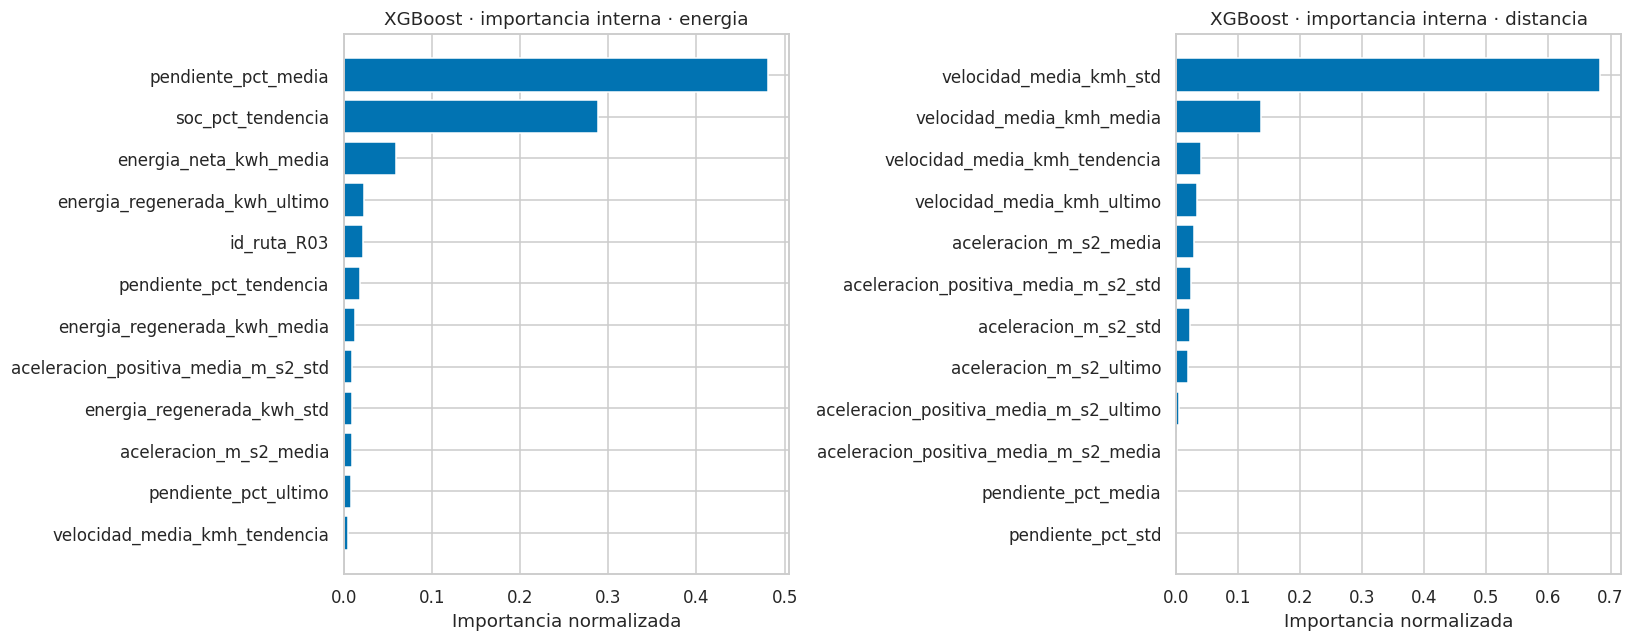

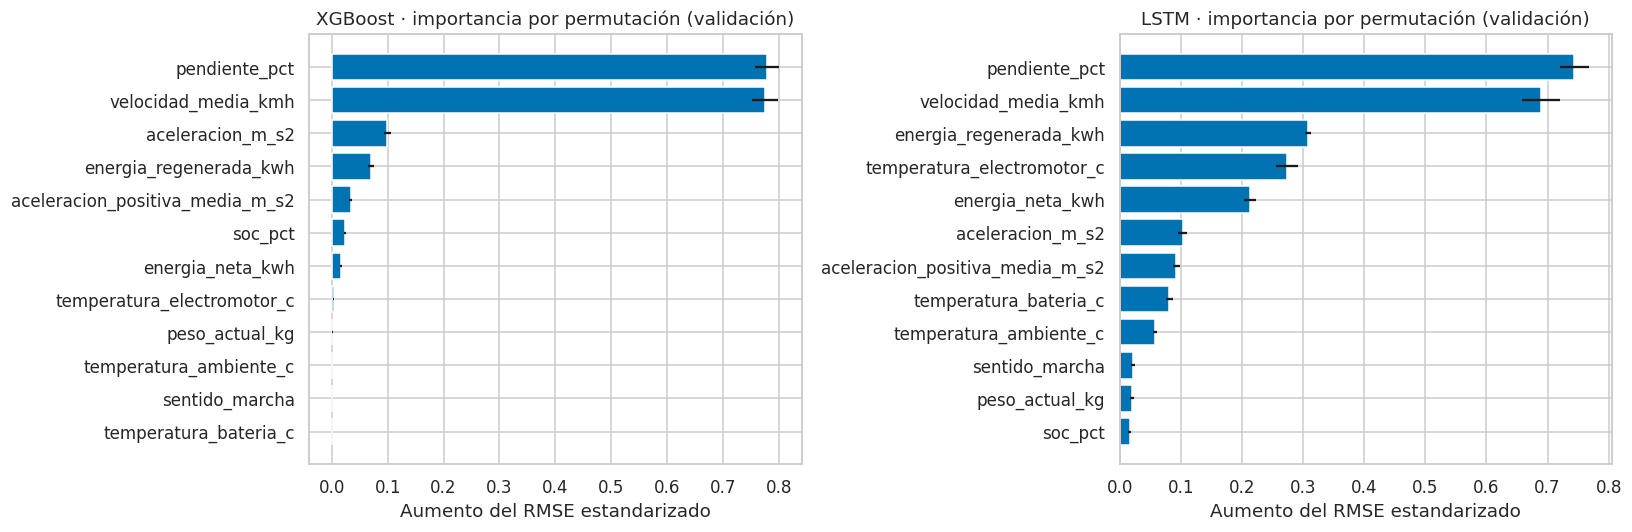

Señales más influyentes (permutación, validación):
  XGBoost: pendiente_pct, velocidad_media_kmh, aceleracion_m_s2, energia_regenerada_kwh
  LSTM   : pendiente_pct, velocidad_media_kmh, energia_regenerada_kwh, temperatura_electromotor_c
Señales sin aporte medible en ambos modelos (candidatas a retirar, a confirmar con más datos): ninguna


In [ ]:
def importancia_por_permutacion(nombre_modelo, particion, repeticiones=5):
    """Aumento del RMSE estandarizado al barajar cada señal de entrada entre ejemplos."""
    rng = np.random.default_rng(SEMILLA)
    base = rmse_estandarizado(modelos[nombre_modelo](particion), particion['ys'])
    filas = []
    for j, variable in enumerate(FEATURES):
        aumentos = []
        for _ in range(repeticiones):
            raw = particion['raw'].copy()
            raw[:, :, j] = raw[rng.permutation(len(raw)), :, j]
            seq, tab = construir_representaciones(raw, particion['ohe'])
            aumentos.append(rmse_estandarizado(modelos[nombre_modelo]({'seq': seq, 'tab': tab}), particion['ys']) - base)
        filas.append({'variable': variable, 'aumento_rmse': np.mean(aumentos), 'desv': np.std(aumentos)})
    return pd.DataFrame(filas).sort_values('aumento_rmse', ascending=False).reset_index(drop=True)


perm_xgb = importancia_por_permutacion('XGBoost', ventanas['validacion'])
perm_lstm = importancia_por_permutacion('LSTM', ventanas['validacion'])

importancias_xgb = pd.DataFrame({'variable': NOMBRES_TABULARES,
                                 'energia': xgb_modelos[0].feature_importances_,
                                 'distancia': xgb_modelos[1].feature_importances_})
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, objetivo in zip(axes, ['energia', 'distancia']):
    top = importancias_xgb.nlargest(12, objetivo).sort_values(objetivo)
    ax.barh(top['variable'], top[objetivo])
    ax.set_title(f'XGBoost · importancia interna · {objetivo}')
    ax.set_xlabel('Importancia normalizada')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=False)
for ax, (nombre, tabla) in zip(axes, [('XGBoost', perm_xgb), ('LSTM', perm_lstm)]):
    t = tabla.sort_values('aumento_rmse')
    ax.barh(t['variable'], t['aumento_rmse'], xerr=t['desv'])
    ax.set(title=f'{nombre} · importancia por permutación (validación)', xlabel='Aumento del RMSE estandarizado')
plt.tight_layout()
plt.show()

print('Señales más influyentes (permutación, validación):')
print('  XGBoost:', ', '.join(perm_xgb['variable'].head(4)))
print('  LSTM   :', ', '.join(perm_lstm['variable'].head(4)))
sin_aporte = sorted(set(perm_xgb.query('aumento_rmse <= 0')['variable']) & set(perm_lstm.query('aumento_rmse <= 0')['variable']))
print('Señales sin aporte medible en ambos modelos (candidatas a retirar, a confirmar con más datos):', sin_aporte or 'ninguna')

## 23. Relación con la autonomía: proyección condicionada

**Qué hace:** estima los kilómetros que podría recorrer el autobús antes de llegar a una reserva de SOC, usando el rendimiento previsto

**Por qué es condicionada y no una predicción de autonomía:** extrapola el régimen de 15 minutos a un recorrido largo, sin conocer los cambios futuros de pendiente, ocupación o temperatura, y no existen ensayos de "distancia real hasta la reserva" con los que calcular métricas de autonomía. Se muestran reservas de 15 % y 20 % como escenarios, no como recomendaciones. Con SOC bajo la reserva la disponibilidad es cero, y si el rendimiento previsto no es interpretable la autonomía queda sin calcular (`NaN`) en lugar de inventarse.

Esta sección enlaza el rendimiento (objetivo del proyecto) con la planificación de carga y turnos que motiva el estudio de autonomía citado.

,instante_prediccion,id_ruta,soc_actual_pct,capacidad_actual_kwh,rendimiento_previsto_km_kwh,autonomia_condicional_reserva_15_km,autonomia_condicional_reserva_20_km
0,2026-07-01 06:15:00-05:00,R01,37.7130,280.0,2.7392,174.2047,135.8555
1,2026-07-01 06:30:00-05:00,R01,37.0235,280.0,1.1328,69.8557,53.9963
2,2026-07-01 06:45:00-05:00,R01,35.2195,280.0,2.2486,127.3025,95.8225
3,2026-07-01 07:00:00-05:00,R01,34.2364,280.0,1.1202,60.3385,44.6551
4,2026-07-01 07:35:00-05:00,R02,28.2089,280.0,NaN,NaN,NaN
5,2026-07-01 07:50:00-05:00,R02,28.2146,280.0,0.7215,26.6974,16.5960
6,2026-07-01 08:05:00-05:00,R02,25.1699,280.0,4.5356,129.1536,65.6556
7,2026-07-01 08:20:00-05:00,R02,24.5301,280.0,0.7453,19.8867,9.4531
8,2026-07-01 08:55:00-05:00,R03,16.4551,280.0,NaN,NaN,0.0000
9,2026-07-01 09:10:00-05:00,R03,17.1197,280.0,0.5324,3.1596,0.0000


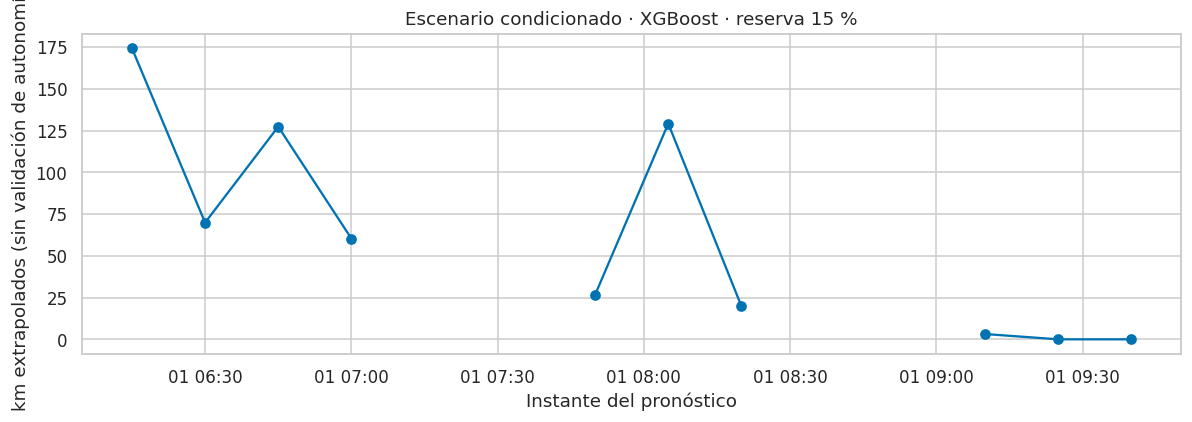

In [ ]:
autonomia = meta_test[['instante_prediccion', 'id_ruta', 'soc_actual_pct', 'capacidad_actual_kwh']].copy()
autonomia['rendimiento_previsto_km_kwh'] = rend_pred[MODELO_ELEGIDO]
for reserva in sorted({SOC_RESERVA, 15., 20.}):
    disponible = autonomia['capacidad_actual_kwh'] * np.maximum(0, (autonomia['soc_actual_pct'] - reserva) / 100)
    autonomia[f'autonomia_condicional_reserva_{reserva:g}_km'] = (disponible * autonomia['rendimiento_previsto_km_kwh']).where(disponible > 0, 0.)
display(autonomia.head(10))

COLUMNA_AUTONOMIA = f'autonomia_condicional_reserva_{SOC_RESERVA:g}_km'
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(autonomia.loc[en_dia, 'instante_prediccion'], autonomia.loc[en_dia, COLUMNA_AUTONOMIA], 'o-')
ax.set(title=f'Escenario condicionado · {MODELO_ELEGIDO} · reserva {SOC_RESERVA:g} %',
       ylabel='km extrapolados (sin validación de autonomía)', xlabel='Instante del pronóstico')
plt.tight_layout()
plt.show()

## 24. Resumen final, límites de interpretación y exportación

### Resumen calculado


In [ ]:
metricas_elegido = {
    obj: metricas_fisicas.query("particion == 'test' and objetivo == @obj and modelo == @MODELO_ELEGIDO").iloc[0]
    for obj in ['energia_neta', 'distancia']
}
filas_rend_elegido = metricas_rendimiento[metricas_rendimiento['modelo'] == MODELO_ELEGIDO]
if (filas_rend_elegido['evaluacion'] == 'interseccion_comun').any():
    filas_rend_elegido = filas_rend_elegido[filas_rend_elegido['evaluacion'] == 'interseccion_comun']
fila_rend = filas_rend_elegido.iloc[0]

resumen_final = pd.Series({
    'autobuses_entrenamiento': ', '.join(BUSES_ENTRENAMIENTO),
    'autobus_test_no_visto': BUS_TEST,
    'jornadas_train_por_bus': 30 - JORNADAS_VALIDACION,
    'jornadas_validacion_por_bus': JORNADAS_VALIDACION,
    'ventanas_train/validacion/test': f"{len(ventanas['train']['y'])}/{len(ventanas['validacion']['y'])}/{len(ventanas['test']['y'])}",
    'horizonte_min': HORIZONTE,
    'modelo_elegido_en_validacion': MODELO_ELEGIDO,
    'test_energia_RMSE_kWh': round(float(metricas_elegido['energia_neta'].RMSE), 4),
    'test_energia_MAE_kWh': round(float(metricas_elegido['energia_neta'].MAE), 4),
    'test_energia_R2': round(float(metricas_elegido['energia_neta'].R2), 4),
    'test_distancia_RMSE_km': round(float(metricas_elegido['distancia'].RMSE), 4),
    'test_rendimiento_RMSE_km_kWh': round(float(fila_rend.RMSE), 4),
    'test_rendimiento_MAPE_pct': round(float(fila_rend.MAPE_pct), 2),
    'casos_rendimiento_comunes': int(mascara_comun.sum()),
    'autonomia': 'Proyección condicionada; sin validación de alcance real',
    'soh': 'No evaluable sin etiquetas' if resultados_soh is None else 'Módulo externo ejecutado; revisar suficiencia',
}, name='resultado')
display(resumen_final.to_frame())

,resultado
autobuses_entrenamiento,"BUS3107, BUS3135"
autobus_test_no_visto,BUS3125
jornadas_train_por_bus,24
jornadas_validacion_por_bus,6
ventanas_train/validacion/test,1584/144/360
horizonte_min,15
modelo_elegido_en_validacion,XGBoost
test_energia_RMSE_kWh,0.275
test_energia_MAE_kWh,0.194
test_energia_R2,0.994


In [ ]:
EXPORTAR = False

if EXPORTAR:
    import datetime
    import joblib

    raiz = Path(CARPETA_DRIVE) / 'datasets_filtrados' if EN_COLAB else Path.cwd()
    salida = raiz / ('TFM_BUSES_' + datetime.datetime.now().strftime('%Y%m%d_%H%M%S'))
    salida.mkdir(parents=True, exist_ok=False)

    for nombre, tabla in partes.items():
        tabla.to_csv(salida / f'telemetria_{nombre}.csv', index=False)
    detalle.to_csv(salida / 'predicciones_test.csv', index=False)
    metricas_fisicas.to_csv(salida / 'metricas_energia_distancia.csv', index=False)
    metricas_rendimiento.to_csv(salida / 'metricas_rendimiento.csv', index=False)
    tabla_final_test.to_csv(salida / 'tabla_final_test.csv')
    tabla_cobertura.to_csv(salida / 'cobertura_rendimiento.csv', index=False)
    tabla_ic.to_csv(salida / 'intervalos_bootstrap.csv', index=False)
    seleccion.to_csv(salida / 'seleccion_validacion.csv', index=False)
    autonomia.to_csv(salida / 'autonomia_condicionada.csv', index=False)
    conclusiones_fase1.to_csv(salida / 'resumen_exploracion.csv')

    red_lstm.save(salida / 'lstm_energia_distancia.keras')
    red_ann.save(salida / 'ann_energia_distancia.keras')
    for j, m in enumerate(xgb_modelos):
        m.save_model(salida / f'xgboost_{j}.json')
    joblib.dump({'escalador_x': escalador_x, 'escalador_y': escalador_y, 'codificador_ruta': codificador_pred,
                 'escalador_ann': escalador_ann, 'svr': svr_modelo, 'comparativos': comparativos,
                 'media_ruta': base_ruta, 'media_global': base_global}, salida / 'preprocesamiento_y_modelos.joblib')

    configuracion = {
        'features': FEATURES, 'nombres_tabulares': NOMBRES_TABULARES, 'historial': HISTORIAL, 'horizonte': HORIZONTE,
        'semilla': SEMILLA, 'umbral_energia': E_MIN, 'umbral_distancia': D_MIN, 'reserva_soc': SOC_RESERVA,
        'modelo_elegido': MODELO_ELEGIDO, 'versiones': VERSIONES,
        'roles': ROL_POR_BUS,
        'sha256_csv': {bus: hashlib.sha256(ruta.read_bytes()).hexdigest() for bus, ruta in rutas_csv.items()},
    }
    (salida / 'configuracion.json').write_text(json.dumps(configuracion, indent=2, default=str), encoding='utf-8')
    print('Resultados exportados en:', salida)
else:
    print('Exportación desactivada. Pon EXPORTAR = True después de revisar los resultados.')

Exportación desactivada. Pon EXPORTAR = True después de revisar los resultados.
